# RG-CBM: descriptor-grounded visual concept bottleneck — Kaggle

CUB-200-2011, Oxford-IIIT Pet and MRI share the original architecture: EfficientNet-B1 →
128-dimensional projection → cosine-matched prototypes → 16 calibrated pooled concepts → sparse linear classifier.
The three guided groups model edge, texture and image-derived region priors; the fourth is unguided.
Names are selected from measured validation associations, without asserting tumor anatomy or bird parts.

Use the supplied README and research methodology. This notebook does not contain fabricated research
results. Full training and independent held-out evaluation must run on your GPU. Resume by rerunning
the same configuration; incompatible checkpoints are rejected. Change RUN_NAME for a new experiment.
Run All executes the first dataset's detailed cells, then the automatic queue processes every
remaining dataset and writes a combined summary. Concept calibration is an explicit protocol
revision; it uses training running statistics fixed at inference, and preserves the linear bottleneck.


In [1]:
# Run All trains/evaluates these datasets in order, with independent models/results.
RUN_ALL_DATASETS = True
DATASETS = ['cub', 'pets', 'brain_mri']
DATASET = DATASETS[0]           # Detailed figures below preview the first dataset.
RUN_TAG = 'calibrated_v3'       # New protocol: preserves all older run folders/checkpoints.
SEED = 42                      # Repeat independent full runs with 42, 43, 44.
NUM_CONCEPTS = 16               # Capacity ablation: 16, 32, 64.
BATCH_SIZE = 2                 # 32 GB GPU: start here; lower if CUDA memory is exhausted.
HEAD_EPOCHS = 8
FINETUNE_EPOCHS = 30
HEAD_LR = 2e-3
FINETUNE_BACKBONE_LR = 2e-5
FINETUNE_HEAD_LR = 1e-3
CONCEPT_NORMALIZATION = 'running_standardize'  # 'none' reproduces the old pooling path.
CHECKPOINT_EVERY_EPOCHS = 5
KEEP_EPOCH_CHECKPOINTS = 3      # Per stage; 0 retains all periodic snapshots.
SMOKE_TEST = True              # True executes two real training batches per stage; not paper results.
LLM_BACKEND = 'template'        # 'local_qwen' (offline-capable) or 'gemini' (online key required).
LLM_DEVICE = 'cpu'              # 'cuda' also works; release training tensors before loading Qwen.
RUN_NAME = f'{DATASET}_K{NUM_CONCEPTS}_seed{SEED}_{RUN_TAG}' + ('_smoke' if SMOKE_TEST else '')
print('Dataset:', DATASET, 'run:', RUN_NAME)

RUN_TAG += '_cloud_validation_kaggle'
RUN_NAME = f'{DATASET}_K{NUM_CONCEPTS}_seed{SEED}_{RUN_TAG}_smoke'
import sys
sys.path.insert(0,'/workspace/RGCBM_MultiDataset/tests')
from drive_fixture import install_cloud_fixture
fixture=install_cloud_fixture('Kaggle','/tmp/rgcbm-v3-cloud-release/kaggle','/workspace/RGCBM_MultiDataset')


Dataset: cub run: cub_K16_seed42_calibrated_v3_smoke


Internet access is required for initial preparation. Enable a GPU in runtime settings. Dependencies are pinned; restart the kernel/runtime if an already imported package version changed.

In [2]:
"""Bootstrap managed cloud runtimes; preserve a working GPU build when possible."""
from importlib import metadata
import subprocess
import sys


def prepare_cloud_runtime(requirements):
    if not (3, 10) <= sys.version_info[:2] <= (3, 13):
        raise RuntimeError('This notebook supports Python 3.10–3.13. Select a supported cloud runtime before installation.')
    print('Python compatibility profile:', 'TensorFlow 2.20.0 (Python 3.13)' if sys.version_info[:2] >= (3, 13) else 'TensorFlow 2.19.1 (Python 3.10–3.12)')
    modules = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
               'PIL': 'pillow', 'sklearn': 'scikit-learn', 'tensorflow': 'tensorflow',
               'google.protobuf': 'protobuf', 'transformers': 'transformers',
               'accelerate': 'accelerate', 'huggingface_hub': 'huggingface-hub',
               'tokenizers': 'tokenizers', 'safetensors': 'safetensors',
               'tensorflow_datasets': 'tensorflow-datasets', 'medmnist': 'medmnist',
               'kagglehub': 'kagglehub', 'google.genai': 'google-genai',
               'pyarrow': 'pyarrow'}
    loaded = {}
    for module, distribution in modules.items():
        if module in sys.modules:
            version = getattr(sys.modules[module], '__version__', None)
            if version is None:
                try: version = metadata.version(distribution)
                except metadata.PackageNotFoundError: version = None
            loaded[distribution] = str(version)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--upgrade-strategy',
                           'only-if-needed', *requirements])
    changed = [name for name, version in loaded.items() if version != metadata.version(name)]
    if changed:
        raise RuntimeError('Restart the runtime/kernel, then rerun from the first cell. Already loaded packages changed: ' + ', '.join(changed))
    capability = None
    try:
        import torch
        import torchvision
        if tuple(map(int, torch.__version__.split('+')[0].split('.')[:2])) < (2, 7):
            raise RuntimeError('PyTorch 2.7 or newer is required.')
        # This also detects incompatible torchvision compiled operators.
        torchvision.ops.nms(torch.tensor([[0., 0., 1., 1.]]), torch.tensor([1.]), 0.5)
        if torch.cuda.is_available():
            capability = torch.cuda.get_device_capability(0)
            test = torch.ones(2, device='cuda')
            assert float((test + 1).sum()) == 4.
            torch.cuda.synchronize()
    except (ImportError, OSError, RuntimeError, AttributeError, AssertionError) as exc:
        # CUDA 12.6 keeps older cloud GPU architectures; Blackwell requires 12.8.
        flavor = 'cu128' if capability and capability[0] >= 10 else 'cu126'
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--upgrade',
                               'torch==2.7.1', 'torchvision==0.22.1', '--index-url',
                               'https://download.pytorch.org/whl/' + flavor])
        raise RuntimeError('Repaired the PyTorch/torchvision pair. Restart this runtime/kernel and rerun from the first cell. Original check: ' + str(exc)[:180]) from None
    print('Cloud stack checked:', torch.__version__, torchvision.__version__, 'CUDA', torch.version.cuda)

prepare_cloud_runtime(['tensorflow==2.19.1; python_version < "3.13"', 'tensorflow==2.20.0; python_version >= "3.13"', 'numpy>=1.26,<2.2', 'pyarrow==19.0.1', 'pandas==2.2.3', 'scikit-learn==1.5.2', 'matplotlib==3.9.2', 'Pillow==11.0.0', 'medmnist==3.0.2', 'kagglehub==0.4.3', 'tensorflow-datasets==4.9.9', 'tensorflow-metadata==1.16.1', 'protobuf==5.29.6', 'googleapis-common-protos==1.69.2', 'proto-plus==1.26.1', 'google-api-core==2.24.2', 'opencv-python-headless==4.10.0.84', 'tqdm==4.67.1', 'PyYAML==6.0.2', 'transformers==4.51.3', 'accelerate==1.6.0', 'huggingface-hub==0.30.2', 'safetensors==0.5.3', 'google-api-python-client==2.166.0', 'google-auth-oauthlib==1.2.2', 'google-genai==1.11.0'])
from pathlib import Path
import os, shutil
ROOT = Path(os.getenv('RGCBM_ROOT', '/content/rgcbm' if 'Kaggle' == 'Colab' else '/kaggle/working/rgcbm'))
ROOT.mkdir(parents=True, exist_ok=True)
ONLINE = True
SYNC_CALLBACK = None


Python compatibility profile: TensorFlow 2.20.0 (Python 3.13)


Cloud stack checked: 2.7.1+cpu 0.22.1+cpu CUDA None


The shared implementation is embedded for portability. The original research notebook is preserved. Working code is materialized in a separate folder; data, assets and results remain outside it.

In [3]:
import json, sys
CODE = {'rgcbm/__init__.py': '"""Radiomics-guided concept bottleneck research pipeline."""\n__version__ = \'3.0.0\'\n', 'rgcbm/ablations.py': 'from pathlib import Path\nimport gc\nimport pandas as pd\nimport torch\nfrom .core import Config\nfrom .data import build_manifest, atomic_json\nfrom .train import fit\nfrom .evaluate import ground_concepts, evaluate\n\nVARIANTS = [\'full\', \'unguided\', \'no_edge\', \'no_texture\', \'no_region\', \'no_diversity\', \'no_decorrelation\', \'no_stability\', \'no_sparsity\', \'no_finetune\', \'no_standardization\', \'K32\', \'K64\']\n\n\ndef variant_config(base, variant, seed=None):\n    if variant not in VARIANTS: raise ValueError(variant)\n    cfg = Config(**base.to_dict())\n    if seed is not None: cfg.seed = seed\n    if variant == \'unguided\': cfg.edge = cfg.texture = cfg.morphology = 0.\n    for name, field in [(\'no_edge\', \'edge\'), (\'no_texture\', \'texture\'), (\'no_region\', \'morphology\'), (\'no_diversity\', \'diversity\'), (\'no_decorrelation\', \'disentangle\'), (\'no_stability\', \'stability\')]:\n        if variant == name: setattr(cfg, field, 0.)\n    if variant == \'no_sparsity\': cfg.activation_l1 = cfg.classifier_l1 = 0.\n    if variant == \'no_finetune\': cfg.finetune_epochs = 0\n    if variant == \'no_standardization\': cfg.concept_normalization = \'none\'\n    if variant in [\'K32\', \'K64\']: cfg.concepts = int(variant[1:])\n    return cfg\n\n\ndef run_ablation_suite(root, base_config, variants=None, seeds=(42,), device=None, sync_callback=None):\n    """Same data/preprocessing/budget per matched variant; separate reproducible run identities."""\n    root = Path(root)\n    variants = VARIANTS if variants is None else list(variants)\n    records = []\n    profile = \'calibrated_v3\' if base_config.concept_normalization == \'running_standardize\' else \'legacy\'\n    summary = root / \'results\' / f\'{base_config.dataset}_ablation_summary_{profile}\'\n    summary.mkdir(parents=True, exist_ok=True)\n    for seed in seeds:\n        manifest = build_manifest(root, base_config.dataset, seed, base_config.validation_fraction)\n        for variant in variants:\n            cfg = variant_config(base_config, variant, seed)\n            smoke = cfg.max_train_batches is not None or cfg.max_validation_batches is not None\n            name = f\'{cfg.dataset}_ablation_{variant}_K{cfg.concepts}_seed{seed}_{profile}\' + (\'_smoke\' if smoke else \'\')\n            print(f\'Running {name}\', flush=True)\n            model, run, status = fit(root, manifest, cfg, device=device, sync_callback=sync_callback, run_name=name)\n            assert status[\'complete\']\n            limit = cfg.max_validation_batches if smoke else None\n            grounding = ground_concepts(model, root, manifest, run, max_batches=limit)\n            metrics = evaluate(model, root, manifest, run, grounding, max_batches=limit)\n            row = {\'variant\': variant, \'seed\': seed, \'concepts\': cfg.concepts, \'software_smoke_only\': smoke, \'run\': name, **metrics}\n            records.append(row)\n            frame = pd.DataFrame(records)\n            frame.to_csv(summary / \'ablation_runs.csv\', index=False)\n            numeric = [\'accuracy\', \'macro_f1\', \'balanced_accuracy\', \'ece_15_bins\', \'positive_margin_probability_drop_mean\', \'random_probability_drop_mean\', \'stability_mae\', \'stability_cosine\']\n            frame.groupby(\'variant\')[numeric].agg([\'mean\', \'std\', \'count\']).to_csv(summary / \'ablation_mean_std.csv\')\n            atomic_json(summary / \'protocol.json\', {\'dataset\': cfg.dataset, \'base_config\': base_config.to_dict(), \'variants\': variants, \'seeds\': list(seeds), \'warning\': \'Use at least three complete seeds for a paper. Test measurements compare preregistered variants; do not tune variants on these test scores.\'})\n            if sync_callback:\n                sync_callback(run)\n                sync_callback(summary)\n            del model\n            gc.collect()\n            if torch.cuda.is_available(): torch.cuda.empty_cache()\n    return pd.DataFrame(records)\n', 'rgcbm/cloud.py': '"""Explicit Google Drive persistence for Colab and Kaggle; never embeds credentials."""\nfrom pathlib import Path\nimport io\nimport json\nimport os\nfrom .data import atomic_json\n\n\nclass DriveStore:\n    def __init__(self, folder_name=\'RGCBM_MultiDataset\', token_info=None, credentials=None, folder_id=None):\n        from google.oauth2.credentials import Credentials\n        from google.auth.transport.requests import Request\n        from googleapiclient.discovery import build\n        if credentials is None:\n            if token_info is None:\n                token_info = os.getenv(\'GDRIVE_TOKEN_JSON\')\n                if token_info is None:\n                    try:\n                        from kaggle_secrets import UserSecretsClient\n                        token_info = UserSecretsClient().get_secret(\'GDRIVE_TOKEN_JSON\')\n                    except Exception:\n                        raise RuntimeError(\'Add the OAuth token JSON securely as Kaggle secret GDRIVE_TOKEN_JSON. See docs/CLOUD_STORAGE.md.\') from None\n            credentials = Credentials.from_authorized_user_info(json.loads(token_info) if isinstance(token_info, str) else token_info)\n        if not credentials.valid:\n            if credentials.expired and credentials.refresh_token:\n                credentials.refresh(Request())\n            else:\n                raise RuntimeError(\'Google Drive credentials cannot refresh. Reauthorize using authorize_drive.py.\')\n        self.service = build(\'drive\', \'v3\', credentials=credentials, cache_discovery=False)\n        folder_id = folder_id or os.getenv(\'RGCBM_DRIVE_FOLDER_ID\')\n        if folder_id:\n            info = self.service.files().get(fileId=folder_id, fields=\'id,mimeType,trashed\').execute()\n            if info.get(\'trashed\') or info.get(\'mimeType\') != \'application/vnd.google-apps.folder\':\n                raise RuntimeError(\'RGCBM_DRIVE_FOLDER_ID must identify an accessible, active Drive folder.\')\n            self.folder = info[\'id\']\n        else:\n            self.folder = self._folder(folder_name, None)\n        self.child_folders = {}\n        self._uploaded = {}\n\n    def _list(self, query):\n        rows, token = [], None\n        while True:\n            result = self.service.files().list(q=query, spaces=\'drive\', fields=\'nextPageToken,files(id,name,mimeType,modifiedTime,size)\', pageToken=token, pageSize=1000).execute()\n            rows.extend(result.get(\'files\', []))\n            token = result.get(\'nextPageToken\')\n            if not token: return rows\n\n    @staticmethod\n    def _quote(value):\n        return str(value).replace(\'\\\\\', \'\\\\\\\\\').replace("\'", "\\\\\'")\n\n    def _folder(self, name, parent):\n        query = f"name=\'{self._quote(name)}\' and mimeType=\'application/vnd.google-apps.folder\' and trashed=false"\n        if parent: query += f" and \'{parent}\' in parents"\n        else: query += " and \'root\' in parents"\n        found = self._list(query)\n        if len(found) > 1:\n            raise RuntimeError(f\'Multiple Drive folders named {name}; resolve the ambiguity in Drive.\')\n        if found: return found[0][\'id\']\n        metadata = {\'name\': name, \'mimeType\': \'application/vnd.google-apps.folder\'}\n        if parent: metadata[\'parents\'] = [parent]\n        return self.service.files().create(body=metadata, fields=\'id\').execute()[\'id\']\n\n    def folder_for(self, relative):\n        parent = self.folder\n        accumulated = \'\'\n        for part in Path(relative).parts:\n            accumulated += \'/\' + part\n            if accumulated not in self.child_folders:\n                self.child_folders[accumulated] = self._folder(part, parent)\n            parent = self.child_folders[accumulated]\n        return parent\n\n    def upload(self, path, relative_folder=\'\'):\n        from googleapiclient.http import MediaFileUpload\n        path = Path(path)\n        cache_key = (str(path.resolve()), str(relative_folder))\n        stamp = (path.stat().st_size, path.stat().st_mtime_ns)\n        previous = self._uploaded.get(cache_key)\n        if previous and previous[:2] == stamp:\n            return previous[2]\n        parent = self.folder_for(relative_folder)\n        found = self._list(f"name=\'{self._quote(path.name)}\' and \'{parent}\' in parents and trashed=false")\n        if len(found) > 1: raise RuntimeError(\'Ambiguous Drive file name.\')\n        media = MediaFileUpload(str(path), resumable=True, chunksize=8 * 1024 * 1024)\n        if found:\n            request = self.service.files().update(fileId=found[0][\'id\'], media_body=media, fields=\'id\')\n        else:\n            request = self.service.files().create(body={\'name\': path.name, \'parents\': [parent]}, media_body=media, fields=\'id\')\n        response = None\n        while response is None:\n            _, response = request.next_chunk(num_retries=3)\n        if (path.stat().st_size, path.stat().st_mtime_ns) != stamp:\n            raise RuntimeError(\'File changed while uploading; retry sync after the local save completes.\')\n        self._uploaded[cache_key] = (*stamp, response[\'id\'])\n        return response[\'id\']\n\n    def download(self, name, target, relative_folder=\'\'):\n        from googleapiclient.http import MediaIoBaseDownload\n        parent = self.folder_for(relative_folder)\n        found = self._list(f"name=\'{self._quote(name)}\' and \'{parent}\' in parents and trashed=false")\n        if not found: return False\n        if len(found) > 1: raise RuntimeError(\'Ambiguous Drive file name.\')\n        target = Path(target); target.parent.mkdir(parents=True, exist_ok=True)\n        partial = target.with_suffix(target.suffix + \'.partial\')\n        with partial.open(\'wb\') as output:\n            downloader = MediaIoBaseDownload(output, self.service.files().get_media(fileId=found[0][\'id\']), chunksize=8 * 1024 * 1024)\n            done = False\n            while not done: _, done = downloader.next_chunk(num_retries=3)\n        os.replace(partial, target)\n        return True\n\n    def sync_run(self, run):\n        run = Path(run)\n        # Upload the resume commit after all companion state, never before it.\n        for path in sorted(run.rglob(\'*\'), key=lambda p: (p.name == \'last.pt\', str(p))):\n            if path.is_file() and path.suffix != \'.tmp\':\n                if path.name == \'remote_sync_error.json\': continue\n                self.upload(path, str(Path(\'results\') / run.name / path.relative_to(run).parent))\n        error = run / \'remote_sync_error.json\'\n        if error.exists(): error.unlink()\n\n    def restore_run(self, root, run_name):\n        # Resume training artifacts before fit; arrays/figures can be regenerated.\n        run = Path(root) / \'results\' / run_name\n        if (run / \'last.pt\').is_file():\n            if not (run / \'configuration.json\').is_file():\n                raise RuntimeError(\'Local checkpoint has no configuration. Preserve it and recover its matching configuration before restoring.\')\n            # A failed remote sync must never roll newer local progress backwards.\n            return run\n        remote = str(Path(\'results\') / run_name)\n        for name in [\'configuration.json\', \'best.pt\', \'head_best.pt\', \'finetune_best.pt\', \'history.json\', \'training_status.json\', \'last.pt\']:\n            self.download(name, run / name, remote)\n        return run\n\n    def ensure_dataset(self, root, name):\n        archive = Path(root) / \'data\' / f\'{name}.zip\'\n        parent = self.folder_for(\'datasets\')\n        found = self._list(f"name=\'{self._quote(archive.name)}\' and \'{parent}\' in parents and trashed=false")\n        if len(found) > 1: raise RuntimeError(\'Ambiguous dataset archive in Drive.\')\n        if not archive.exists() and found:\n            self.download(archive.name, archive, \'datasets\')\n        if not archive.exists():\n            from .data import prepare_data\n            prepare_data(root, name, online=True)\n        if not found:\n            self.upload(archive, \'datasets\')\n        return archive\n\n    def sync_assets(self, root, include_llm=False):\n        assets = Path(root) / \'assets\'\n        for name in [\'efficientnet_b1_imagenet.pth\', \'backbone_manifest.json\']:\n            self.upload(assets / name, \'assets\')\n        if include_llm:\n            self.upload(assets / \'llm_manifest.json\', \'assets\')\n            for path in sorted((assets / \'qwen2.5-1.5b-instruct\').iterdir()):\n                if path.is_file() and (path.suffix in [\'.json\', \'.txt\', \'.model\', \'.safetensors\', \'.md\'] or path.name.startswith(\'LICENSE\')):\n                    self.upload(path, \'assets/qwen2.5-1.5b-instruct\')\n\n    def restore_assets(self, root, include_llm=False):\n        assets = Path(root) / \'assets\'\n        for name in [\'efficientnet_b1_imagenet.pth\', \'backbone_manifest.json\'] + ([\'llm_manifest.json\'] if include_llm else []):\n            if not (assets / name).is_file(): self.download(name, assets / name, \'assets\')\n        if include_llm:\n            folder = \'assets/qwen2.5-1.5b-instruct\'\n            for item in self._list(f"\'{self.folder_for(folder)}\' in parents and trashed=false"):\n                name = item[\'name\']\n                if Path(name).name != name or \'/\' in name or \'\\\\\' in name:\n                    raise RuntimeError(\'Unsafe Drive asset filename.\')\n                if item.get(\'mimeType\') == \'application/vnd.google-apps.folder\': continue\n                if Path(name).suffix not in [\'.json\', \'.txt\', \'.model\', \'.safetensors\', \'.md\'] and not name.startswith(\'LICENSE\'): continue\n                target = assets / \'qwen2.5-1.5b-instruct\' / name\n                if not target.is_file(): self.download(name, target, folder)\n', 'rgcbm/core.py': 'from dataclasses import dataclass, asdict\nfrom pathlib import Path\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\nfrom torchvision.models import efficientnet_b1, EfficientNet_B1_Weights\n\n\n@dataclass\nclass Config:\n    dataset: str = \'cub\'\n    seed: int = 42\n    concepts: int = 16\n    projection: int = 128\n    image_size: int = 240\n    batch_size: int = 24\n    workers: int = 0  # Safe in Windows/Jupyter; increase only in a guarded script.\n    head_epochs: int = 20\n    finetune_epochs: int = 20\n    finetune_blocks: int = 3\n    head_lr: float = 4e-4\n    finetune_lr: float = 8e-6\n    finetune_head_lr: float | None = None  # None preserves the original shared LR.\n    concept_normalization: str = \'none\'  # Legacy checkpoint-compatible default.\n    validation_fraction: float = 0.1\n    dropout: float = 0.10\n    edge: float = 0.18\n    texture: float = 0.10\n    morphology: float = 0.08\n    diversity: float = 0.02\n    disentangle: float = 0.01\n    activation_l1: float = 5e-5\n    stability: float = 0.02\n    classifier_l1: float = 5e-6\n    classification_only_epochs: int = 3\n    ramp_epochs: int = 5\n    checkpoint_every_batches: int = 50\n    checkpoint_every_epochs: int = 5\n    keep_epoch_checkpoints: int = 3  # Per stage; 0 keeps every periodic snapshot.\n    show_progress: bool = True\n    patience: int = 8\n    mixed_precision: bool = True\n    pretrained: bool = True\n    max_train_batches: int | None = None\n    max_validation_batches: int | None = None\n\n    def __post_init__(self):\n        if self.concepts < 4 or self.concepts % 4:\n            raise ValueError(\'Concept count must be a positive multiple of four.\')\n        if self.batch_size < 2:\n            raise ValueError(\'Training batches need at least two images for concept decorrelation.\')\n        if self.head_epochs < 1 or self.finetune_epochs < 0:\n            raise ValueError(\'Use at least one head epoch and nonnegative fine-tuning epochs.\')\n        if self.workers < 0 or not 0 < self.validation_fraction < 1:\n            raise ValueError(\'Invalid loader/split configuration.\')\n        if self.concept_normalization not in [\'none\', \'running_standardize\']:\n            raise ValueError(\'Unknown concept normalization.\')\n        if min(self.head_lr, self.finetune_lr) <= 0 or (self.finetune_head_lr is not None and self.finetune_head_lr <= 0):\n            raise ValueError(\'Learning rates must be positive.\')\n        if self.checkpoint_every_batches < 1 or self.checkpoint_every_epochs < 1 or self.keep_epoch_checkpoints < 0:\n            raise ValueError(\'Invalid checkpoint interval/retention.\')\n\n    def to_dict(self):\n        return asdict(self)\n\n\ndef training_config(profile=\'calibrated_v3\', **overrides):\n    if profile == \'calibrated_v3\':\n        values = dict(head_epochs=8, finetune_epochs=30, head_lr=2e-3, finetune_lr=2e-5,\n                      finetune_head_lr=1e-3, concept_normalization=\'running_standardize\')\n    elif profile == \'legacy\':\n        values = {}\n    else:\n        raise ValueError(\'Use calibrated_v3 or legacy.\')\n    values.update(overrides)\n    return Config(**values)\n\n\ndef normalize_map(x):\n    low = x.amin((2, 3), keepdim=True)\n    high = x.amax((2, 3), keepdim=True)\n    return (x - low) / (high - low).clamp_min(1e-8)\n\n\ndef priors(images):\n    """Image-derived weak priors on unnormalized RGB [0,1]; never segmentation labels."""\n    x = images.float().clamp(0, 1)\n    gray = (x * x.new_tensor([0.299, 0.587, 0.114])[None, :, None, None]).sum(1, keepdim=True)\n    sx = gray.new_tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]])[None, None]\n    sy = sx.transpose(2, 3)\n    padded = F.pad(gray, (1, 1, 1, 1), mode=\'reflect\')\n    sobel = (F.conv2d(padded, sx).square() + F.conv2d(padded, sy).square() + 1e-8).sqrt()\n    laplace = gray.new_tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]])[None, None]\n    edge = normalize_map(0.7 * normalize_map(sobel) + 0.3 * normalize_map(F.conv2d(padded, laplace).abs()))\n    mean = F.avg_pool2d(gray, 9, stride=1, padding=4)\n    var = (F.avg_pool2d(gray.square(), 9, stride=1, padding=4) - mean.square()).clamp_min(0)\n    local_sd = normalize_map((var + 1e-8).sqrt())\n    right = F.pad(gray[:, :, :, 1:], (0, 1, 0, 0), mode=\'replicate\')\n    down = F.pad(gray[:, :, 1:, :], (0, 0, 0, 1), mode=\'replicate\')\n    diff = 0.5 * ((gray - right).square() + (gray - down).square())\n    contrast = normalize_map(F.avg_pool2d(diff, 9, stride=1, padding=4))\n    homogeneity = normalize_map(F.avg_pool2d(1 / (1 + 16 * diff), 9, stride=1, padding=4))\n    texture = normalize_map(0.75 * local_sd + 0.25 * normalize_map(0.75 * contrast + 0.25 * (1 - homogeneity)))\n    gm, gs = gray.mean((2, 3), keepdim=True), gray.std((2, 3), keepdim=True, correction=0)\n    pseudo = (gray > gm + 0.45 * gs).float() + 0.35 * (gray < gm - 0.90 * gs).float()\n    morphology = normalize_map(F.avg_pool2d(pseudo, 7, stride=1, padding=3))\n    return {\'edge\': edge.detach(), \'texture\': texture.detach(), \'morphology\': morphology.detach(), \'intensity\': normalize_map(gray).detach()}\n\n\nclass RGCBM(nn.Module):\n    def __init__(self, num_classes, config: Config, asset_dir=None):\n        super().__init__()\n        self.config = config\n        self.num_classes = num_classes\n        backbone = efficientnet_b1(weights=None)\n        if config.pretrained:\n            weights_path = Path(asset_dir or \'assets\') / \'efficientnet_b1_imagenet.pth\'\n            if not weights_path.is_file():\n                raise FileNotFoundError(f\'Missing offline backbone asset: {weights_path}. Run prepare_assets.py online first.\')\n            backbone.load_state_dict(torch.load(weights_path, map_location=\'cpu\', weights_only=True))\n        self.backbone = backbone.features\n        self.projection = nn.Sequential(nn.Conv2d(1280, config.projection, 1, bias=False), nn.BatchNorm2d(config.projection), nn.SiLU())\n        self.prototypes = nn.Parameter(torch.randn(config.concepts, config.projection) * 0.02)\n        self.dropout = nn.Dropout(config.dropout)\n        self.classifier = nn.Linear(config.concepts, num_classes)\n        if config.concept_normalization == \'running_standardize\':\n            self.concept_norm = nn.BatchNorm1d(config.concepts, affine=False)\n        self.register_buffer(\'image_mean\', torch.tensor([0.485, 0.456, 0.406])[None, :, None, None])\n        self.register_buffer(\'image_std\', torch.tensor([0.229, 0.224, 0.225])[None, :, None, None])\n        self.stage = \'head\'\n        self.set_stage(\'head\')\n\n    def set_stage(self, stage):\n        self.stage = stage\n        for p in self.backbone.parameters():\n            p.requires_grad_(False)\n        if stage == \'finetune\':\n            for block in list(self.backbone.children())[-self.config.finetune_blocks:]:\n                for p in block.parameters():\n                    p.requires_grad_(True)\n        elif stage != \'head\':\n            raise ValueError(stage)\n        for module in self.backbone.modules():\n            if isinstance(module, nn.BatchNorm2d):\n                for p in module.parameters():\n                    p.requires_grad_(False)\n        self.train(self.training)\n\n    def train(self, mode=True):\n        super().train(mode)\n        if hasattr(self, \'backbone\'):\n            if self.stage == \'head\':\n                self.backbone.eval()\n            for module in self.backbone.modules():\n                if isinstance(module, nn.BatchNorm2d):\n                    module.eval()\n        return self\n\n    def concepts_from(self, images):\n        z = self.projection(self.backbone((images - self.image_mean) / self.image_std))\n        features = F.normalize(z, dim=1)\n        p = F.normalize(self.prototypes, dim=1)\n        maps = torch.sigmoid(4 * torch.einsum(\'bdhw,kd->bkhw\', features, p))\n        concepts = maps.mean((2, 3))\n        if self.config.concept_normalization == \'running_standardize\':\n            # Training-only running statistics; fixed at evaluation, no class bypass.\n            concepts = torch.sigmoid(self.concept_norm(concepts))\n        return maps, concepts\n\n    def forward(self, images):\n        maps, concepts = self.concepts_from(images)\n        logits = self.classifier(self.dropout(concepts))\n        return {\'maps\': maps, \'concepts\': concepts, \'logits\': logits, \'probs\': logits.softmax(1)}\n\n    def predict_from_concepts(self, concepts):\n        logits = self.classifier(concepts)\n        return logits, logits.softmax(1)\n\n\nclass BackboneClassifier(RGCBM):\n    """Matched EfficientNet-B1 + pooled-feature linear baseline, with no concept bottleneck."""\n    def __init__(self, num_classes, config, asset_dir=None):\n        super().__init__(num_classes, config, asset_dir)\n        self.projection = nn.Identity()\n        self.register_parameter(\'prototypes\', None)\n        self.classifier = nn.Linear(1280, num_classes)\n\n    def forward(self, images):\n        features = self.backbone((images - self.image_mean) / self.image_std).mean((2, 3))\n        logits = self.classifier(self.dropout(features))\n        return {\'logits\': logits, \'probs\': logits.softmax(1)}\n\n\ndef loss_terms(model, images, targets, output, class_weights, scale):\n    """Same loss families as original RG-CBM; consistent inference-mode stability views."""\n    cfg = model.config\n    maps, c = output[\'maps\'].float(), output[\'concepts\'].float()\n    descriptor = priors(images)\n    group = cfg.concepts // 4\n    losses = {\'classification\': F.cross_entropy(output[\'logits\'].float(), targets, weight=class_weights)}\n    for i, name in enumerate([\'edge\', \'texture\', \'morphology\']):\n        target_map = F.interpolate(descriptor[name], size=maps.shape[-2:], mode=\'bilinear\', align_corners=False)\n        losses[name] = F.mse_loss(maps[:, i * group:(i + 1) * group].mean(1, keepdim=True), target_map)\n    p = F.normalize(model.prototypes.float(), dim=1)\n    off_diag = 1 - torch.eye(cfg.concepts, device=p.device)\n    losses[\'diversity\'] = ((p @ p.T) * off_diag).square().mean()\n    centered = c - c.mean(0, keepdim=True)\n    cov = centered.T @ centered / max(c.shape[0] - 1, 1)\n    std = (cov.diag() + 1e-6).sqrt()\n    corr = cov / (std[:, None] * std[None, :] + 1e-6)\n    losses[\'disentangle\'] = (corr * off_diag).square().mean()\n    losses[\'activation_l1\'] = c.abs().mean()\n    losses[\'classifier_l1\'] = model.classifier.weight.abs().sum()\n    losses[\'stability\'] = c.new_zeros(())\n    if cfg.stability and scale:\n        mode = model.training\n        model.eval()\n        # Both sides retain gradients through the same inference path.\n        _, base = model.concepts_from(images)\n        _, changed = model.concepts_from((images * 1.02 + 3 / 255).clamp(0, 1))\n        model.train(mode)\n        losses[\'stability\'] = F.mse_loss(base.float(), changed.float())\n    auxiliary = sum(getattr(cfg, name) * losses[name] for name in [\'edge\', \'texture\', \'morphology\', \'diversity\', \'disentangle\', \'activation_l1\', \'stability\'])\n    total = losses[\'classification\'] + scale * auxiliary + cfg.classifier_l1 * losses[\'classifier_l1\']\n    return total, losses\n', 'rgcbm/data.py': 'from pathlib import Path\nimport hashlib\nimport json\nimport os\nimport shutil\nimport urllib.request\nimport zipfile\nimport numpy as np\nimport torch\nfrom PIL import Image\nfrom sklearn.model_selection import train_test_split, StratifiedGroupKFold\nfrom torch.utils.data import Dataset, DataLoader\nfrom torchvision.transforms import functional as TF\nfrom torchvision.transforms import InterpolationMode\n\nSOURCES = {\n    \'cub\': {\'slug\': \'wenewone/cub2002011\', \'official\': \'https://data.caltech.edu/records/65de6-vp158\', \'classes\': 200, \'description\': \'CUB-200-2011; official image-level train/test split; attributes/boxes evaluation only\'},\n    \'pets\': {\'slug\': \'julinmaloof/the-oxfordiiit-pet-dataset\', \'official\': \'https://www.robots.ox.ac.uk/~vgg/data/pets/\', \'classes\': 37, \'description\': \'Oxford-IIIT Pet; official trainval/test split; trimaps evaluation only\'},\n    \'brain_mri\': {\'slug\': \'masoudnickparvar/brain-tumor-mri-dataset\', \'official\': \'https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset\', \'classes\': 4, \'description\': \'Kaggle MRI; supplied image-level split, not verified patient-independent\'},\n}\n\n\ndef sha256(path):\n    h = hashlib.sha256()\n    with Path(path).open(\'rb\') as f:\n        while chunk := f.read(1024 * 1024):\n            h.update(chunk)\n    return h.hexdigest()\n\n\ndef atomic_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    tmp = path.with_suffix(path.suffix + \'.tmp\')\n    tmp.write_text(json.dumps(value, indent=2), encoding=\'utf-8\')\n    os.replace(tmp, path)\n\n\ndef prepare_data(root, dataset, online=False):\n    """Retain and reuse complete source archives; never redownload by default."""\n    root = Path(root)\n    data = root / \'data\'\n    data.mkdir(parents=True, exist_ok=True)\n    archive = data / f\'{dataset}.zip\'\n    target = data / dataset\n    marker = target / \'.extracted.json\'\n    if marker.is_file():\n        return target\n    if not archive.is_file():\n        if not online:\n            raise FileNotFoundError(f\'Missing {archive}. Copy the bundled dataset archive or run online preparation.\')\n        url = \'https://www.kaggle.com/api/v1/datasets/download/\' + SOURCES[dataset][\'slug\']\n        partial = archive.with_suffix(\'.partial\')\n        print(f\'Downloading {dataset} from the declared Kaggle mirror...\', flush=True)\n        with urllib.request.urlopen(url, timeout=120) as response, partial.open(\'wb\') as output:\n            if response.headers.get(\'content-type\') != \'application/zip\':\n                raise RuntimeError(\'Dataset endpoint did not return ZIP data.\')\n            shutil.copyfileobj(response, output, 1024 * 1024)\n        os.replace(partial, archive)\n    with zipfile.ZipFile(archive) as source:\n        for entry in source.infolist():\n            if not (target / entry.filename).resolve().is_relative_to(target.resolve()):\n                raise RuntimeError(\'Unsafe archive member path.\')\n            if (entry.external_attr >> 16) & 0o170000 == 0o120000:\n                raise RuntimeError(\'Symbolic links in dataset archive are not supported.\')\n        if source.testzip() is not None:\n            raise RuntimeError(\'Dataset ZIP failed CRC validation.\')\n        target.mkdir(parents=True, exist_ok=True)\n        # This mirror also contains 5.8 GB of unrelated CVPR-2016 text embeddings.\n        # RG-CBM uses the original images, split files, attributes, parts and masks only.\n        members = [m for m in source.infolist() if not (dataset == \'cub\' and m.filename.startswith(\'cvpr2016_cub/\'))]\n        source.extractall(target, members=members)\n    atomic_json(marker, {\'source\': SOURCES[dataset], \'archive_sha256\': sha256(archive)})\n    return target\n\n\ndef _unique_file(root, name):\n    matches = list(Path(root).rglob(name))\n    if len(matches) != 1:\n        raise RuntimeError(f\'Expected exactly one {name}, found {len(matches)} under {root}\')\n    return matches[0]\n\n\ndef _mapping(path, cast=str):\n    result = {}\n    for line in Path(path).read_text().splitlines():\n        if line.strip():\n            key, value = line.split(maxsplit=1)\n            result[int(key)] = cast(value)\n    return result\n\n\ndef build_manifest(root, dataset, seed=42, validation_fraction=0.1):\n    root = Path(root)\n    base = prepare_data(root, dataset, online=False)\n    rows = []\n    def relative(path):\n        return Path(path).relative_to(root).as_posix()\n    if dataset == \'cub\':\n        parent = _unique_file(base, \'images.txt\').parent\n        images = _mapping(parent / \'images.txt\')\n        labels = _mapping(parent / \'image_class_labels.txt\', int)\n        split = _mapping(parent / \'train_test_split.txt\', int)\n        names = _mapping(parent / \'classes.txt\')\n        boxes = _mapping(parent / \'bounding_boxes.txt\', lambda v: list(map(float, v.split())))\n        classes = [names[i] for i in sorted(names)]\n        for image_id, path in sorted(images.items()):\n            rows.append({\'path\': relative(parent / \'images\' / path), \'label\': labels[image_id] - 1, \'class_name\': names[labels[image_id]], \'split\': \'train\' if split[image_id] == 1 else \'test\', \'image_id\': image_id, \'bbox\': boxes[image_id]})\n        if sum(r[\'split\'] == \'train\' for r in rows) != 5994 or sum(r[\'split\'] == \'test\' for r in rows) != 5794:\n            raise RuntimeError(\'CUB archive does not match the official 5994/5794 split.\')\n    elif dataset == \'pets\':\n        annotations = _unique_file(base, \'trainval.txt\').parent\n        # Mirrors normally place images next to annotations; discover unambiguously.\n        candidate = annotations.parent / \'images\'\n        if not candidate.is_dir():\n            candidate = _unique_file(base, \'Abyssinian_1.jpg\').parent\n        label_names = {}\n        for which, filename in [(\'train\', \'trainval.txt\'), (\'test\', \'test.txt\')]:\n            for line in (annotations / filename).read_text().splitlines():\n                if not line.strip() or line.startswith(\'#\'):\n                    continue\n                stem, lab, *_ = line.split()\n                name = stem.rsplit(\'_\', 1)[0]\n                label_names[int(lab)] = name\n                row = {\'path\': relative(candidate / (stem + \'.jpg\')), \'label\': int(lab) - 1, \'class_name\': name, \'split\': which}\n                mask = annotations / \'trimaps\' / (stem + \'.png\')\n                if mask.is_file():\n                    row[\'mask\'] = relative(mask)\n                rows.append(row)\n        classes = [label_names[i] for i in sorted(label_names)]\n        if sum(r[\'split\'] == \'train\' for r in rows) != 3680 or sum(r[\'split\'] == \'test\' for r in rows) != 3669:\n            raise RuntimeError(\'Pet archive does not match the official 3680/3669 split.\')\n    elif dataset == \'brain_mri\':\n        parents = list(base.rglob(\'Training\'))\n        if len(parents) != 1:\n            raise RuntimeError(\'Expected one Training folder.\')\n        parent = parents[0].parent\n        classes = sorted(p.name for p in (parent / \'Training\').iterdir() if p.is_dir())\n        if classes != [\'glioma\', \'meningioma\', \'notumor\', \'pituitary\']:\n            raise RuntimeError(\'Unexpected MRI classes.\')\n        for which, folder in [(\'train\', \'Training\'), (\'test\', \'Testing\')]:\n            for lab, name in enumerate(classes):\n                for path in sorted((parent / folder / name).rglob(\'*\')):\n                    if path.suffix.lower() in {\'.jpg\', \'.jpeg\', \'.png\', \'.bmp\'}:\n                        rows.append({\'path\': relative(path), \'label\': lab, \'class_name\': name, \'split\': which})\n    else:\n        raise ValueError(dataset)\n    if len(classes) != SOURCES[dataset][\'classes\']:\n        raise RuntimeError(\'Unexpected class count.\')\n    missing = [r[\'path\'] for r in rows if not (root / r[\'path\']).is_file()]\n    if missing:\n        raise FileNotFoundError(f\'Missing dataset images, e.g. {missing[:3]}\')\n    original_train = [i for i, r in enumerate(rows) if r[\'split\'] == \'train\']\n    if dataset == \'brain_mri\':\n        # Exact duplicate images must not inflate validation/model-selection estimates.\n        groups = [sha256(root / rows[i][\'path\']) for i in original_train]\n        splitter = StratifiedGroupKFold(n_splits=max(2, round(1 / validation_fraction)), shuffle=True, random_state=seed)\n        _, local_validation = next(splitter.split(original_train, [rows[i][\'label\'] for i in original_train], groups))\n        validation = [original_train[j] for j in local_validation]\n    else:\n        _, validation = train_test_split(original_train, test_size=validation_fraction, random_state=seed, stratify=[rows[i][\'label\'] for i in original_train])\n    for i in validation:\n        rows[i][\'split\'] = \'validation\'\n    marker = json.loads((base / \'.extracted.json\').read_text())\n    manifest = {\'dataset\': dataset, \'source\': marker, \'seed\': seed, \'validation_fraction\': validation_fraction, \'validation_policy\': \'stratified exact-hash groups (approximately requested fraction)\' if dataset == \'brain_mri\' else \'stratified image split within official training pool\', \'classes\': classes, \'rows\': rows}\n    manifest[\'manifest_hash\'] = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()\n    manifest[\'counts\'] = {s: sum(r[\'split\'] == s for r in rows) for s in [\'train\', \'validation\', \'test\']}\n    atomic_json(root / \'data\' / f\'{dataset}_manifest_seed{seed}.json\', manifest)\n    return manifest\n\n\nclass ImageDataset(Dataset):\n    def __init__(self, root, manifest, split, config, augment=False):\n        self.root, self.config = Path(root), config\n        self.rows = [r for r in manifest[\'rows\'] if r[\'split\'] == split]\n        self.augment, self.epoch = augment, 0\n\n    def __len__(self):\n        return len(self.rows)\n\n    def __getitem__(self, index):\n        row = self.rows[index]\n        with Image.open(self.root / row[\'path\']) as source:\n            image = source.convert(\'RGB\')\n        image = TF.resize(image, [self.config.image_size] * 2, interpolation=InterpolationMode.BILINEAR, antialias=True)\n        if self.augment:\n            gen = torch.Generator().manual_seed(self.config.seed + self.epoch * 1000003 + index)\n            random = torch.rand(5, generator=gen).tolist()\n            angle = (random[0] - 0.5) * 18\n            translation = [int((random[1] - 0.5) * 0.04 * self.config.image_size), int((random[2] - 0.5) * 0.04 * self.config.image_size)]\n            image = TF.affine(image, angle, translation, 0.96 + 0.08 * random[3], 0, interpolation=InterpolationMode.BILINEAR)\n            image = TF.adjust_contrast(image, 0.94 + 0.12 * random[4])\n            if self.config.dataset != \'brain_mri\' and random[1] < 0.5:\n                image = TF.hflip(image)\n        return TF.to_tensor(image), int(row[\'label\']), index\n\n\ndef loader(dataset, shuffle=False, epoch=0):\n    dataset.epoch = epoch\n    config = dataset.config\n    generator = torch.Generator().manual_seed(config.seed + epoch)\n    return DataLoader(dataset, batch_size=config.batch_size, shuffle=shuffle, generator=generator, num_workers=config.workers, pin_memory=torch.cuda.is_available(), drop_last=shuffle and len(dataset) % config.batch_size == 1)\n\n\ndef leakage_audit(root, manifest):\n    """Report exact-byte duplicates; neither proves nor repairs patient independence."""\n    seen, overlaps = {}, []\n    for row in manifest[\'rows\']:\n        digest = sha256(Path(root) / row[\'path\'])\n        if digest in seen and seen[digest][\'split\'] != row[\'split\']:\n            overlaps.append({\'sha256\': digest, \'first\': seen[digest][\'path\'], \'first_split\': seen[digest][\'split\'], \'second\': row[\'path\'], \'second_split\': row[\'split\']})\n        else:\n            seen[digest] = row\n    result = {\'dataset\': manifest[\'dataset\'], \'cross_split_exact_duplicates\': overlaps, \'patient_independence\': \'not established\' if manifest[\'dataset\'] == \'brain_mri\' else \'not applicable\', \'note\': \'Do not change official test membership silently. Resolve leakage before publishing affected estimates.\'}\n    atomic_json(Path(root) / \'data\' / f\'{manifest["dataset"]}_leakage_audit.json\', result)\n    return result\n', 'rgcbm/environment.py': 'from importlib import metadata, util\nfrom packaging.requirements import Requirement\nimport pandas as pd\n\nREQUESTED = {\n    \'tensorflow\': \'tensorflow==2.19.1\',\n    \'numpy\': \'numpy>=1.26,<3\',\n    \'pandas\': \'pandas>=2.0,<3\',\n    \'matplotlib\': \'matplotlib>=3.8,<4\',\n    \'PIL\': \'pillow>=10\',\n    \'sklearn\': \'scikit-learn>=1.4,<2\',\n    \'medmnist\': \'medmnist>=3,<4\',\n    \'kagglehub\': \'kagglehub>=0.3,<1\',\n    \'tensorflow_datasets\': \'tensorflow-datasets>=4.9,<5\',\n}\n\n\ndef check_requested_libraries(strict=True, profile=\'offline\'):\n    """Inspect versions/specs without initializing TensorFlow or reserving GPU memory."""\n    import sys\n    if profile not in [\'offline\', \'cloud\']:\n        raise ValueError(\'Use the offline or cloud dependency profile.\')\n    requirements = dict(REQUESTED)\n    if profile == \'cloud\' and sys.version_info[:2] >= (3, 13):\n        requirements[\'tensorflow\'] = \'tensorflow==2.20.0\'\n    rows=[]\n    for module,text in requirements.items():\n        requirement=Requirement(text)\n        try:\n            version=metadata.version(requirement.name)\n            found=util.find_spec(module) is not None\n            passed=found and requirement.specifier.contains(version)\n        except (metadata.PackageNotFoundError, ModuleNotFoundError):\n            version=None;found=False;passed=False\n        rows.append({\'module\':module,\'requirement\':text,\'installed\':version,\'module_found\':found,\'passes\':passed})\n    frame=pd.DataFrame(rows)\n    if strict and not frame.passes.all():\n        raise RuntimeError(\'Requested dependency check failed: \'+\', \'.join(frame.loc[~frame.passes,\'requirement\']))\n    return frame\n\n\ndef runtime_manifest():\n    import platform\n    import sys\n    import torch\n    packages = {}\n    for name in [\'torch\', \'torchvision\', \'numpy\', \'pandas\', \'scikit-learn\', \'matplotlib\',\n                 \'tensorflow\', \'transformers\', \'protobuf\', \'tensorflow-datasets\']:\n        try: packages[name] = metadata.version(name)\n        except metadata.PackageNotFoundError: packages[name] = None\n    result = {\'python\': sys.version, \'platform\': platform.platform(), \'packages\': packages,\n              \'cuda_runtime\': torch.version.cuda, \'cuda_available\': torch.cuda.is_available()}\n    if torch.cuda.is_available():\n        result.update(gpu=torch.cuda.get_device_name(0), capability=torch.cuda.get_device_capability(0))\n    return result\n', 'rgcbm/evaluate.py': 'from pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom torch.nn import functional as F\nfrom PIL import Image\nfrom sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score\nfrom .core import priors\nfrom .data import ImageDataset, loader, atomic_json\n\nDESCRIPTORS = [\'edge\', \'texture\', \'morphology\', \'intensity\']\n\n\ndef spatial_correlations(maps, descriptors):\n    a = maps.float().flatten(2)\n    a = a - a.mean(2, keepdim=True)\n    results = []\n    for name in DESCRIPTORS:\n        d = F.interpolate(descriptors[name], size=maps.shape[-2:], mode=\'bilinear\', align_corners=False).flatten(2)\n        d = d - d.mean(2, keepdim=True)\n        denominator = a.square().sum(2).sqrt() * d.square().sum(2).sqrt()\n        correlation = (a * d).sum(2) / denominator.clamp_min(1e-8)\n        correlation = correlation.masked_fill(denominator < 1e-8, float(\'nan\'))\n        results.append(correlation)\n    return torch.stack(results, dim=2).cpu().numpy()\n\n\ndef summarize_correlation(values, seed):\n    values = np.asarray(values)\n    values = values[np.isfinite(values)]\n    if len(values) < 2:\n        return {\'mean\': 0., \'ci_low\': 0., \'ci_high\': 0., \'valid_n\': len(values)}\n    generator = np.random.default_rng(seed)\n    # Resample images, never individual spatial pixels, for the uncertainty estimate.\n    means = [generator.choice(values, size=len(values), replace=True).mean() for _ in range(200)]\n    low, high = np.percentile(means, [2.5, 97.5])\n    return {\'mean\': float(values.mean()), \'ci_low\': float(low), \'ci_high\': float(high), \'valid_n\': len(values)}\n\n\n@torch.no_grad()\ndef ground_concepts(model, root, manifest, run, max_batches=None):\n    """Select neutral descriptor names on validation only; test cannot rename concepts."""\n    device = next(model.parameters()).device\n    model.eval()\n    dataset = ImageDataset(root, manifest, \'validation\', model.config)\n    all_values = []\n    for i, (images, _, _) in enumerate(loader(dataset)):\n        if max_batches is not None and i >= max_batches:\n            break\n        images = images.to(device)\n        output = model(images)\n        all_values.append(spatial_correlations(output[\'maps\'], priors(images)))\n    if not all_values:\n        raise RuntimeError(\'Grounding executed zero examples.\')\n    values = np.concatenate(all_values)\n    rows = []\n    groups = [\'boundary-guided\', \'texture-guided\', \'region-prior-guided\', \'unguided\']\n    for k in range(model.config.concepts):\n        summary = {name: summarize_correlation(values[:, k, j], model.config.seed + k * 4 + j) for j, name in enumerate(DESCRIPTORS)}\n        best = max(summary, key=lambda name: abs(summary[name][\'mean\']))\n        stats = summary[best]\n        reliable = stats[\'valid_n\'] >= 10 and abs(stats[\'mean\']) >= 0.08 and stats[\'ci_low\'] * stats[\'ci_high\'] > 0\n        direction = \'positive\' if stats[\'mean\'] >= 0 else \'inverse\'\n        name = f\'C{k + 1:02d}: {direction} {best}-associated pattern\' if reliable else f\'C{k + 1:02d}: weakly grounded visual pattern\'\n        group_id = k // (model.config.concepts // 4)\n        group_name = groups[group_id]\n        if group_id < 3 and getattr(model.config, [\'edge\', \'texture\', \'morphology\'][group_id]) == 0:\n            group_name += \' (alignment disabled)\'\n        rows.append({\'concept_index\': k, \'concept_name\': name, \'training_group\': group_name, \'descriptor\': best, \'direction\': direction, \'weak_grounding\': not reliable, \'grounding_strength\': abs(stats[\'mean\']), **stats, \'all_descriptor_statistics\': summary})\n    atomic_json(Path(run) / \'grounding.json\', {\'source_split\': \'validation\', \'validation_n\': len(values), \'selection_note\': \'Names describe measured image associations; no part, clinical, shape, or color diagnosis is inferred.\', \'concepts\': rows})\n    pd.DataFrame([{k: v for k, v in row.items() if k != \'all_descriptor_statistics\'} for row in rows]).to_csv(Path(run) / \'grounding.csv\', index=False)\n    return rows\n\n\ndef evidence_packet(model, concepts, logits, classes, grounding):\n    W, bias = model.classifier.weight.detach().cpu().numpy(), model.classifier.bias.detach().cpu().numpy()\n    c, z = np.asarray(concepts, dtype=np.float64), np.asarray(logits, dtype=np.float64)\n    probabilities = torch.tensor(z).softmax(0).numpy()\n    order = np.argsort(-z)\n    pred, runner = int(order[0]), int(order[1])\n    contribution = c * W[pred]\n    margin = c * (W[pred] - W[runner])\n    reconstruction = float(bias[pred] + contribution.sum())\n    np.testing.assert_allclose(reconstruction, z[pred], atol=1e-5, rtol=1e-5)\n    rows = []\n    for k, row in enumerate(grounding):\n        rows.append({\'concept_index\': k, \'name\': row[\'concept_name\'], \'weak_grounding\': row[\'weak_grounding\'], \'descriptor\': row[\'descriptor\'], \'grounding_correlation\': row[\'mean\'], \'activation\': float(c[k]), \'score_definition\': \'sigmoid of training-standardized pooled response\' if model.config.concept_normalization == \'running_standardize\' else \'mean spatial response\', \'predicted_class_contribution\': float(contribution[k]), \'margin_contribution\': float(margin[k])})\n    return {\'prediction\': {\'class\': classes[pred], \'probability\': float(probabilities[pred]), \'runner_up\': classes[runner], \'runner_up_probability\': float(probabilities[runner])}, \'exact_decomposition\': {\'bias\': float(bias[pred]), \'logit\': float(z[pred]), \'reconstructed_logit\': reconstruction, \'margin_bias\': float(bias[pred] - bias[runner]), \'margin\': float(z[pred] - z[runner]), \'reconstructed_margin\': float(bias[pred] - bias[runner] + margin.sum())}, \'concepts\': rows, \'scope\': \'Model-derived image-descriptor associations. No clinical, anatomical, species-part or causal image claim is established by correlation. Probability is uncalibrated unless calibration is separately evaluated.\'}\n\n\ndef _foreground(root, row, size):\n    if \'mask\' in row:\n        with Image.open(Path(root) / row[\'mask\']) as image:\n            trimap = np.asarray(image.resize((size[1], size[0]), resample=Image.Resampling.NEAREST))\n        return trimap == 1, trimap != 3  # Border excluded from independent evaluation.\n    if \'bbox\' in row:\n        with Image.open(Path(root) / row[\'path\']) as image:\n            width, height = image.size\n        x, y, w, h = row[\'bbox\']\n        yy, xx = np.mgrid[:size[0], :size[1]]\n        xx = (xx + 0.5) * width / size[1]\n        yy = (yy + 0.5) * height / size[0]\n        return (xx >= x) & (xx <= x + w) & (yy >= y) & (yy <= y + h), np.ones(size, dtype=bool)\n    return None, None\n\n\ndef expected_calibration_error(probs, labels):\n    confidence, predicted = probs.max(1), probs.argmax(1)\n    error = 0.\n    for low, high in zip(np.linspace(0, 1, 16)[:-1], np.linspace(0, 1, 16)[1:]):\n        select = (confidence > low) & (confidence <= high)\n        if select.any():\n            error += select.mean() * abs((predicted[select] == labels[select]).mean() - confidence[select].mean())\n    return float(error)\n\n\n@torch.no_grad()\ndef evaluate(model, root, manifest, run, grounding, max_batches=None):\n    model.eval()\n    root, run = Path(root), Path(run)\n    device = next(model.parameters()).device\n    dataset = ImageDataset(root, manifest, \'test\', model.config)\n    collected, test_correlations, drops, localizations, stability, evidence = [], [], [], [], [], []\n    gen = np.random.default_rng(model.config.seed)\n    W = model.classifier.weight\n    for i, (images, labels, indices) in enumerate(loader(dataset)):\n        if max_batches is not None and i >= max_batches:\n            break\n        images = images.to(device)\n        output = model(images)\n        c, logits = output[\'concepts\'], output[\'logits\']\n        p = logits.softmax(1)\n        order = logits.argsort(1, descending=True)\n        pred, runner = order[:, 0], order[:, 1]\n        margin_terms = c * (W[pred] - W[runner])\n        predicted_terms = c * W[pred]\n        selected = margin_terms.argmax(1)\n        valid = margin_terms.max(1).values > 0\n        edited = c.clone()\n        edited[torch.arange(len(c)), selected] = 0\n        _, removed = model.predict_from_concepts(edited)\n        random_indices = torch.tensor(gen.integers(0, model.config.concepts, size=len(c)), device=device)\n        random_c = c.clone()\n        random_c[torch.arange(len(c)), random_indices] = 0\n        _, random_probs = model.predict_from_concepts(random_c)\n        absolute_c = c.clone()\n        absolute_c[torch.arange(len(c)), predicted_terms.abs().argmax(1)] = 0\n        _, absolute_probs = model.predict_from_concepts(absolute_c)\n        change = model((images * 1.03 + 4 / 255).clamp(0, 1))[\'concepts\']\n        mae = (change - c).abs().mean(1).cpu().numpy()\n        cosine = F.cosine_similarity(c, change).cpu().numpy()\n        correlations = spatial_correlations(output[\'maps\'], priors(images))\n        test_correlations.append(correlations)\n        for b, index in enumerate(indices.tolist()):\n            row = dataset.rows[index]\n            collected.append({\'path\': row[\'path\'], \'true\': int(labels[b]), \'predicted\': int(pred[b]), \'confidence\': float(p[b, pred[b]])})\n            drops.append({\'path\': row[\'path\'], \'has_positive_margin_support\': bool(valid[b]), \'concept_index\': int(selected[b]), \'positive_margin_probability_drop\': float(p[b, pred[b]] - removed[b, pred[b]]) if valid[b] else None, \'random_probability_drop\': float(p[b, pred[b]] - random_probs[b, pred[b]]), \'legacy_absolute_probability_drop\': float(p[b, pred[b]] - absolute_probs[b, pred[b]])})\n            stability.append({\'path\': row[\'path\'], \'mae\': float(mae[b]), \'cosine\': float(cosine[b])})\n            foreground, allowed = _foreground(root, row, output[\'maps\'].shape[-2:])\n            if foreground is not None and np.any(foreground) and np.any(allowed):\n                maps = output[\'maps\'][b].cpu().numpy()\n                baseline = foreground[allowed].mean()\n                for k, activation in enumerate(maps):\n                    mass = activation[foreground & allowed].sum() / max(activation[allowed].sum(), 1e-8)\n                    flat = np.where(allowed, activation, -np.inf)\n                    yx = np.unravel_index(flat.argmax(), flat.shape)\n                    localizations.append({\'path\': row[\'path\'], \'concept_index\': k, \'foreground_mass\': float(mass), \'foreground_area_fraction\': float(baseline), \'mass_to_area_ratio\': float(mass / max(baseline, 1e-8)), \'peak_in_foreground\': bool(foreground[yx]), \'annotation\': \'pet trimap\' if \'mask\' in row else \'bird bounding box\'})\n            if len(evidence) < 8:\n                packet = evidence_packet(model, c[b].cpu().numpy(), logits[b].cpu().numpy(), manifest[\'classes\'], grounding)\n                packet[\'image_path\'] = row[\'path\']\n                evidence.append(packet)\n        # Store batch arrays for complete classifier metrics and exact concept exports.\n        if i == 0:\n            arrays = {\'probs\': [], \'concepts\': [], \'labels\': [], \'logits\': []}\n        for name, value in [(\'probs\', p), (\'concepts\', c), (\'labels\', labels), (\'logits\', logits)]:\n            arrays[name].append(value.cpu().numpy())\n    if not collected:\n        raise RuntimeError(\'Test evaluation executed zero examples.\')\n    arrays = {k: np.concatenate(v) for k, v in arrays.items()}\n    probs, labels = arrays[\'probs\'], arrays[\'labels\']\n    predicted = probs.argmax(1)\n    drops_frame = pd.DataFrame(drops)\n    stability_frame = pd.DataFrame(stability)\n    score = {\'n_test_evaluated\': len(labels), \'n_test_available\': len(dataset), \'complete_test\': len(labels) == len(dataset), \'accuracy\': float(accuracy_score(labels, predicted)), \'balanced_accuracy\': float(balanced_accuracy_score(labels, predicted)), \'macro_f1\': float(f1_score(labels, predicted, labels=np.arange(len(manifest[\'classes\'])), average=\'macro\', zero_division=0)), \'weighted_f1\': float(f1_score(labels, predicted, average=\'weighted\', zero_division=0)), \'top5_accuracy\': float(np.mean([y in row for y, row in zip(labels, probs.argsort(1)[:, -min(5, len(manifest[\'classes\'])):])])), \'ece_15_bins\': expected_calibration_error(probs, labels), \'multiclass_brier_sum\': float(np.square(probs - np.eye(len(manifest[\'classes\']))[labels]).sum(1).mean()), \'n_positive_margin_cases\': int(drops_frame.has_positive_margin_support.sum()), \'positive_margin_probability_drop_mean\': float(drops_frame.positive_margin_probability_drop.mean()) if drops_frame.positive_margin_probability_drop.notna().any() else None, \'random_probability_drop_mean\': float(drops_frame.random_probability_drop.mean()), \'legacy_absolute_probability_drop_mean\': float(drops_frame.legacy_absolute_probability_drop.mean()), \'stability_mae\': float(stability_frame.mae.mean()), \'stability_cosine\': float(stability_frame.cosine.mean()), \'warning\': \'Latent concept ablation measures model dependence, not a causal intervention on the image or clinical outcome. Smoke runs are not paper results.\'}\n    centered = arrays[\'concepts\'] - arrays[\'concepts\'].mean(0, keepdims=True)\n    singular = np.linalg.svd(centered, compute_uv=False)\n    energy = np.square(singular)\n    distribution = energy / max(float(energy.sum()), 1e-12)\n    score[\'concept_effective_rank\'] = float(np.exp(-np.sum(distribution * np.log(distribution + 1e-12)))) if energy.sum() > 1e-12 else 0.\n    if len(centered) >= 3:\n        correlation = np.corrcoef(arrays[\'concepts\'], rowvar=False)\n        off = correlation[~np.eye(model.config.concepts, dtype=bool)]\n        score[\'mean_absolute_interconcept_correlation\'] = float(np.nanmean(np.abs(off))) if np.isfinite(off).any() else None\n    if score[\'n_positive_margin_cases\']:\n        valid_drops = drops_frame[drops_frame.has_positive_margin_support]\n        score[\'matched_top_minus_random_drop\'] = float((valid_drops.positive_margin_probability_drop - valid_drops.random_probability_drop).mean())\n    test_values = np.concatenate(test_correlations)\n    test_alignment = []\n    for k, row in enumerate(grounding):\n        test_alignment.append({\'concept_index\': k, \'frozen_validation_descriptor\': row[\'descriptor\'], **summarize_correlation(test_values[:, k, DESCRIPTORS.index(row[\'descriptor\'])], model.config.seed + k)})\n    if localizations:\n        frame = pd.DataFrame(localizations)\n        score[\'mean_foreground_mass_to_area_ratio\'] = float(frame.mass_to_area_ratio.mean())\n        score[\'peak_in_foreground_rate\'] = float(frame.peak_in_foreground.mean())\n        frame.to_csv(run / \'independent_localization.csv\', index=False)\n    atomic_json(run / \'metrics.json\', score)\n    atomic_json(run / \'test_frozen_alignment.json\', test_alignment)\n    atomic_json(run / \'example_evidence.json\', evidence)\n    atomic_json(run / \'classification_report.json\', classification_report(labels, predicted, labels=np.arange(len(manifest[\'classes\'])), target_names=manifest[\'classes\'], output_dict=True, zero_division=0))\n    np.save(run / \'confusion_matrix.npy\', confusion_matrix(labels, predicted, labels=np.arange(len(manifest[\'classes\']))))\n    np.savez_compressed(run / \'test_outputs.npz\', **arrays)\n    pd.DataFrame(collected).to_csv(run / \'predictions.csv\', index=False)\n    drops_frame.to_csv(run / \'faithfulness.csv\', index=False)\n    stability_frame.to_csv(run / \'stability.csv\', index=False)\n    return score\n', 'rgcbm/journal.py': '"""Journal-facing XAI audits. All measurements preserve the trained classifier."""\nfrom pathlib import Path\nimport json\nimport time\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nimport torch\nfrom scipy.stats import pearsonr\nfrom sklearn.metrics import roc_auc_score\nfrom .data import ImageDataset, loader, atomic_json\n\n\nDOMAIN_SCOPE = {\n    \'cub\': \'Bird species classification. Edge/texture/region associations alone do not establish a wing, bill, plumage color or anatomical part. Attribute-assisted labels require the separately reported annotation audit.\',\n    \'pets\': \'Pet breed classification. Texture/region associations alone do not establish fur type, muzzle anatomy or disease. Foreground trimap alignment is localization evidence, not proof of a breed-specific semantic concept.\',\n    \'brain_mri\': \'MRI image-label classification. Sequence/acquisition and patient independence are unverified. Brightness is not contrast enhancement; region priors are not tumor masks. Model class labels are not clinical diagnoses.\',\n}\n\n\ndef concept_cards(manifest, run, grounding):\n    run = Path(run)\n    W = None\n    checkpoint = torch.load(run / \'best.pt\', map_location=\'cpu\', weights_only=True)\n    W = checkpoint[\'model\'][\'classifier.weight\'].numpy()\n    score_definition = (\'Sigmoid of a pooled response standardized using training-only running statistics; 0.5 denotes the estimated training mean. This is not class-probability calibration.\'\n                        if checkpoint[\'config\'].get(\'concept_normalization\') == \'running_standardize\'\n                        else \'Unstandardized mean spatial prototype response.\')\n    test = json.loads((run / \'test_frozen_alignment.json\').read_text())\n    test_by_id = {r[\'concept_index\']: r for r in test}\n    cards = []\n    for row in grounding:\n        k = row[\'concept_index\']\n        order = np.argsort(-W[:, k])[:3]\n        cards.append({\'id\': f\'C{k+1:02d}\', \'name\': row[\'concept_name\'], \'name_basis\': \'validation image-descriptor correlation, not anatomy/part annotation\', \'score_definition\': score_definition, \'group\': row[\'training_group\'], \'validation_correlation\': row[\'mean\'], \'validation_image_bootstrap_95ci\': [row[\'ci_low\'], row[\'ci_high\']], \'weak_grounding\': row[\'weak_grounding\'], \'frozen_descriptor_test_audit\': test_by_id[k], \'classes_with_largest_classifier_weights\': [{\'class\': manifest[\'classes\'][int(j)], \'weight\': float(W[j, k])} for j in order], \'weight_interpretation\': \'Relative classifier use; class weights do not name the visual concept.\', \'domain_scope\': DOMAIN_SCOPE[manifest[\'dataset\']], \'human_review\': \'Inspect multiple training prototype patches and held-out overlays. Confirm consistency, foreground support, and lack of background shortcuts; do not infer medical or part semantics from correlation.\'})\n    atomic_json(run / \'concept_cards.json\', cards)\n    text = \'# Concept evidence cards\\n\\n\' + DOMAIN_SCOPE[manifest[\'dataset\']] + \'\\n\\n\'\n    for card in cards:\n        text += f"## {card[\'id\']}: {card[\'name\']}\\n\\nGroup: {card[\'group\']}. Weak: {card[\'weak_grounding\']}. Validation correlation: {card[\'validation_correlation\']:.3f}; 95% image-bootstrap interval: {card[\'validation_image_bootstrap_95ci\']}.\\n\\n{card[\'name_basis\']}. {card[\'human_review\']}\\n\\n"\n    (run / \'concept_cards.md\').write_text(text, encoding=\'utf-8\')\n    return pd.DataFrame([{k:v for k,v in row.items() if k not in [\'classes_with_largest_classifier_weights\',\'frozen_descriptor_test_audit\']} for row in cards])\n\n\ndef reliability_and_redundancy(run):\n    run = Path(run); figures = run / \'figures\'; figures.mkdir(exist_ok=True)\n    values = np.load(run / \'test_outputs.npz\')\n    p, y, c = values[\'probs\'], values[\'labels\'], values[\'concepts\']\n    conf, pred = p.max(1), p.argmax(1)\n    bins = []\n    for lo, hi in zip(np.linspace(0,1,16)[:-1],np.linspace(0,1,16)[1:]):\n        use = (conf > lo) & (conf <= hi)\n        if use.any(): bins.append({\'bin_low\':lo,\'bin_high\':hi,\'n\':int(use.sum()),\'mean_confidence\':float(conf[use].mean()),\'observed_accuracy\':float((pred[use]==y[use]).mean())})\n    pd.DataFrame(bins).to_csv(run/\'reliability_bins.csv\',index=False)\n    fig, ax = plt.subplots(figsize=(5,5))\n    ax.plot([0,1],[0,1],\'--\',color=\'gray\',label=\'perfect calibration\')\n    ax.scatter([r[\'mean_confidence\'] for r in bins],[r[\'observed_accuracy\'] for r in bins],s=[min(200,15+r[\'n\']) for r in bins],color=\'#327da8\')\n    ax.set(xlim=(0,1),ylim=(0,1),xlabel=\'Mean model confidence\',ylabel=\'Observed accuracy\',title=\'Reliability diagram (uncalibrated model)\');ax.legend()\n    fig.tight_layout();fig.savefig(figures/\'reliability_diagram.png\',dpi=180);plt.close(fig)\n    if len(c)>=3:\n        std=c.std(0);valid=std>1e-8\n        matrix=np.full((c.shape[1],c.shape[1]),np.nan)\n        if valid.sum()>=2:matrix[np.ix_(valid,valid)]=np.corrcoef(c[:,valid],rowvar=False)\n        np.save(run/\'concept_redundancy.npy\',matrix)\n        fig,ax=plt.subplots(figsize=(7,6));im=ax.imshow(np.ma.masked_invalid(matrix),vmin=-1,vmax=1,cmap=\'coolwarm\');fig.colorbar(im,ax=ax,label=\'Pearson correlation across test images\')\n        ax.set(xlabel=\'Concept index\',ylabel=\'Concept index\',title=\'Concept redundancy; gray/blank means insufficient variation\')\n        fig.tight_layout();fig.savefig(figures/\'concept_redundancy.png\',dpi=180);plt.close(fig)\n    return pd.DataFrame(bins)\n\n\n@torch.no_grad()\ndef intervention(model, image, grounding, classes, edits):\n    """Edit latent values, never represent this as an image/medical intervention."""\n    model.eval();device=next(model.parameters()).device\n    output=model(image[None].to(device))\n    original=output[\'concepts\'].clone();changed=original.clone()\n    for index,value in edits.items():\n        if not 0<=index<changed.shape[1] or not 0<=float(value)<=1:raise ValueError(\'Use a valid concept index and activation in [0,1].\')\n        changed[0,index]=float(value)\n    z0,p0=model.predict_from_concepts(original);z1,p1=model.predict_from_concepts(changed)\n    expected=(changed-original) @ model.classifier.weight.T\n    torch.testing.assert_close(z1-z0,expected,atol=1e-6,rtol=1e-5)\n    rows=[{\'class\':name,\'original_probability\':float(p0[0,k]),\'edited_probability\':float(p1[0,k]),\'probability_change\':float(p1[0,k]-p0[0,k]),\'exact_logit_change\':float(expected[0,k])} for k,name in enumerate(classes)]\n    return pd.DataFrame(rows).sort_values(\'edited_probability\',ascending=False)\n\n\ndef _bootstrap(values,seed=42):\n    values=np.asarray(values);g=np.random.default_rng(seed)\n    if len(values)<2:return float(values.mean()) if len(values) else None,None,None\n    distribution=[g.choice(values,len(values),replace=True).mean() for _ in range(200)]\n    low,high=np.percentile(distribution,[2.5,97.5]);return float(values.mean()),float(low),float(high)\n\n\n@torch.no_grad()\ndef deletion_curves(model,run,max_k=4):\n    """Compare support vs random on exactly the same cases at each removal count."""\n    run=Path(run);values=np.load(run/\'test_outputs.npz\');device=next(model.parameters()).device\n    c=torch.tensor(values[\'concepts\'],device=device);z=torch.tensor(values[\'logits\'],device=device)\n    order=z.argsort(1,descending=True);pred,runner=order[:,0],order[:,1]\n    W=model.classifier.weight;terms=c*(W[pred]-W[runner]);ranking=terms.argsort(1,descending=True)\n    original=z.softmax(1)[torch.arange(len(c)),pred]\n    g=np.random.default_rng(model.config.seed);rows=[]\n    for k in range(1,min(max_k,c.shape[1])+1):\n        eligible=(terms>0).sum(1)>=k\n        if not eligible.any():continue\n        indices=eligible.nonzero().flatten();a=c[eligible].clone();r=a.clone()\n        chosen=ranking[eligible,:k]\n        a.scatter_(1,chosen,0)\n        random_indices=torch.tensor(np.stack([g.choice(c.shape[1],size=k,replace=False) for _ in indices]),device=device)\n        r.scatter_(1,random_indices,0)\n        za,pa=model.predict_from_concepts(a);zr,pr=model.predict_from_concepts(r)\n        predicted=pred[eligible];b=torch.arange(len(a),device=device)\n        support_drop=(original[eligible]-pa[b,predicted]).cpu().numpy();random_drop=(original[eligible]-pr[b,predicted]).cpu().numpy()\n        sm,sl,sh=_bootstrap(support_drop);rm,rl,rh=_bootstrap(random_drop);difference,dl,dh=_bootstrap(support_drop-random_drop)\n        rows.append({\'removed_concepts\':k,\'matched_n\':len(indices),\'support_probability_drop\':sm,\'support_ci_low\':sl,\'support_ci_high\':sh,\'random_probability_drop\':rm,\'random_ci_low\':rl,\'random_ci_high\':rh,\'paired_difference\':difference,\'paired_ci_low\':dl,\'paired_ci_high\':dh})\n    frame=pd.DataFrame(rows);frame.to_csv(run/\'deletion_curves.csv\',index=False)\n    if rows:\n        fig,ax=plt.subplots(figsize=(7,4))\n        for prefix,label in [(\'support\',\'positive margin support\'),(\'random\',\'random removal, matched cases\')]:\n            ax.plot(frame.removed_concepts,frame[prefix+\'_probability_drop\'],marker=\'o\',label=label)\n            if frame[prefix+\'_ci_low\'].notna().all():ax.fill_between(frame.removed_concepts,frame[prefix+\'_ci_low\'],frame[prefix+\'_ci_high\'],alpha=.15)\n        ax.set(xlabel=\'Number of edited latent concepts\',ylabel=\'Original predicted-class probability drop\',title=\'Model dependence; eligible sample count can vary with k\');ax.legend()\n        fig.tight_layout();fig.savefig(run/\'figures/deletion_curves.png\',dpi=180);plt.close(fig)\n    return frame\n\n\n@torch.no_grad()\ndef profile_inference(model,image,run,repeats=20):\n    model.eval();device=next(model.parameters()).device;x=image[None].to(device)\n    for _ in range(3):model(x)\n    if device.type==\'cuda\':torch.cuda.synchronize();torch.cuda.reset_peak_memory_stats()\n    measurements=[]\n    for _ in range(repeats):\n        if device.type==\'cuda\':torch.cuda.synchronize()\n        start=time.perf_counter();model(x)\n        if device.type==\'cuda\':torch.cuda.synchronize()\n        measurements.append((time.perf_counter()-start)*1000)\n    result={\'device\':str(device),\'torch\':torch.__version__,\'cuda\':torch.version.cuda,\'batch_size\':1,\'precision\':\'FP32\',\'repeats\':repeats,\'median_latency_ms\':float(np.median(measurements)),\'p95_latency_ms\':float(np.percentile(measurements,95)),\'parameters\':sum(p.numel() for p in model.parameters()),\'trainable_parameters_current_stage\':sum(p.numel() for p in model.parameters() if p.requires_grad),\'peak_cuda_allocated_bytes\':torch.cuda.max_memory_allocated() if device.type==\'cuda\' else None,\'includes_llm\':False,\'note\':\'Measures warmed classifier inference, not training or text generation.\'}\n    atomic_json(Path(run)/\'inference_profile.json\',result);return result\n\n\n@torch.no_grad()\ndef cub_attribute_audit(model,root,manifest,run,max_batches=None):\n    """Optional annotation-assisted post-training association audit; never updates the model."""\n    if manifest[\'dataset\']!=\'cub\':raise ValueError(\'This audit uses CUB official attribute annotations only.\')\n    root,run=Path(root),Path(run);device=next(model.parameters()).device;model.eval()\n    base=root/Path(manifest[\'rows\'][0][\'path\']).parent\n    annotation_files=list((root/\'data/cub\').rglob(\'image_attribute_labels.txt\'))\n    if len(annotation_files)!=1:raise RuntimeError(\'CUB original image attribute file is missing/ambiguous.\')\n    names_file=annotation_files[0].parent/\'attributes.txt\'\n    names={int(line.split(maxsplit=1)[0]):line.split(maxsplit=1)[1] for line in names_file.read_text().splitlines() if line.strip()}\n    collected={}\n    for split in [\'validation\',\'test\']:\n        data=ImageDataset(root,manifest,split,model.config);values,ids=[],[]\n        for batch,(images,_,indices) in enumerate(loader(data)):\n            if max_batches is not None and batch>=max_batches:break\n            values.append(model(images.to(device))[\'concepts\'].cpu().numpy());ids.extend(data.rows[i][\'image_id\'] for i in indices.tolist())\n        if not values:raise RuntimeError(\'Attribute audit executed zero images.\')\n        collected[split]={\'ids\':ids,\'concepts\':np.concatenate(values)}\n    required=set(collected[\'validation\'][\'ids\']+collected[\'test\'][\'ids\'])\n    attributes={index:np.full(312,np.nan,dtype=float) for index in required}\n    with annotation_files[0].open() as source:\n        for line in source:\n            fields=line.split()\n            if len(fields)<4:continue\n            image_id,attribute_id,present,certainty=map(int,fields[:4])\n            if image_id in attributes and certainty>=3:attributes[image_id][attribute_id-1]=present\n    for split,value in collected.items():value[\'attributes\']=np.stack([attributes[i] for i in value[\'ids\']])\n    validation,test=collected[\'validation\'],collected[\'test\'];rows=[]\n    corrected_alpha=.05/(model.config.concepts*312)\n    for k in range(model.config.concepts):\n        candidates=[]\n        for j in range(312):\n            select=np.isfinite(validation[\'attributes\'][:,j]);x=validation[\'concepts\'][select,k];y=validation[\'attributes\'][select,j]\n            if len(x)<50 or len(np.unique(y))<2 or x.std()<1e-8:continue\n            correlation,p_value=pearsonr(x,y);candidates.append((abs(correlation),j,float(correlation),float(p_value),len(x)))\n        if not candidates:\n            rows.append({\'concept_index\':k,\'provisional_annotation_assisted_name\':None,\'status\':\'insufficient validation evidence; keep descriptor name\'});continue\n        _,j,correlation,p_value,n=max(candidates)\n        reliable=abs(correlation)>=.2 and p_value<=corrected_alpha\n        select=np.isfinite(test[\'attributes\'][:,j]);tx=test[\'concepts\'][select,k];ty=test[\'attributes\'][select,j]\n        auc=float(roc_auc_score(ty,tx*(1 if correlation>=0 else -1))) if len(np.unique(ty))==2 else None\n        rows.append({\'concept_index\':k,\'attribute\':names[j+1],\'validation_correlation\':correlation,\'validation_p_value\':p_value,\'multiple_comparison_alpha\':corrected_alpha,\'validation_n\':n,\'provisional_annotation_assisted_name\':f\'{"positive" if correlation>=0 else "inverse"} association with {names[j+1]}\' if reliable else None,\'status\':\'provisional validation-supported association\' if reliable else \'weak association; keep descriptor name\',\'independent_test_attribute_auc\':auc,\'test_n\':len(ty),\'annotation_use\':\'official attributes used after training only; NOT annotation-free semantic naming\'})\n    atomic_json(run/\'cub_attribute_audit.json\',{\'names_selected_on\':\'validation only\',\'test_never_renames\':True,\'attributes_used_for_training\':False,\'certainty_rule\':\'>=3\',\'candidates\':312,\'concepts\':rows,\'note\':\'Association does not prove a spatial bird part. Default descriptor names remain unchanged. Report this separately from annotation-free concept discovery.\'})\n    return pd.DataFrame(rows)\n', 'rgcbm/reports.py': 'from pathlib import Path\nimport json\nimport os\nimport re\nimport warnings\nfrom .data import atomic_json\n\nSYSTEM = """You verbalize model evidence, not the image. Return JSON with keys predicted_class,\nconfidence, supporting_concept_indices, opposing_concept_indices, explanation, limitations.\nCopy the predicted class and confidence exactly. Select support only where margin_contribution>0,\nand opposition only where margin_contribution<0. Describe concepts using their supplied names.\nConcept indices are ZERO-BASED and must be copied from the supplied allowed index lists, not\ninferred from the one-based C01/C02 display names. Use only the supplied selected_concepts.\nNever infer medical diagnoses, bird parts, species attributes, pet anatomy, lesions, or causal\nimage mechanisms from low-level correlations. State weak grounding when present. The output\ndoes not change the classifier. Give a concise explanation and acknowledge uncalibrated probability.\n"""\n\n\ndef template_report(packet):\n    prediction = packet[\'prediction\']\n    support = sorted([r for r in packet[\'concepts\'] if r[\'margin_contribution\'] > 0], key=lambda r: -r[\'margin_contribution\'])[:3]\n    oppose = sorted([r for r in packet[\'concepts\'] if r[\'margin_contribution\'] < 0], key=lambda r: r[\'margin_contribution\'])[:3]\n    explanation = f"The model predicted {prediction[\'class\']} with an uncalibrated probability of {prediction[\'probability\']:.3f}; the runner-up was {prediction[\'runner_up\']}. "\n    explanation += \'Supporting model patterns: \' + (\'; \'.join(f"{r[\'name\']} (margin contribution {r[\'margin_contribution\']:+.4f})" for r in support) or \'no positive concept terms; inspect the classifier bias.\')\n    return {\'predicted_class\': prediction[\'class\'], \'confidence\': prediction[\'probability\'], \'supporting_concept_indices\': [r[\'concept_index\'] for r in support], \'opposing_concept_indices\': [r[\'concept_index\'] for r in oppose], \'explanation\': explanation, \'limitations\': packet[\'scope\']}\n\n\ndef validate_report(value, packet):\n    if not isinstance(value, dict) or any(k not in value for k in [\'predicted_class\', \'confidence\', \'supporting_concept_indices\', \'opposing_concept_indices\', \'explanation\', \'limitations\']):\n        raise ValueError(\'LLM JSON is missing required fields.\')\n    if value[\'predicted_class\'] != packet[\'prediction\'][\'class\'] or abs(float(value[\'confidence\']) - packet[\'prediction\'][\'probability\']) > 1e-6:\n        raise ValueError(\'LLM changed the prediction or numerical confidence.\')\n    concepts = {r[\'concept_index\']: r for r in packet[\'concepts\']}\n    for field, sign in [(\'supporting_concept_indices\', 1), (\'opposing_concept_indices\', -1)]:\n        if not isinstance(value[field], list): raise ValueError(\'Invalid concept index list.\')\n        for index in value[field]:\n            if not isinstance(index, int) or index not in concepts or concepts[index][\'margin_contribution\'] * sign <= 0:\n                raise ValueError(\'LLM used an unsupported concept or sign.\')\n    if not isinstance(value[\'explanation\'], str) or not isinstance(value[\'limitations\'], str):\n        raise ValueError(\'Invalid prose fields.\')\n    # This validates structure, numbers, indices and signs, not all semantic claims.\n    return value\n\n\ndef generate_reports(run, assets, backend=\'template\', max_cases=3, llm_device=\'cpu\'):\n    run, assets = Path(run), Path(assets)\n    packets = json.loads((run / \'example_evidence.json\').read_text())[:max_cases]\n    folder = run / \'reports\'; folder.mkdir(exist_ok=True)\n    tokenizer, llm = None, None\n    client = None\n    if backend == \'local_qwen\':\n        from transformers import AutoTokenizer, AutoModelForCausalLM\n        import torch\n        path = assets / \'qwen2.5-1.5b-instruct\'\n        if not path.is_dir(): raise FileNotFoundError(\'Offline Qwen assets are missing. Run prepare_assets.py online.\')\n        tokenizer = AutoTokenizer.from_pretrained(path, local_files_only=True)\n        llm = AutoModelForCausalLM.from_pretrained(path, local_files_only=True, torch_dtype=torch.float16 if llm_device == \'cuda\' else torch.float32).to(llm_device).eval()\n    elif backend == \'gemini\':\n        from google import genai\n        key = os.getenv(\'GEMINI_API_KEY\') or os.getenv(\'GOOGLE_API_KEY\')\n        if not key: raise RuntimeError(\'Set the API key securely in notebook secrets/environment settings; never put it in the notebook.\')\n        client = genai.Client(api_key=key)\n    elif backend != \'template\':\n        raise ValueError(\'Use template, local_qwen, or gemini.\')\n    records = []\n    for case, packet in enumerate(packets):\n        raw = None; fallback = None\n        if backend != \'template\':\n            try:\n                fixed = template_report(packet)\n                allowed = set(fixed[\'supporting_concept_indices\'] + fixed[\'opposing_concept_indices\'])\n                prompt = json.dumps({\'prediction\': packet[\'prediction\'], \'exact_decomposition\': packet[\'exact_decomposition\'],\n                                     \'allowed_supporting_concept_indices\': fixed[\'supporting_concept_indices\'],\n                                     \'allowed_opposing_concept_indices\': fixed[\'opposing_concept_indices\'],\n                                     \'selected_concepts\': [r for r in packet[\'concepts\'] if r[\'concept_index\'] in allowed],\n                                     \'scope\': packet[\'scope\']})\n                if backend == \'local_qwen\':\n                    import torch\n                    text = tokenizer.apply_chat_template([{\'role\': \'system\', \'content\': SYSTEM}, {\'role\': \'user\', \'content\': prompt}], tokenize=False, add_generation_prompt=True)\n                    inputs = tokenizer(text, return_tensors=\'pt\').to(llm_device)\n                    with torch.inference_mode():\n                        output = llm.generate(**inputs, max_new_tokens=600, do_sample=False, temperature=None, top_p=None, top_k=None, pad_token_id=tokenizer.eos_token_id)\n                    raw = tokenizer.decode(output[0, inputs[\'input_ids\'].shape[1]:], skip_special_tokens=True)\n                else:\n                    response = client.models.generate_content(model=os.getenv(\'GEMINI_MODEL\', \'gemini-2.5-flash\'), contents=SYSTEM + \'\\n\' + prompt, config={\'response_mime_type\': \'application/json\', \'temperature\': 0})\n                    raw = response.text\n                clean = re.sub(r\'^```(?:json)?\\s*|\\s*```$\', \'\', raw.strip())\n                result = validate_report(json.loads(clean), packet)\n            except Exception as exc:\n                fallback = type(exc).__name__ + \': \' + str(exc)[:200]\n                warnings.warn(\'LLM response failed validation; using the deterministic evidence template.\')\n                result = template_report(packet)\n        else:\n            result = template_report(packet)\n        record = {\'backend_requested\': backend, \'backend_used\': \'template\' if fallback else backend, \'fallback_reason\': fallback, \'structured_checks\': \'passed\', \'semantic_validation\': \'human review required; JSON checks do not guarantee hallucination-free prose\', \'result\': result}\n        atomic_json(folder / f\'case_{case:03d}.json\', record)\n        (folder / f\'case_{case:03d}.md\').write_text(f"# Model evidence explanation\\n\\n{result[\'explanation\']}\\n\\n{result[\'limitations\']}\\n\\nBackend: {record[\'backend_used\']}. Prose requires review.\\n", encoding=\'utf-8\')\n        if raw is not None:\n            (folder / f\'case_{case:03d}_raw_llm.txt\').write_text(raw, encoding=\'utf-8\')\n        records.append(record)\n    return records\n', 'rgcbm/suite.py': '"""Sequential, recoverable dataset runs with one model and complete evidence per dataset."""\nfrom dataclasses import replace\nfrom pathlib import Path\nimport gc\nimport json\nimport traceback\nimport pandas as pd\nimport torch\nfrom .core import Config\nfrom .data import prepare_data, build_manifest, leakage_audit, atomic_json, ImageDataset\nfrom .train import fit, _sync\nfrom .evaluate import ground_concepts, evaluate\nfrom .visualize import visualize_run\nfrom .reports import generate_reports\nfrom .journal import concept_cards, reliability_and_redundancy, deletion_curves, profile_inference\nfrom .environment import runtime_manifest\n\n\ndef run_dataset_suite(root, datasets, base_config, *, run_tag=\'calibrated_v3\', device=None,\n                      prepare_callback=None, sync_callback=None, llm_backend=\'template\',\n                      llm_device=\'cpu\', continue_on_error=True):\n    """Resume each fit; reuse finished evidence only for its exact configuration fingerprint.\n\n    prepare_callback(dataset, run_name) handles platform-specific data/Drive restoration.\n    Test scores are exported after training; they never change the training configuration.\n    """\n    root = Path(root)\n    datasets = list(datasets)\n    if not datasets or len(datasets) != len(set(datasets)) or any(n not in [\'cub\', \'pets\', \'brain_mri\'] for n in datasets):\n        raise ValueError(\'Choose a nonempty, unique dataset list from cub, pets, brain_mri.\')\n    if not run_tag or any(c not in \'abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-\' for c in run_tag):\n        raise ValueError(\'Use letters, numbers, underscores or hyphens in run_tag.\')\n    smoke = base_config.max_train_batches is not None or base_config.max_validation_batches is not None\n    suffix = \'_smoke\' if smoke else \'\'\n    summary = root / \'results\' / f\'dataset_suite_{run_tag}_K{base_config.concepts}_seed{base_config.seed}{suffix}\'\n    summary.mkdir(parents=True, exist_ok=True)\n    protocol = {\'base_config\': base_config.to_dict(), \'run_tag\': run_tag, \'llm_backend\': llm_backend}\n    protocol_file = summary / \'suite_configuration.json\'\n    if protocol_file.exists() and json.loads(protocol_file.read_text()) != protocol:\n        raise ValueError(\'Suite configuration differs. Choose a new run_tag to preserve the previous summary.\')\n    atomic_json(protocol_file, protocol)\n    # Each invocation revisits the requested queue. Checkpoint identities guard all reuse.\n    rows = []\n    def persist(active=None):\n        atomic_json(summary / \'queue_status.json\', {\'datasets\': datasets, \'active_dataset\': active,\n                    \'complete\': len(rows) == len(datasets) and all(r[\'status\'] == \'complete\' for r in rows),\n                    \'runs\': rows, \'software_smoke_only\': smoke})\n        pd.DataFrame(rows).to_csv(summary / \'dataset_summary.csv\', index=False)\n        _sync(sync_callback, summary)\n    persist()\n    for index, dataset in enumerate(datasets):\n        cfg = replace(base_config, dataset=dataset)\n        name = f\'{dataset}_K{cfg.concepts}_seed{cfg.seed}_{run_tag}{suffix}\'\n        model = None\n        print(f\'\\nDataset {index+1}/{len(datasets)}: {dataset} -> {name}\', flush=True)\n        persist(active=dataset)\n        try:\n            if prepare_callback is not None:\n                prepare_callback(dataset, name)\n            else:\n                prepare_data(root, dataset, online=False)\n            manifest = build_manifest(root, dataset, cfg.seed, cfg.validation_fraction)\n            audit = leakage_audit(root, manifest)\n            if audit[\'cross_split_exact_duplicates\']:\n                raise RuntimeError(\'Cross-split duplicates found; resolve leakage before estimating results.\')\n            model, run, status = fit(root, manifest, cfg, device=device, sync_callback=sync_callback, run_name=name)\n            if not status[\'complete\']:\n                raise RuntimeError(\'Training did not finish; resume this queue with the same configuration.\')\n            identity = json.loads((run / \'configuration.json\').read_text())[\'fingerprint\']\n            done = run / \'pipeline_status.json\'\n            expected = {\'complete\': True, \'fingerprint\': identity, \'llm_backend\': llm_backend, \'protocol\': \'calibrated_v3\'}\n            required = [\'metrics.json\', \'grounding.json\', \'concept_cards.json\', \'deletion_curves.csv\',\n                        \'inference_profile.json\', \'reports/case_000.json\', \'figures/confusion_matrix.png\']\n            cached = done.is_file() and json.loads(done.read_text()) == expected and all((run / p).is_file() for p in required)\n            if cached:\n                metrics = json.loads((run / \'metrics.json\').read_text())\n                print(\'Reusing completed evaluation and explanation outputs:\', run, flush=True)\n            else:\n                limit = cfg.max_validation_batches if smoke else None\n                atomic_json(run / \'dataset_manifest.json\', manifest)\n                atomic_json(run / \'environment.json\', runtime_manifest())\n                print(\'Grounding concepts on validation:\', dataset, flush=True)\n                grounding = ground_concepts(model, root, manifest, run, max_batches=limit)\n                print(\'Evaluating frozen model on test:\', dataset, flush=True)\n                metrics = evaluate(model, root, manifest, run, grounding, max_batches=limit)\n                print(\'Saving figures, evidence reports and journal audits:\', dataset, flush=True)\n                visualize_run(model, root, manifest, run, grounding, examples=1 if smoke else 3, prototype_batches=limit)\n                generate_reports(run, root / \'assets\', backend=llm_backend, max_cases=1 if smoke else 3, llm_device=llm_device)\n                concept_cards(manifest, run, grounding)\n                reliability_and_redundancy(run)\n                deletion_curves(model, run, max_k=4)\n                image = ImageDataset(root, manifest, \'test\', cfg)[0][0]\n                profile_inference(model, image, run, repeats=3 if smoke else 20)\n                atomic_json(done, expected)\n                _sync(sync_callback, run)\n            row = {\'dataset\': dataset, \'run\': name, \'status\': \'complete\', \'classes\': len(manifest[\'classes\']),\n                   \'best_validation_accuracy\': status[\'progress\'][\'best_accuracy\'],\n                   \'software_smoke_only\': smoke, **metrics}\n            rows.append(row)\n        except Exception as exc:\n            rows.append({\'dataset\': dataset, \'run\': name, \'status\': \'failed\', \'error\': f\'{type(exc).__name__}: {exc}\'})\n            atomic_json(summary / f\'{dataset}_error.json\', {\'error\': str(exc), \'traceback\': traceback.format_exc()})\n            print(f\'{dataset} failed; checkpoint files retained. See {summary / (dataset+"_error.json")}\', flush=True)\n            persist()\n            if not continue_on_error:\n                raise\n        finally:\n            del model\n            gc.collect()\n            if torch.cuda.is_available(): torch.cuda.empty_cache()\n        persist()\n    frame = pd.DataFrame(rows)\n    if all(row[\'status\'] == \'complete\' for row in rows):\n        import matplotlib.pyplot as plt\n        fig, ax = plt.subplots(figsize=(8, 4))\n        ax.bar(frame.dataset, frame.accuracy * 100)\n        ax.set(ylabel=\'Held-out accuracy (%)\', title=\'Software smoke checks only\' if smoke else \'Independent dataset runs (different tasks)\')\n        fig.tight_layout(); fig.savefig(summary / \'dataset_accuracy.png\', dpi=160); plt.close(fig)\n        _sync(sync_callback, summary)\n    return frame\n', 'rgcbm/train.py': 'from pathlib import Path\nimport hashlib\nimport json\nimport os\nimport random\nimport warnings\nimport shutil\nfrom datetime import datetime, timezone\nimport numpy as np\nimport torch\nfrom torch.optim import AdamW\nfrom torch.optim.lr_scheduler import ReduceLROnPlateau\nfrom tqdm.auto import tqdm\nfrom .core import Config, RGCBM, BackboneClassifier, loss_terms\nfrom .data import ImageDataset, loader, atomic_json\n\n\ndef seed_all(seed):\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n    torch.backends.cudnn.benchmark = False\n    # Exact GPU bitwise replay can still depend on CUDA/driver/algorithm versions.\n\n\ndef atomic_torch(path, value):\n    path = Path(path)\n    tmp = path.with_suffix(\'.tmp\')\n    torch.save(value, tmp)\n    os.replace(tmp, path)\n\n\ndef rng_state():\n    return {\'python\': random.getstate(), \'numpy\': np.random.get_state(), \'torch\': torch.get_rng_state(), \'cuda\': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}\n\n\ndef restore_rng(state):\n    random.setstate(state[\'python\'])\n    np.random.set_state(state[\'numpy\'])\n    torch.set_rng_state(state[\'torch\'].cpu())\n    if torch.cuda.is_available() and state[\'cuda\'] is not None:\n        torch.cuda.set_rng_state_all([x.cpu() for x in state[\'cuda\']])\n\n\n@torch.no_grad()\ndef validation(model, batches, device, limit=None, show_progress=False):\n    model.eval()\n    correct, top5, seen, loss = 0, 0, 0, 0.\n    predictions, concept_sum, concept_sq = set(), None, None\n    for i, (x, y, _) in enumerate(tqdm(batches, desc=\'Validation\', leave=False, disable=not show_progress)):\n        if limit is not None and i >= limit:\n            break\n        x, y = x.to(device), y.to(device)\n        output = model(x)\n        logits = output[\'logits\'].float()\n        loss += torch.nn.functional.cross_entropy(logits, y, reduction=\'sum\').item()\n        correct += (logits.argmax(1) == y).sum().item()\n        top5 += (logits.topk(min(5, logits.shape[1]), dim=1).indices == y[:, None]).any(1).sum().item()\n        predictions.update(logits.argmax(1).cpu().tolist())\n        if \'concepts\' in output:\n            c = output[\'concepts\'].float().detach().cpu()\n            concept_sum = c.sum(0) if concept_sum is None else concept_sum + c.sum(0)\n            concept_sq = c.square().sum(0) if concept_sq is None else concept_sq + c.square().sum(0)\n        seen += len(y)\n    if not seen:\n        raise RuntimeError(\'Validation executed zero examples.\')\n    return {\'accuracy\': correct / seen, \'top5_accuracy\': top5 / seen if logits.shape[1] >= 5 else None, \'loss\': loss / seen, \'n\': seen,\n            \'predicted_classes\': len(predictions),\n            \'concept_std_mean\': float((concept_sq / seen - (concept_sum / seen).square()).clamp_min(0).sqrt().mean()) if concept_sum is not None else None}\n\n\ndef learning_plot(run, history):\n    import matplotlib.pyplot as plt\n    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))\n    x = np.arange(1, len(history) + 1)\n    axes[0].plot(x, [r.get(\'train_accuracy\', float(\'nan\')) * 100 for r in history], label=\'Train\')\n    axes[0].plot(x, [r[\'validation_accuracy\'] * 100 for r in history], label=\'Validation\')\n    axes[0].axhline(history[-1][\'chance_accuracy\'] * 100, ls=\'--\', color=\'gray\', label=\'Uniform chance\')\n    axes[0].set(xlabel=\'Completed epoch (both stages)\', ylabel=\'Accuracy (%)\')\n    axes[1].plot(x, [r.get(\'classification_loss\', r[\'train_loss\']) for r in history], label=\'Train class CE\')\n    axes[1].plot(x, [r[\'validation_loss\'] for r in history], label=\'Validation CE\')\n    axes[1].set(xlabel=\'Completed epoch (both stages)\', ylabel=\'Cross entropy\')\n    for ax in axes: ax.legend()\n    fig.tight_layout(); fig.savefig(Path(run) / \'live_learning_curves.png\', dpi=140); plt.close(fig)\n\n\ndef _sync(callback, directory):\n    if callback is None:\n        return\n    try:\n        callback(Path(directory))\n    except Exception as exc:\n        # Keep recoverable local checkpoints when the external storage is unavailable.\n        atomic_json(Path(directory) / \'remote_sync_error.json\', {\'error_type\': type(exc).__name__, \'message\': str(exc)[:400]})\n        warnings.warn(\'Remote sync failed; local checkpoint is saved. See remote_sync_error.json.\')\n\n\ndef fit(root, manifest, config=None, device=None, sync_callback=None, run_name=None, interrupt_after_batches=None, model_type=\'rgcbm\'):\n    """Resume stage, epoch, batch, optimizer, LR scheduler, scaler and random states."""\n    cfg = config or Config(dataset=manifest[\'dataset\'])\n    root = Path(root)\n    if cfg.dataset != manifest[\'dataset\']:\n        raise ValueError(\'Configuration and dataset manifest differ.\')\n    device = torch.device(device or (\'cuda\' if torch.cuda.is_available() else \'cpu\'))\n    if device.type == \'cuda\' and not torch.cuda.is_available():\n        raise RuntimeError(\'Requested CUDA is unavailable. Run the GPU diagnostic first.\')\n    run = root / \'results\' / (run_name or f\'{cfg.dataset}_K{cfg.concepts}_seed{cfg.seed}\')\n    run.mkdir(parents=True, exist_ok=True)\n    if model_type not in [\'rgcbm\', \'backbone\']:\n        raise ValueError(model_type)\n    identity = {\'config\': cfg.to_dict(), \'manifest_hash\': manifest[\'manifest_hash\'], \'classes\': manifest[\'classes\'], \'backbone_sha256\': None, \'model_type\': model_type}\n    if cfg.pretrained:\n        from .data import sha256\n        identity[\'backbone_sha256\'] = sha256(root / \'assets\' / \'efficientnet_b1_imagenet.pth\')\n    fingerprint = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()\n    config_path = run / \'configuration.json\'\n    if config_path.exists() and json.loads(config_path.read_text())[\'fingerprint\'] != fingerprint:\n        raise ValueError(\'Run identity differs. Use a new run_name; do not overwrite or resume an incompatible experiment.\')\n    atomic_json(config_path, {**identity, \'fingerprint\': fingerprint})\n    seed_all(cfg.seed)\n    model_class = BackboneClassifier if model_type == \'backbone\' else RGCBM\n    model = model_class(len(manifest[\'classes\']), cfg, root / \'assets\').to(device)\n    train_data = ImageDataset(root, manifest, \'train\', cfg, augment=True)\n    val_data = ImageDataset(root, manifest, \'validation\', cfg)\n    class_counts = np.bincount([r[\'label\'] for r in train_data.rows], minlength=len(manifest[\'classes\']))\n    if np.any(class_counts == 0):\n        raise RuntimeError(\'A training class has zero examples.\')\n    weights = torch.tensor(len(train_data) / (len(class_counts) * class_counts), dtype=torch.float32, device=device)\n    last = run / \'last.pt\'\n    restored = torch.load(last, map_location=\'cpu\', weights_only=False) if last.exists() else None\n    if restored and restored[\'fingerprint\'] != fingerprint:\n        raise ValueError(\'Checkpoint identity mismatch.\')\n    if restored:\n        model.load_state_dict(restored[\'model\'])\n        state = restored[\'progress\']\n    else:\n        state = {\'stage_i\': 0, \'epoch\': 0, \'batch\': 0, \'best_accuracy\': -1., \'stage_best\': -1., \'bad_epochs\': 0, \'epoch_loss_sum\': 0., \'epoch_n\': 0, \'epoch_correct\': 0, \'epoch_classification_sum\': 0., \'history\': []}\n    stages = [(\'head\', cfg.head_epochs, cfg.head_lr), (\'finetune\', cfg.finetune_epochs, cfg.finetune_lr)]\n    total_new_batches = 0\n    while state[\'stage_i\'] < len(stages):\n        stage, epochs, lr = stages[state[\'stage_i\']]\n        if state[\'epoch\'] >= epochs:\n            state.update(stage_i=state[\'stage_i\'] + 1, epoch=0, batch=0, stage_best=-1., bad_epochs=0, epoch_loss_sum=0., epoch_n=0)\n            restored = None\n            continue\n        model.set_stage(stage)\n        if stage == \'finetune\' and state[\'epoch\'] == 0 and state[\'batch\'] == 0 and restored is None:\n            head_path = run / \'head_best.pt\'\n            if not head_path.exists():\n                raise RuntimeError(\'Missing head-stage best checkpoint.\')\n            model.load_state_dict(torch.load(head_path, map_location=\'cpu\', weights_only=True)[\'model\'])\n        backbone = [p for p in model.backbone.parameters() if p.requires_grad]\n        backbone_ids = {id(p) for p in backbone}\n        head = [p for p in model.parameters() if p.requires_grad and id(p) not in backbone_ids]\n        head_lr = cfg.finetune_head_lr if stage == \'finetune\' and cfg.finetune_head_lr is not None else lr\n        groups = [{\'params\': head, \'lr\': head_lr, \'name\': \'head\'}]\n        if backbone: groups.append({\'params\': backbone, \'lr\': lr, \'name\': \'backbone\'})\n        optimizer = AdamW(groups, weight_decay=1e-5)\n        scheduler = ReduceLROnPlateau(optimizer, mode=\'min\', factor=0.5, patience=3)\n        scaler = torch.amp.GradScaler(\'cuda\', enabled=cfg.mixed_precision and device.type == \'cuda\')\n        if restored and restored[\'active_stage\'] == stage:\n            optimizer.load_state_dict(restored[\'optimizer\'])\n            # torch restores optimizer tensors to each parameter\'s device.\n            scheduler.load_state_dict(restored[\'scheduler\'])\n            scaler.load_state_dict(restored[\'scaler\'])\n            restore_rng(restored[\'rng\'])\n        restored = None\n        def save():\n            atomic_torch(last, {\'fingerprint\': fingerprint, \'active_stage\': stage, \'model\': model.state_dict(), \'optimizer\': optimizer.state_dict(), \'scheduler\': scheduler.state_dict(), \'scaler\': scaler.state_dict(), \'progress\': state, \'rng\': rng_state()})\n            atomic_json(run / \'training_status.json\', {\'complete\': False, \'status\': \'training\', \'dataset\': cfg.dataset,\n                        \'stage\': stage, \'completed_stage_epochs\': state[\'epoch\'], \'stage_epochs\': epochs,\n                        \'batch_in_epoch\': state[\'batch\'], \'checkpoint\': \'last.pt\',\n                        \'updated_utc\': datetime.now(timezone.utc).isoformat(), \'best_validation_accuracy\': state[\'best_accuracy\']})\n        while state[\'epoch\'] < epochs:\n            epoch = state[\'epoch\']\n            batches = loader(train_data, shuffle=True, epoch=state[\'stage_i\'] * 10000 + epoch)\n            if stage == \'head\':\n                scale = 0. if epoch < cfg.classification_only_epochs else min(1., (epoch - cfg.classification_only_epochs + 1) / cfg.ramp_epochs)\n            else:\n                scale = 1.\n            model.train()\n            initial_classifier = model.classifier.weight.detach().clone()\n            total_batches = min(len(batches), cfg.max_train_batches) if cfg.max_train_batches is not None else len(batches)\n            progress = tqdm(total=total_batches, initial=min(state[\'batch\'], total_batches),\n                            desc=f\'{cfg.dataset} | {stage} {epoch+1}/{epochs}\', unit=\'batch\', disable=not cfg.show_progress)\n            for i, (x, y, _) in enumerate(batches):\n                if i < state[\'batch\']:\n                    continue\n                if cfg.max_train_batches is not None and i >= cfg.max_train_batches:\n                    break\n                x, y = x.to(device), y.to(device)\n                optimizer.zero_grad(set_to_none=True)\n                with torch.autocast(device_type=device.type, enabled=scaler.is_enabled()):\n                    output = model(x)\n                    if model_type == \'backbone\':\n                        loss = torch.nn.functional.cross_entropy(output[\'logits\'].float(), y, weight=weights)\n                    else:\n                        loss, terms = loss_terms(model, x, y, output, weights, scale)\n                if not torch.isfinite(loss):\n                    raise FloatingPointError(\'Nonfinite training loss; previous checkpoint remains intact.\')\n                scaler.scale(loss).backward()\n                scaler.unscale_(optimizer)\n                norm = torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)\n                if not torch.isfinite(norm):\n                    raise FloatingPointError(\'Nonfinite training gradient.\')\n                scaler.step(optimizer)\n                scaler.update()\n                state[\'epoch_loss_sum\'] += loss.item() * len(y)\n                state[\'epoch_n\'] += len(y)\n                state[\'epoch_correct\'] = state.get(\'epoch_correct\', 0) + (output[\'logits\'].argmax(1) == y).sum().item()\n                classification = loss if model_type == \'backbone\' else terms[\'classification\']\n                state[\'epoch_classification_sum\'] = state.get(\'epoch_classification_sum\', 0.) + classification.item() * len(y)\n                state[\'batch\'] = i + 1\n                total_new_batches += 1\n                progress.update(1)\n                progress.set_postfix(loss=f\'{loss.item():.3f}\', accuracy=f"{100*state[\'epoch_correct\']/state[\'epoch_n\']:.1f}%", refresh=False)\n                if state[\'batch\'] % cfg.checkpoint_every_batches == 0:\n                    save()\n                    _sync(sync_callback, run)\n                    progress.write(f\'Checkpoint saved: {run / "last.pt"} (batch {state["batch"]})\')\n                if interrupt_after_batches is not None and total_new_batches >= interrupt_after_batches:\n                    save()\n                    _sync(sync_callback, run)\n                    progress.close()\n                    return model, run, {\'complete\': False, \'progress\': state}\n            progress.close()\n            if not state[\'epoch_n\']:\n                raise RuntimeError(\'Training executed zero examples.\')\n            save()  # A validation interruption resumes without losing trained batches.\n            measured = validation(model, loader(val_data), device, cfg.max_validation_batches, cfg.show_progress)\n            scheduler.step(measured[\'loss\'])\n            record = {\'stage\': stage, \'epoch\': epoch + 1, \'train_loss\': state[\'epoch_loss_sum\'] / state[\'epoch_n\'], \'train_n\': state[\'epoch_n\'], \'validation_accuracy\': measured[\'accuracy\'], \'validation_loss\': measured[\'loss\'], \'validation_n\': measured[\'n\'], \'auxiliary_scale\': scale, \'lr\': optimizer.param_groups[0][\'lr\'], \'classifier_l2_update\': (model.classifier.weight - initial_classifier).norm().item()}\n            record.update(train_accuracy=state[\'epoch_correct\'] / state[\'epoch_n\'], classification_loss=state[\'epoch_classification_sum\'] / state[\'epoch_n\'],\n                          chance_accuracy=1 / len(manifest[\'classes\']), validation_top5_accuracy=measured[\'top5_accuracy\'],\n                          validation_predicted_classes=measured[\'predicted_classes\'], validation_concept_std_mean=measured[\'concept_std_mean\'],\n                          learning_rates={g[\'name\']: g[\'lr\'] for g in optimizer.param_groups})\n            state[\'history\'].append(record)\n            print(json.dumps(record), flush=True)\n            checkpoint = {\'model\': model.state_dict(), \'config\': cfg.to_dict(), \'classes\': manifest[\'classes\'], \'fingerprint\': fingerprint, \'validation_accuracy\': measured[\'accuracy\'], \'model_type\': model_type}\n            if measured[\'accuracy\'] > state[\'best_accuracy\']:\n                state[\'best_accuracy\'] = measured[\'accuracy\']\n                atomic_torch(run / \'best.pt\', checkpoint)\n            if measured[\'accuracy\'] > state[\'stage_best\']:\n                state[\'stage_best\'] = measured[\'accuracy\']\n                state[\'bad_epochs\'] = 0\n                atomic_torch(run / (stage + \'_best.pt\'), checkpoint)\n            else:\n                state[\'bad_epochs\'] += 1\n            state.update(epoch=epoch + 1, batch=0, epoch_loss_sum=0., epoch_n=0, epoch_correct=0, epoch_classification_sum=0.)\n            completed_epoch = epoch + 1\n            if state[\'bad_epochs\'] >= cfg.patience:\n                state[\'epoch\'] = epochs\n            atomic_json(run / \'history.json\', state[\'history\'])\n            import pandas as pd\n            pd.DataFrame(state[\'history\']).to_csv(run / \'history.csv\', index=False)\n            learning_plot(run, state[\'history\'])\n            save()\n            if completed_epoch % cfg.checkpoint_every_epochs == 0 or state[\'epoch\'] >= epochs:\n                snapshots = run / \'checkpoints\'; snapshots.mkdir(exist_ok=True)\n                target = snapshots / f\'{stage}_epoch_{completed_epoch:04d}.pt\'\n                temporary = target.with_suffix(\'.tmp\'); shutil.copyfile(last, temporary); os.replace(temporary, target)\n                if cfg.keep_epoch_checkpoints:\n                    for old in sorted(snapshots.glob(f\'{stage}_epoch_*.pt\'))[:-cfg.keep_epoch_checkpoints]: old.unlink()\n                print(\'Epoch snapshot saved:\', target, flush=True)\n            if completed_epoch >= 3 and measured[\'accuracy\'] <= 2 / len(manifest[\'classes\']):\n                warnings.warn(\'Validation remains near uniform chance. Inspect training accuracy, concept variation and class coverage; do not treat this as a successful research run.\')\n            _sync(sync_callback, run)\n    # Retain a final resume record even when the last stage has no epochs.\n    if last.exists():\n        finished = torch.load(last, map_location=\'cpu\', weights_only=False)\n        finished[\'progress\'] = state\n        atomic_torch(last, finished)\n    best = torch.load(run / \'best.pt\', map_location=\'cpu\', weights_only=True)\n    model.load_state_dict(best[\'model\'])\n    model.eval()\n    atomic_json(run / \'training_status.json\', {\'complete\': True, \'status\': \'complete\', \'best_validation_accuracy\': state[\'best_accuracy\'], \'device\': str(device), \'torch\': torch.__version__, \'cuda_runtime\': torch.version.cuda, \'research_run\': cfg.max_train_batches is None and cfg.max_validation_batches is None})\n    _sync(sync_callback, run)\n    return model, run, {\'complete\': True, \'progress\': state}\n\n\ndef load_model(run, asset_dir, device=None):\n    device = torch.device(device or (\'cuda\' if torch.cuda.is_available() else \'cpu\'))\n    checkpoint = torch.load(Path(run) / \'best.pt\', map_location=\'cpu\', weights_only=True)\n    config = Config(**checkpoint[\'config\'])\n    model_class = BackboneClassifier if checkpoint.get(\'model_type\') == \'backbone\' else RGCBM\n    model = model_class(len(checkpoint[\'classes\']), config, asset_dir).to(device)\n    model.load_state_dict(checkpoint[\'model\'])\n    model.eval()\n    return model, checkpoint[\'classes\']\n', 'rgcbm/visualize.py': 'from pathlib import Path\nimport heapq\nimport json\nimport numpy as np\nimport matplotlib.pyplot as plt\nimport torch\nfrom .core import priors\nfrom .data import ImageDataset, loader\nfrom .evaluate import evidence_packet\n\n\n@torch.no_grad()\ndef visualize_run(model, root, manifest, run, grounding, examples=3, prototype_batches=40):\n    root, run = Path(root), Path(run)\n    figures = run / \'figures\'\n    figures.mkdir(exist_ok=True)\n    model.eval()\n    device = next(model.parameters()).device\n    if (run / \'history.json\').exists():\n        history = json.loads((run / \'history.json\').read_text())\n        fig, axes = plt.subplots(1, 2, figsize=(11, 4))\n        axes[0].plot([r[\'train_loss\'] for r in history], label=\'train objective\')\n        axes[0].plot([r[\'validation_loss\'] for r in history], label=\'validation cross-entropy\')\n        axes[1].plot([r[\'validation_accuracy\'] for r in history], label=\'validation accuracy\')\n        for ax in axes:\n            ax.set_xlabel(\'Completed epoch\'); ax.legend(); ax.grid(alpha=.2)\n        fig.tight_layout(); fig.savefig(figures / \'learning_curves.png\', dpi=180); plt.close(fig)\n    if (run / \'confusion_matrix.npy\').exists():\n        confusion = np.load(run / \'confusion_matrix.npy\')\n        fig, ax = plt.subplots(figsize=(8, 7))\n        im = ax.imshow(confusion, cmap=\'Blues\'); fig.colorbar(im, ax=ax, label=\'Image count\')\n        ax.set(xlabel=\'Predicted class index\', ylabel=\'True class index\', title=f\'{manifest["dataset"]}: confusion matrix\')\n        if len(manifest[\'classes\']) <= 40:\n            ticks = np.arange(len(manifest[\'classes\']))\n            ax.set_xticks(ticks, manifest[\'classes\'], rotation=90, fontsize=7)\n            ax.set_yticks(ticks, manifest[\'classes\'], fontsize=7)\n        fig.tight_layout(); fig.savefig(figures / \'confusion_matrix.png\', dpi=180); plt.close(fig)\n    fig, ax = plt.subplots(figsize=(10, 4))\n    y = [r[\'mean\'] for r in grounding]\n    error = [[max(0, r[\'mean\'] - r[\'ci_low\']) for r in grounding], [max(0, r[\'ci_high\'] - r[\'mean\']) for r in grounding]]\n    ax.bar(np.arange(len(y)), y, yerr=error, color=[\'#b5bbc3\' if r[\'weak_grounding\'] else \'#327da8\' for r in grounding], capsize=2)\n    ax.axhline(0, color=\'black\', lw=.5)\n    ax.set(xlabel=\'Concept index (zero-based)\', ylabel=\'Validation descriptor correlation\', title=\'Grounding with image-bootstrap 95% intervals\')\n    fig.tight_layout(); fig.savefig(figures / \'grounding_uncertainty.png\', dpi=180); plt.close(fig)\n    test = ImageDataset(root, manifest, \'test\', model.config)\n    selected = np.linspace(0, len(test) - 1, min(examples, len(test)), dtype=int)\n    for case, index in enumerate(selected):\n        image, label, _ = test[int(index)]\n        x = image[None].to(device)\n        output = model(x)\n        descriptor = priors(x)\n        rgb = image.permute(1, 2, 0).numpy()\n        fig, axes = plt.subplots(1, 5, figsize=(15, 3))\n        axes[0].imshow(rgb); axes[0].set_title(f\'True: {manifest["classes"][label]}\', fontsize=9)\n        for ax, name in zip(axes[1:], descriptor):\n            ax.imshow(descriptor[name][0, 0].cpu(), cmap=\'magma\', vmin=0, vmax=1); ax.set_title(name)\n        for ax in axes: ax.axis(\'off\')\n        fig.tight_layout(); fig.savefig(figures / f\'case_{case:02d}_priors.png\', dpi=180); plt.close(fig)\n        maps = torch.nn.functional.interpolate(output[\'maps\'], size=x.shape[-2:], mode=\'bilinear\', align_corners=False)[0].cpu().numpy()\n        cols = 4; rows = int(np.ceil(len(grounding) / cols))\n        fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows), squeeze=False)\n        for k, ax in enumerate(axes.flat):\n            if k < len(grounding):\n                ax.imshow(rgb); ax.imshow(maps[k], cmap=\'inferno\', alpha=.5, vmin=0, vmax=1)\n                ax.set_title(f\'C{k + 1:02d}: {grounding[k]["descriptor"]}\\n{grounding[k]["direction"]}, weak={grounding[k]["weak_grounding"]}\', fontsize=9)\n            ax.axis(\'off\')\n        fig.tight_layout(); fig.savefig(figures / f\'case_{case:02d}_concept_maps.png\', dpi=160); plt.close(fig)\n        packet = evidence_packet(model, output[\'concepts\'][0].cpu().numpy(), output[\'logits\'][0].cpu().numpy(), manifest[\'classes\'], grounding)\n        terms = np.array([r[\'margin_contribution\'] for r in packet[\'concepts\']])\n        order = np.argsort(np.abs(terms))[-min(12, len(terms)):]\n        fig, ax = plt.subplots(figsize=(9, 5))\n        ax.barh([f\'C{k + 1:02d}\' for k in order], terms[order], color=[\'#327da8\' if t > 0 else \'#c95454\' for t in terms[order]])\n        ax.axvline(0, color=\'black\', lw=.7)\n        ax.set(xlabel=\'Exact predicted-versus-runner-up logit contribution\', title=f\'{packet["prediction"]["class"]} vs {packet["prediction"]["runner_up"]}\')\n        fig.tight_layout(); fig.savefig(figures / f\'case_{case:02d}_contributions.png\', dpi=180); plt.close(fig)\n    # Each candidate is a distinct training image, selected by its peak concept response.\n    train = ImageDataset(root, manifest, \'train\', model.config)\n    best = [[] for _ in grounding]\n    for batch_i, (images, labels, indices) in enumerate(loader(train)):\n        if prototype_batches is not None and batch_i >= prototype_batches: break\n        response = model(images.to(device))[\'maps\'].cpu().numpy()\n        for b, index in enumerate(indices.tolist()):\n            rgb = images[b].permute(1, 2, 0).numpy()\n            for k in range(len(grounding)):\n                grid = response[b, k]\n                y, x = np.unravel_index(grid.argmax(), grid.shape)\n                center_y, center_x = int((y + .5) * rgb.shape[0] / grid.shape[0]), int((x + .5) * rgb.shape[1] / grid.shape[1])\n                patch = rgb[max(0, center_y - 40):center_y + 40, max(0, center_x - 40):center_x + 40].copy()\n                candidate = (float(grid.max()), index, patch)\n                if len(best[k]) < 3: heapq.heappush(best[k], candidate)\n                elif candidate[0] > best[k][0][0]: heapq.heapreplace(best[k], candidate)\n    fig, axes = plt.subplots(len(grounding), 3, figsize=(8, 1.6 * len(grounding)), squeeze=False)\n    for k, candidates in enumerate(best):\n        for j, ax in enumerate(axes[k]):\n            if j < len(candidates):\n                value, index, patch = sorted(candidates, key=lambda v: v[0], reverse=True)[j]\n                ax.imshow(patch); ax.set_title(f\'C{k + 1:02d}, response={value:.3f}\', fontsize=8)\n            ax.axis(\'off\')\n    fig.suptitle(\'Training prototype patches; descriptor association requires separate grounding\', fontsize=11)\n    fig.tight_layout(); fig.savefig(figures / \'prototype_patches.png\', dpi=150); plt.close(fig)\n    return figures\n', 'prepare_assets.py': '"""Online preparation only. Run before transferring the bundle to an offline computer."""\nfrom pathlib import Path\nimport argparse\nimport torch\nfrom torchvision.models import efficientnet_b1, EfficientNet_B1_Weights\nfrom rgcbm.data import prepare_data, sha256, atomic_json\n\nparser = argparse.ArgumentParser()\nparser.add_argument(\'--root\', default=str(Path(__file__).resolve().parent))\nparser.add_argument(\'--datasets\', nargs=\'+\', default=[\'cub\', \'pets\', \'brain_mri\'])\nparser.add_argument(\'--llm\', action=\'store_true\')\nargs = parser.parse_args()\nroot = Path(args.root).resolve()\nassets = root / \'assets\'; assets.mkdir(parents=True, exist_ok=True)\nfor name in args.datasets: prepare_data(root, name, online=True)\nbackbone = assets / \'efficientnet_b1_imagenet.pth\'\nif not backbone.exists():\n    torch.hub.set_dir(str(assets / \'torch-cache\'))\n    weights = EfficientNet_B1_Weights.IMAGENET1K_V2\n    import re\n    prefix = re.search(r\'-([0-9a-f]+)\\.pth$\', weights.url).group(1)\n    torch.hub.download_url_to_file(weights.url, str(backbone), hash_prefix=prefix)\nif args.llm:\n    import json\n    revision = \'989aa7980e4cf806f80c7fef2b1adb7bc71aa306\'\n    expected = \'dd924a11b4c220f385b51ffa522daea7c9f3d850e31b162bb5661df483c6d3ee\'\n    model_dir = assets / \'qwen2.5-1.5b-instruct\'\n    required = [\'config.json\', \'generation_config.json\', \'tokenizer.json\', \'tokenizer_config.json\', \'vocab.json\', \'merges.txt\', \'model.safetensors\']\n    if not all((model_dir / name).is_file() for name in required):\n        from huggingface_hub import snapshot_download\n        snapshot_download(\'Qwen/Qwen2.5-1.5B-Instruct\', revision=revision, local_dir=str(model_dir), allow_patterns=[\'*.json\', \'*.safetensors\', \'*.txt\', \'*.model\', \'LICENSE*\', \'README.md\'])\n    actual = sha256(model_dir / \'model.safetensors\')\n    if actual != expected: raise RuntimeError(\'Qwen weights failed the pinned publisher SHA-256 check. Preserve the error and replace the corrupt asset; no unverified model will be used.\')\n    atomic_json(assets / \'llm_manifest.json\', {\'repo\': \'Qwen/Qwen2.5-1.5B-Instruct\', \'revision\': revision, \'weights\': [{\'name\': \'model.safetensors\', \'sha256\': actual}], \'offline_reuse\': \'complete local assets verified before any model download\'})\natomic_json(assets / \'backbone_manifest.json\', {\'architecture\': \'torchvision EfficientNet-B1\', \'weights\': \'IMAGENET1K_V2\', \'sha256\': sha256(backbone), \'note\': \'Architecture unchanged; torchvision preprocessing/checkpoint differs from the original TensorFlow implementation. Re-run comparisons; do not reuse old metrics.\'})\nprint(\'Preparation completed; transfer the full bundle, not just the notebook.\')\n'}
CODE_ROOT = ROOT if (ROOT / 'rgcbm' / '__init__.py').exists() else ROOT / '_notebook_code'
if CODE_ROOT != ROOT:
    for relative, content in CODE.items():
        target = CODE_ROOT / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_text(content, encoding='utf-8')
if str(CODE_ROOT) not in sys.path:
    sys.path.insert(0, str(CODE_ROOT))


## Requested environment compatibility checks

The requested TensorFlow/scientific/MedMNIST/KaggleHub/TFDS libraries are included. This check reads
package metadata without initializing TensorFlow or reserving GPU memory. Native Windows TensorFlow
2.19.1 is CPU-only; the revised model uses PyTorch CUDA 12.8 for Blackwell GPU training.
Cloud Python 3.13 selects TensorFlow 2.20.0 because 2.19.1 has no Python 3.13 wheel.
Python 3.10–3.12 and the Windows offline environment retain TensorFlow 2.19.1.


In [4]:
from rgcbm.environment import check_requested_libraries
display(check_requested_libraries(profile='cloud'))


,module,requirement,installed,module_found,passes
0,tensorflow,tensorflow==2.20.0,2.20.0,True,True
1,numpy,"numpy>=1.26,<3",2.1.3,True,True
2,pandas,"pandas>=2.0,<3",2.2.3,True,True
3,matplotlib,"matplotlib>=3.8,<4",3.9.2,True,True
4,PIL,pillow>=10,11.0.0,True,True
5,sklearn,"scikit-learn>=1.4,<2",1.5.2,True,True
6,medmnist,"medmnist>=3,<4",3.0.2,True,True
7,kagglehub,"kagglehub>=0.3,<1",0.4.3,True,True
8,tensorflow_datasets,"tensorflow-datasets>=4.9,<5",4.9.9,True,True


Kaggle cannot mount Google Drive through `google.colab.drive`. Use the supported Drive API with a securely stored user OAuth token. Follow `docs/CLOUD_STORAGE.md`; add Kaggle secret **GDRIVE_TOKEN_JSON**. No credential belongs in the notebook. Remote outages are recorded while local checkpoints remain recoverable.

In [5]:
from rgcbm.cloud import DriveStore
REQUIRE_DRIVE = True
if REQUIRE_DRIVE:
    DRIVE = DriveStore()
    DRIVE.ensure_dataset(ROOT, DATASET)
    DRIVE.restore_run(ROOT, RUN_NAME)
    SYNC_CALLBACK = DRIVE.sync_run
    DRIVE.restore_assets(ROOT, include_llm=LLM_BACKEND == 'local_qwen')
else:
    DRIVE = None
    print('Drive disabled explicitly: persist /kaggle/working using Kaggle Save Version.')


In [6]:
from rgcbm.data import prepare_data, build_manifest, leakage_audit
from rgcbm.core import Config
import subprocess
if ONLINE:
    command = [sys.executable, str(CODE_ROOT / 'prepare_assets.py'), '--root', str(ROOT), '--datasets', DATASET]
    if LLM_BACKEND == 'local_qwen': command.append('--llm')
    # Embedded helper imports its sibling rgcbm package and prepares authoritative assets.
    subprocess.check_call(command)
else:
    prepare_data(ROOT, DATASET, online=False)
manifest = build_manifest(ROOT, DATASET, SEED)
audit = leakage_audit(ROOT, manifest)
print('Classes:', len(manifest['classes']), 'split counts:', manifest['counts'])
print('Exact cross-split duplicates:', len(audit['cross_split_exact_duplicates']))
assert not audit['cross_split_exact_duplicates'], 'Resolve leakage before estimating research results.'


Preparation completed; transfer the full bundle, not just the notebook.


Classes: 200 split counts: {'train': 5394, 'validation': 600, 'test': 5794}
Exact cross-split duplicates: 0


In [7]:
if DRIVE is not None:
    DRIVE.sync_assets(ROOT, include_llm=LLM_BACKEND == 'local_qwen')


GPU check: the Windows Blackwell wheelhouse uses PyTorch 2.7.1 + CUDA 12.8. Driver compatibility must be checked on that actual machine. This development machine had only a CPU.

In [8]:
import torch
print('PyTorch:', torch.__version__, 'CUDA runtime:', torch.version.cuda)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0), 'capability:', torch.cuda.get_device_capability(0))
else:
    print('CPU mode. Set SMOKE_TEST=True for validation, or enable the intended NVIDIA GPU.')
    if not SMOKE_TEST:
        raise RuntimeError('Enable a GPU for full training, or set SMOKE_TEST=True for CPU validation.')
torch.set_num_threads(min(4, os.cpu_count() or 1))
cfg = Config(dataset=DATASET, seed=SEED, concepts=NUM_CONCEPTS, batch_size=BATCH_SIZE,
             head_lr=HEAD_LR, finetune_lr=FINETUNE_BACKBONE_LR,
             finetune_head_lr=FINETUNE_HEAD_LR, concept_normalization=CONCEPT_NORMALIZATION,
             checkpoint_every_epochs=CHECKPOINT_EVERY_EPOCHS,
             keep_epoch_checkpoints=KEEP_EPOCH_CHECKPOINTS,
             head_epochs=1 if SMOKE_TEST else HEAD_EPOCHS,
             finetune_epochs=1 if SMOKE_TEST else FINETUNE_EPOCHS,
             max_train_batches=2 if SMOKE_TEST else None,
             max_validation_batches=2 if SMOKE_TEST else None,
             checkpoint_every_batches=1 if SMOKE_TEST else 50)
print(cfg.to_dict())


PyTorch: 2.7.1+cpu CUDA runtime: None
CPU mode. Set SMOKE_TEST=True for validation, or enable the intended NVIDIA GPU.
{'dataset': 'cub', 'seed': 42, 'concepts': 16, 'projection': 128, 'image_size': 240, 'batch_size': 2, 'workers': 0, 'head_epochs': 1, 'finetune_epochs': 1, 'finetune_blocks': 3, 'head_lr': 0.002, 'finetune_lr': 2e-05, 'finetune_head_lr': 0.001, 'concept_normalization': 'running_standardize', 'validation_fraction': 0.1, 'dropout': 0.1, 'edge': 0.18, 'texture': 0.1, 'morphology': 0.08, 'diversity': 0.02, 'disentangle': 0.01, 'activation_l1': 5e-05, 'stability': 0.02, 'classifier_l1': 5e-06, 'classification_only_epochs': 3, 'ramp_epochs': 5, 'checkpoint_every_batches': 1, 'checkpoint_every_epochs': 5, 'keep_epoch_checkpoints': 3, 'show_progress': True, 'patience': 8, 'mixed_precision': True, 'pretrained': True, 'max_train_batches': 2, 'max_validation_batches': 2}


Train or resume. Batch progress bars show loss, accuracy and ETA. last.pt is saved each epoch and every 50 batches; full periodic snapshots are saved every CHECKPOINT_EVERY_EPOCHS epochs and at stage end. live_learning_curves.png, history.csv and training_status.json update during training. New calibrated_v3 runs use separate names; old checkpoints remain intact. Model selection and scheduler updates use validation only.

In [9]:
from rgcbm.train import fit
from rgcbm.data import atomic_json
model, RUN_DIR, status = fit(ROOT, manifest, cfg, device=DEVICE, sync_callback=SYNC_CALLBACK, run_name=RUN_NAME)
atomic_json(RUN_DIR / 'dataset_manifest.json', manifest)
from rgcbm.environment import runtime_manifest
atomic_json(RUN_DIR / 'environment.json', runtime_manifest())
assert status['complete']
print('Training complete. Best validation model restored:', RUN_DIR)


/workspace/rgcbm-research/py313-env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cub | head 1/1:   0%|          | 0/2 [00:00<?, ?batch/s]

cub | head 1/1:  50%|█████     | 1/2 [00:00<00:00,  4.28batch/s]

cub | head 1/1:  50%|█████     | 1/2 [00:00<00:00,  4.28batch/s, accuracy=0.0%, loss=5.689]

cub | head 1/1: 100%|██████████| 2/2 [00:00<00:00,  4.28batch/s, accuracy=0.0%, loss=5.100]

...

Checkpoint saved: /tmp/rgcbm-v3-cloud-release/kaggle/results/cub_K16_seed42_calibrated_v3_cloud_validation_kaggle_smoke/last.pt (batch 2)


Validation:   0%|          | 0/300 [00:00<?, ?it/s]

{"stage": "finetune", "epoch": 1, "train_loss": 5.334132671356201, "train_n": 4, "validation_accuracy": 0.0, "validation_loss": 5.43250036239624, "validation_n": 4, "auxiliary_scale": 1.0, "lr": 0.001, "classifier_l2_update": 0.10652884095907211, "train_accuracy": 0.0, "classification_loss": 5.265597105026245, "chance_accuracy": 0.005, "validation_top5_accuracy": 0.0, "validation_predicted_classes": 1, "validation_concept_std_mean": 0.002051364164799452, "learning_rates": {"head": 0.001, "backbone": 2e-05}}


Epoch snapshot saved: /tmp/rgcbm-v3-cloud-release/kaggle/results/cub_K16_seed42_calibrated_v3_cloud_validation_kaggle_smoke/checkpoints/finetune_epoch_0001.pt


Training complete. Best validation model restored: /tmp/rgcbm-v3-cloud-release/kaggle/results/cub_K16_seed42_calibrated_v3_cloud_validation_kaggle_smoke


Ground names on validation; evaluate the frozen names and classifier on the official test set. CUB boxes and Pet trimaps enter evaluation only, never training or cropping. Smoke mode intentionally evaluates only two test batches and cannot supply paper results.

In [10]:
from rgcbm.evaluate import ground_concepts, evaluate
expected_pipeline = {'complete': True,
                     'fingerprint': json.loads((RUN_DIR / 'configuration.json').read_text())['fingerprint'],
                     'llm_backend': LLM_BACKEND, 'protocol': 'calibrated_v3'}
PIPELINE_CACHED = (RUN_DIR / 'pipeline_status.json').is_file() and json.loads((RUN_DIR / 'pipeline_status.json').read_text()) == expected_pipeline
if PIPELINE_CACHED:
    grounding = json.loads((RUN_DIR / 'grounding.json').read_text())['concepts']
    metrics = json.loads((RUN_DIR / 'metrics.json').read_text())
    print('Using previously completed evaluation for this exact run.')
else:
    grounding = ground_concepts(model, ROOT, manifest, RUN_DIR, max_batches=2 if SMOKE_TEST else None)
    metrics = evaluate(model, ROOT, manifest, RUN_DIR, grounding, max_batches=2 if SMOKE_TEST else None)
import pandas as pd
display(pd.DataFrame(grounding).drop(columns=['all_descriptor_statistics']))
display(pd.DataFrame([metrics]).T)


/workspace/rgcbm-research/py313-env/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,concept_index,concept_name,training_group,descriptor,direction,weak_grounding,grounding_strength,mean,ci_low,ci_high,valid_n
0,0,C01: weakly grounded visual pattern,boundary-guided,texture,positive,True,0.422391,0.422391,0.246683,0.600965,4
1,1,C02: weakly grounded visual pattern,boundary-guided,texture,inverse,True,0.176396,-0.176396,-0.337434,0.021659,4
2,2,C03: weakly grounded visual pattern,boundary-guided,texture,positive,True,0.408771,0.408771,0.244792,0.572799,4
3,3,C04: weakly grounded visual pattern,boundary-guided,texture,inverse,True,0.337132,-0.337132,-0.609728,-0.107928,4
4,4,C05: weakly grounded visual pattern,texture-guided,texture,inverse,True,0.472480,-0.472480,-0.595856,-0.363180,4
5,5,C06: weakly grounded visual pattern,texture-guided,texture,inverse,True,0.470566,-0.470566,-0.623756,-0.330286,4
6,6,C07: weakly grounded visual pattern,texture-guided,texture,positive,True,0.402932,0.402932,0.293673,0.525552,4
7,7,C08: weakly grounded visual pattern,texture-guided,texture,positive,True,0.413431,0.413431,0.277106,0.549756,4
8,8,C09: weakly grounded visual pattern,region-prior-guided,texture,positive,True,0.424902,0.424902,0.287870,0.560474,4
9,9,C10: weakly grounded visual pattern,region-prior-guided,texture,positive,True,0.458519,0.458519,0.305345,0.593350,4


,0
n_test_evaluated,4
n_test_available,5794
complete_test,False
accuracy,0.0
balanced_accuracy,0.0
macro_f1,0.0
weighted_f1,0.0
top5_accuracy,0.0
ece_15_bins,0.011158
multiclass_brier_sum,0.995012


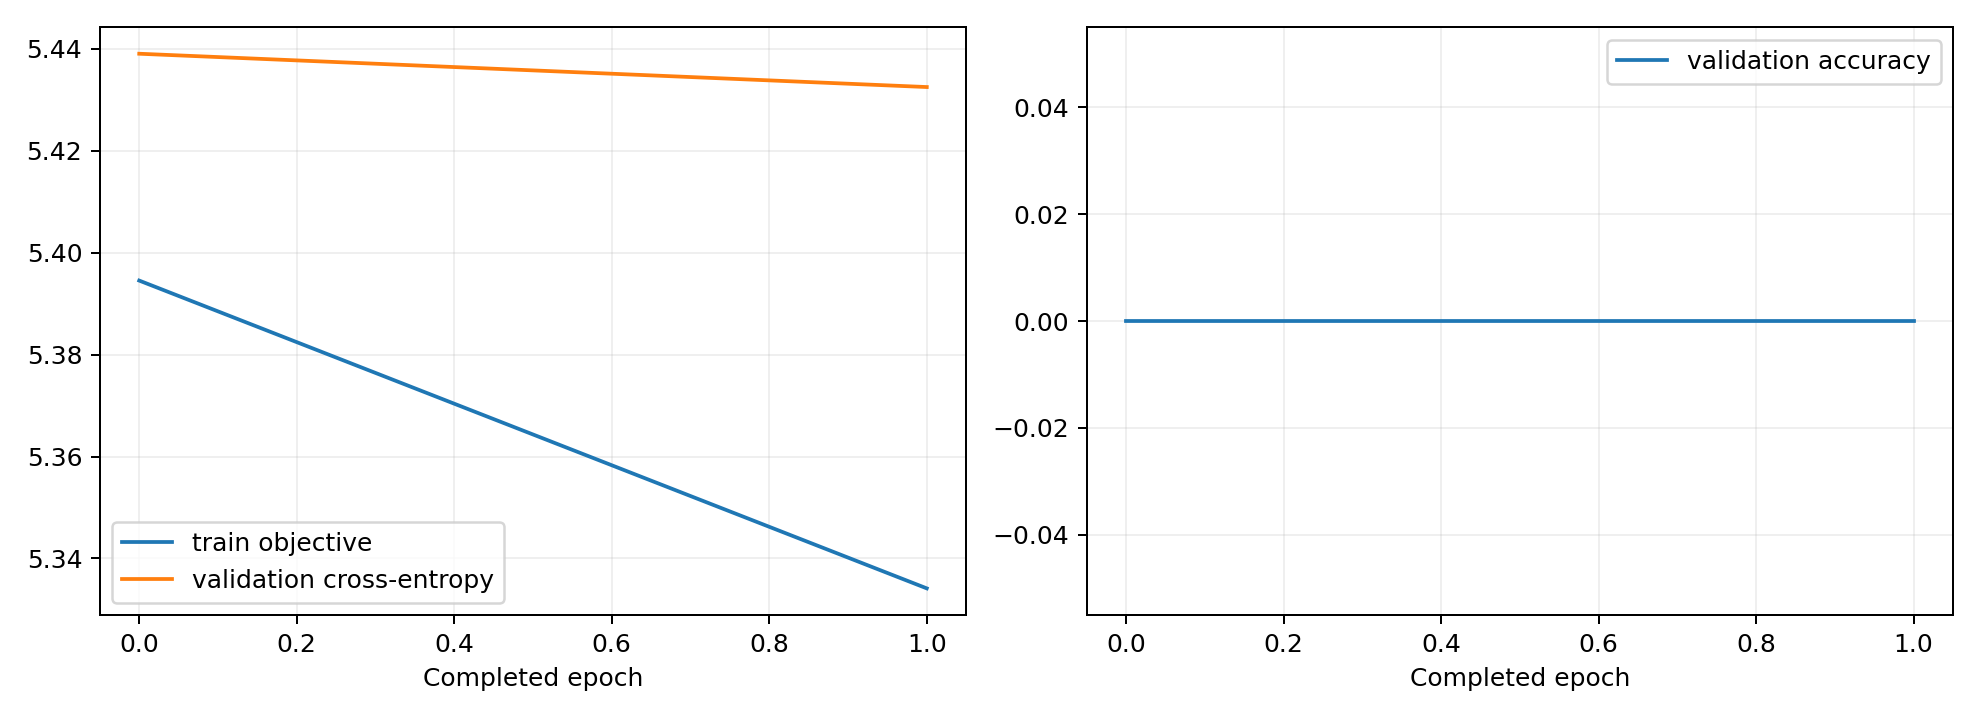

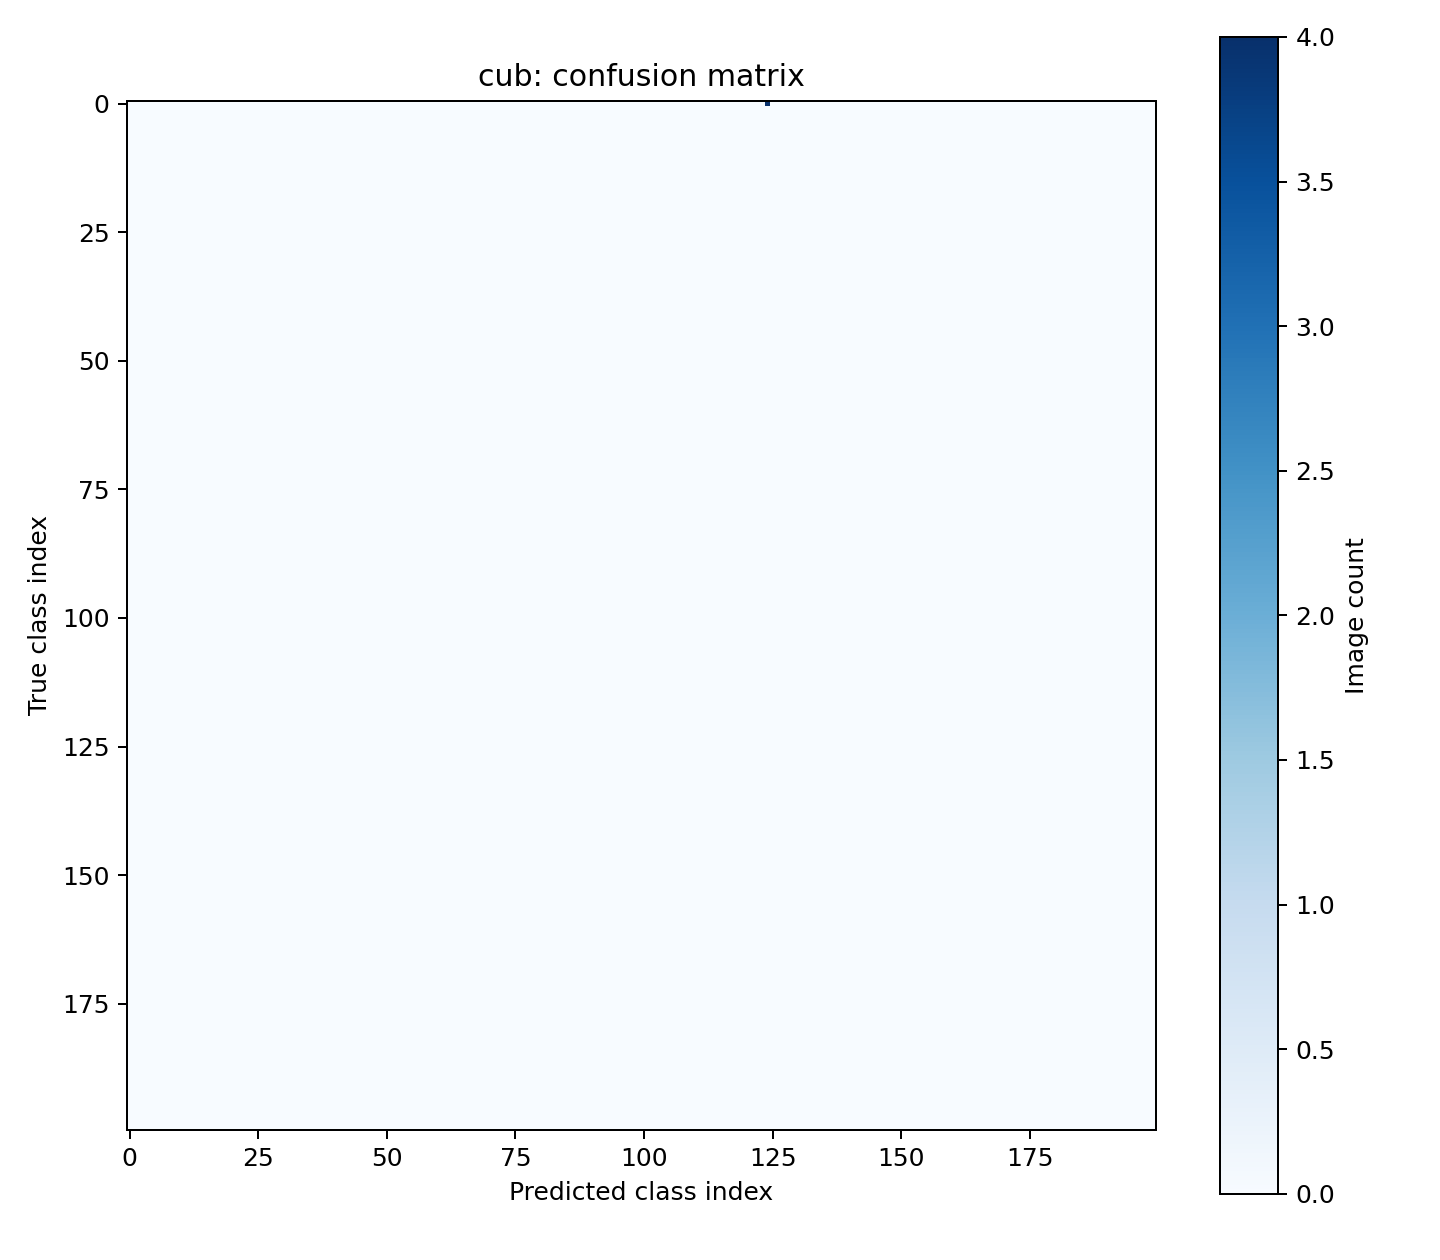

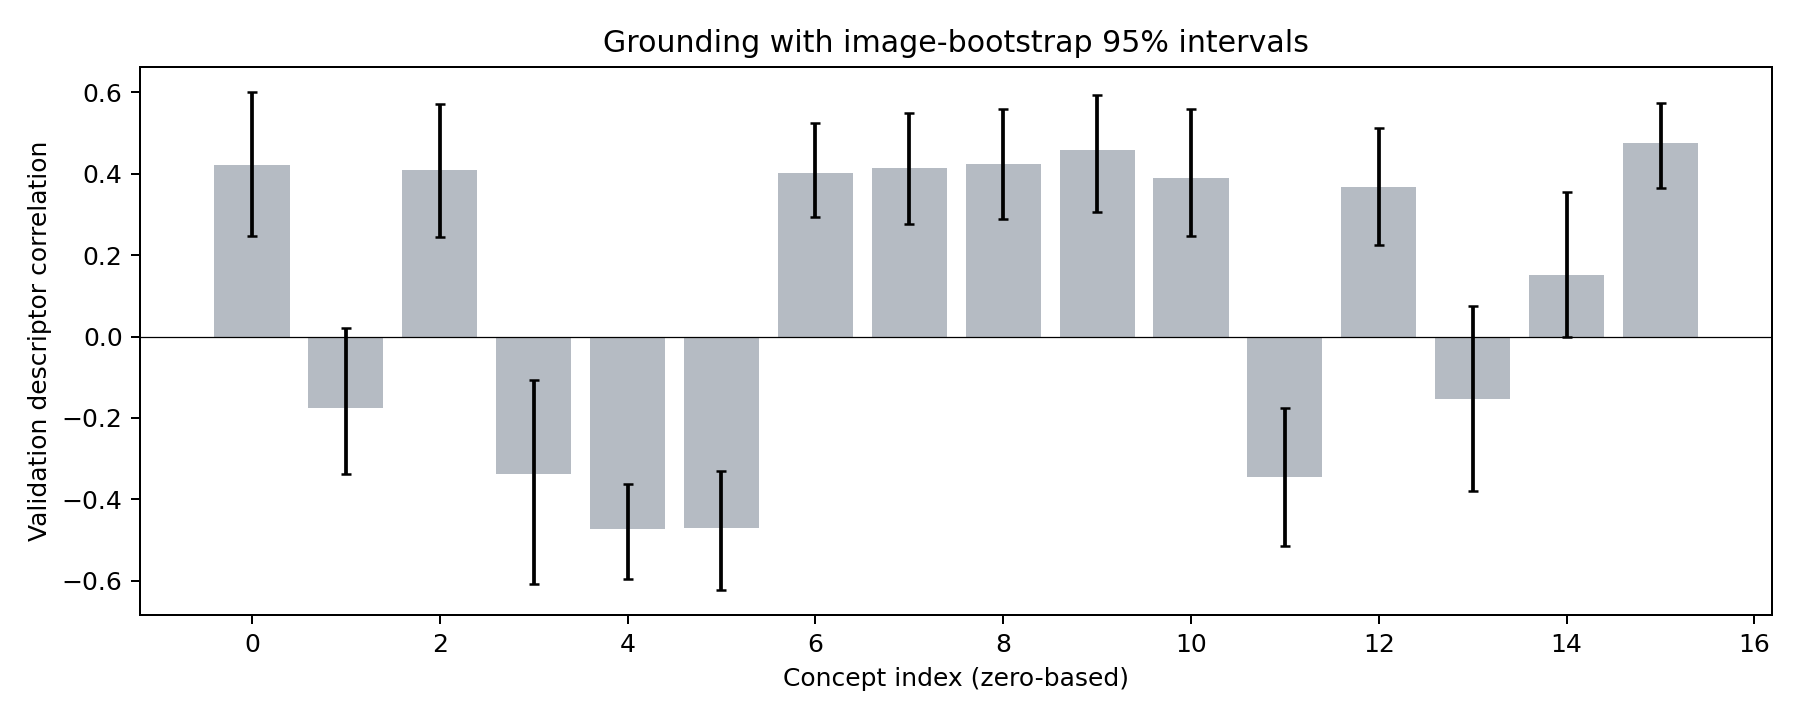

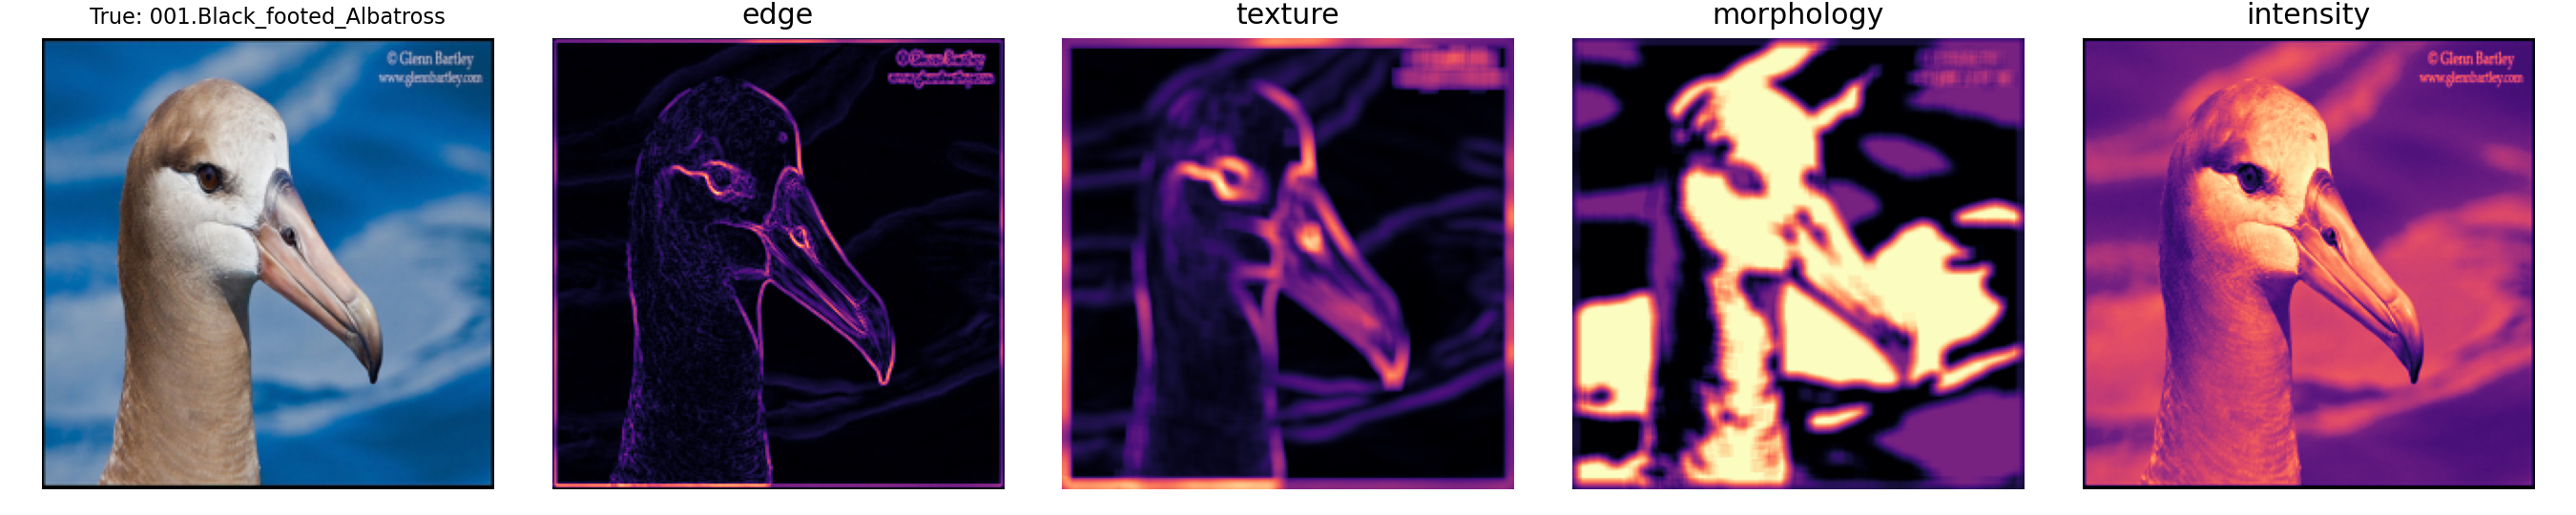

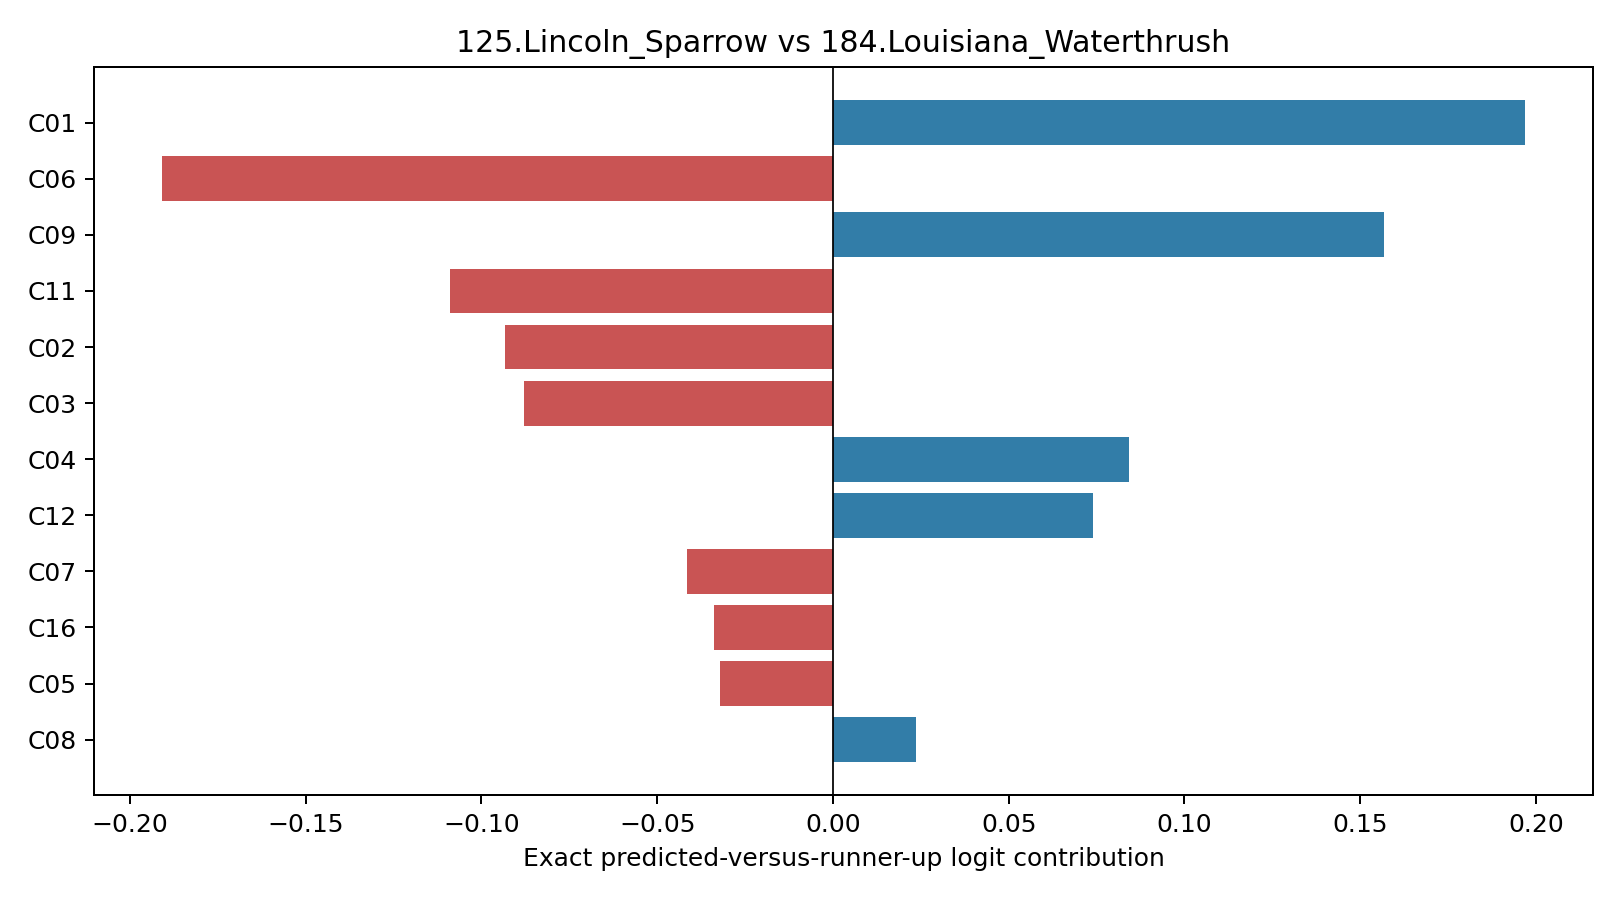

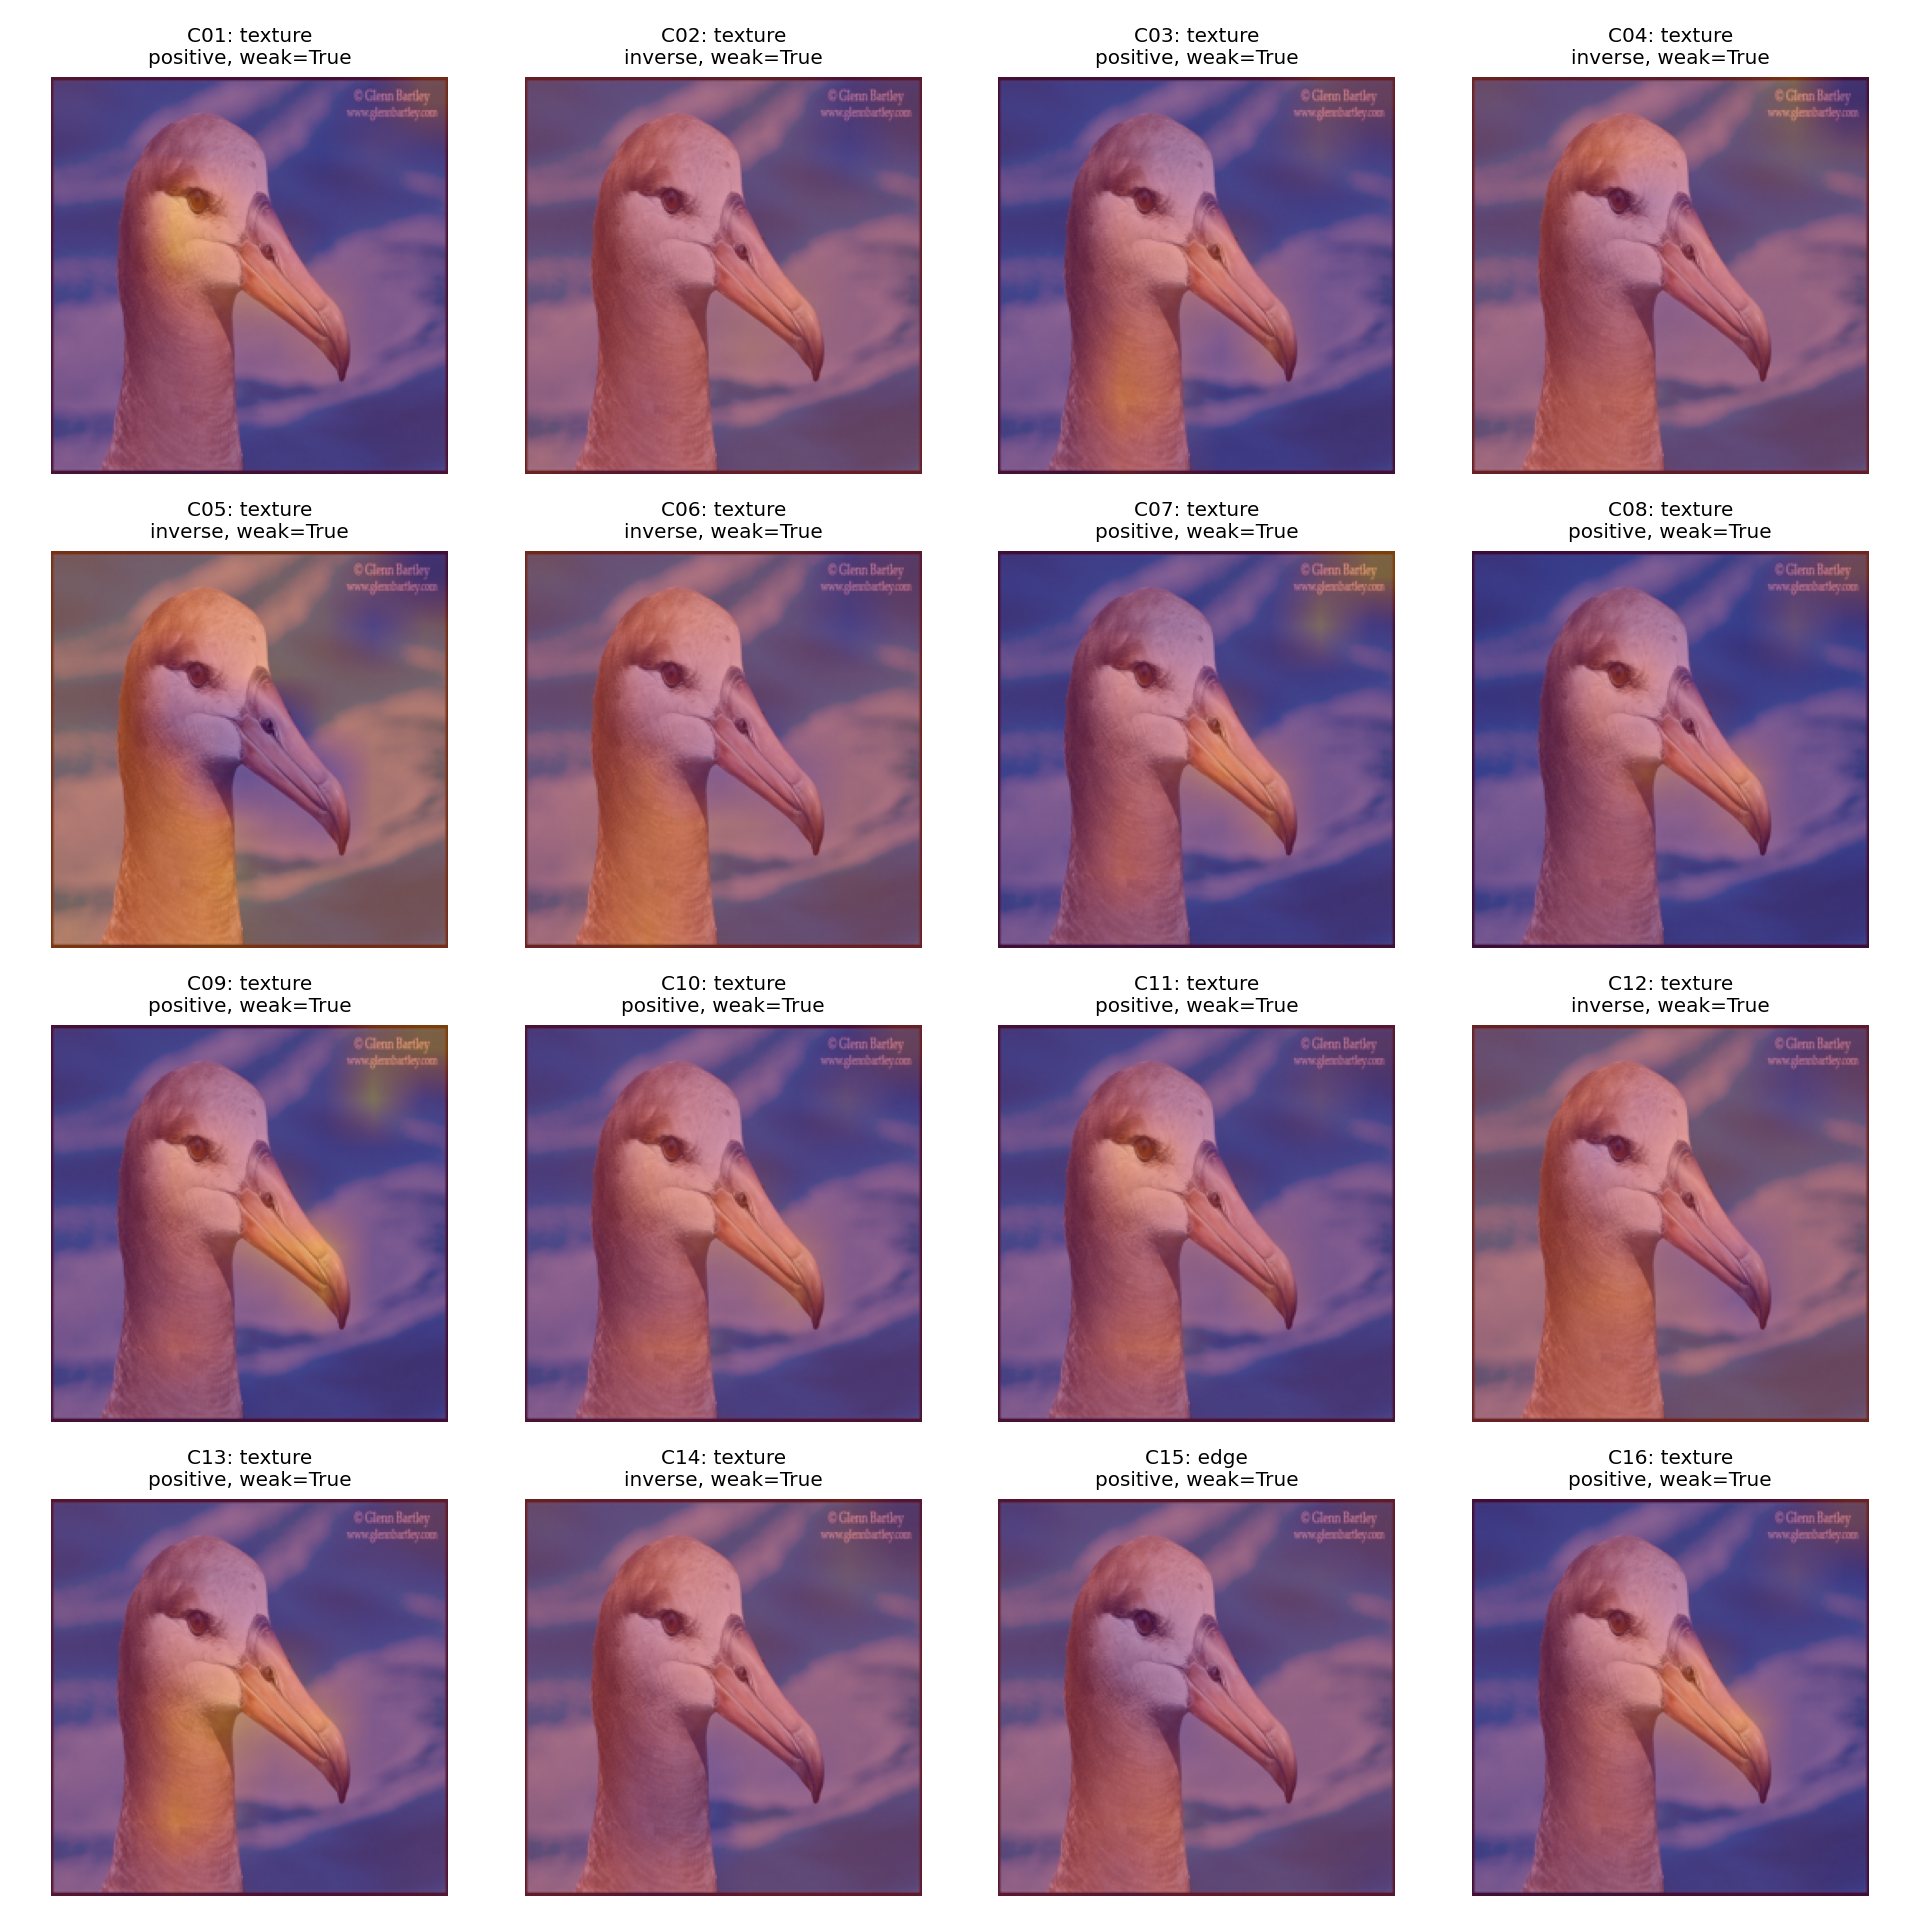

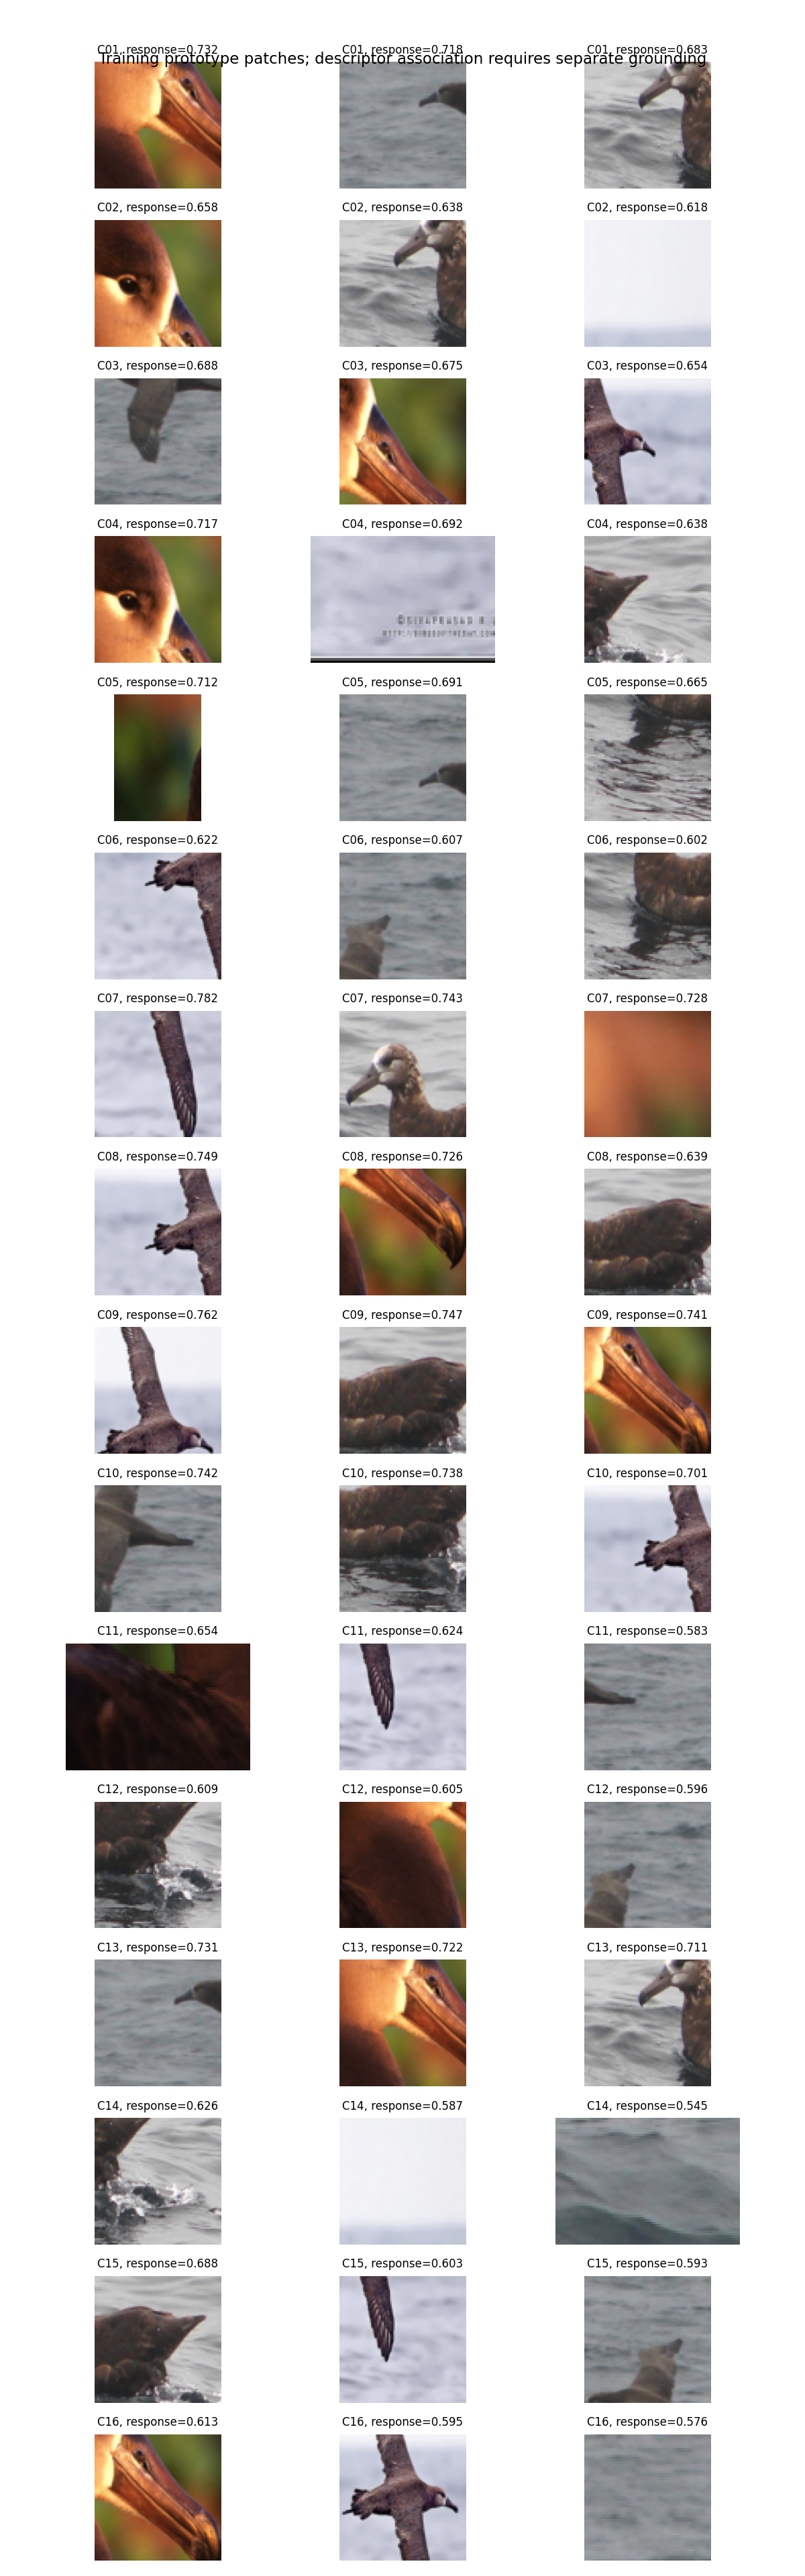

In [11]:
from rgcbm.visualize import visualize_run
from IPython.display import display, Image as DisplayImage
FIGURES = RUN_DIR / 'figures' if PIPELINE_CACHED else visualize_run(model, ROOT, manifest, RUN_DIR, grounding, examples=3,
                        prototype_batches=2 if SMOKE_TEST else None)
for name in ['learning_curves.png', 'confusion_matrix.png', 'grounding_uncertainty.png',
             'case_00_priors.png', 'case_00_contributions.png', 'case_00_concept_maps.png', 'prototype_patches.png']:
    display(DisplayImage(filename=str(FIGURES / name)))


Text explanations consume exact model evidence only. The deterministic template always works offline. Local Qwen loads included files with `local_files_only=True`; Gemini requires secure runtime credentials. Structure/sign checks cannot prove that generated prose is hallucination-free.

In [12]:
from rgcbm.reports import generate_reports
if DEVICE == 'cuda': torch.cuda.empty_cache()
reports = generate_reports(RUN_DIR, ROOT / 'assets', backend=LLM_BACKEND, max_cases=3, llm_device=LLM_DEVICE)
for report in reports:
    print(report['result']['explanation'])
    print('Backend:', report['backend_used'], 'fallback:', report['fallback_reason'])
if SYNC_CALLBACK is not None: SYNC_CALLBACK(RUN_DIR)
print('All saved results:', RUN_DIR)


The model predicted 125.Lincoln_Sparrow with an uncalibrated probability of 0.011; the runner-up was 184.Louisiana_Waterthrush. Supporting model patterns: C01: weakly grounded visual pattern (margin contribution +0.1968); C09: weakly grounded visual pattern (margin contribution +0.1568); C04: weakly grounded visual pattern (margin contribution +0.0841)
Backend: template fallback: None
The model predicted 125.Lincoln_Sparrow with an uncalibrated probability of 0.011; the runner-up was 184.Louisiana_Waterthrush. Supporting model patterns: C01: weakly grounded visual pattern (margin contribution +0.1964); C09: weakly grounded visual pattern (margin contribution +0.1567); C04: weakly grounded visual pattern (margin contribution +0.0842)
Backend: template fallback: None
The model predicted 125.Lincoln_Sparrow with an uncalibrated probability of 0.011; the runner-up was 184.Louisiana_Waterthrush. Supporting model patterns: C01: weakly grounded visual pattern (margin contribution +0.1968); C0

## Research run checklist

Repeat complete experiments with seeds 42/43/44 and report mean ± standard deviation. Re-run
baselines on the same full splits, backbone/pretraining, compute budget and selection rule.
Run guidance/stability/diversity ablations and K=16/32/64 using new run names. Existing manuscript
numbers must not be reused for this implementation. Independent attribute/part or human studies
are needed before describing these low-level descriptors as high-level semantic concepts.


## Concept evidence cards: names, uncertainty and domain limits

These cards show each frozen descriptor name, validation confidence interval, held-out association,
classifier use and domain limitations. Weak concepts remain weak. Review several prototype patches
and held-out maps before using a higher-level label; a class weight cannot name a bird part or diagnosis.


In [13]:
from rgcbm.journal import concept_cards, DOMAIN_SCOPE
print(DOMAIN_SCOPE[DATASET])
concept_card_table = concept_cards(manifest, RUN_DIR, grounding)
display(concept_card_table[['id', 'name', 'group', 'weak_grounding',
                           'validation_correlation', 'validation_image_bootstrap_95ci']])
print('Saved concept_cards.json and concept_cards.md')


Bird species classification. Edge/texture/region associations alone do not establish a wing, bill, plumage color or anatomical part. Attribute-assisted labels require the separately reported annotation audit.


,id,name,group,weak_grounding,validation_correlation,validation_image_bootstrap_95ci
0,C01,C01: weakly grounded visual pattern,boundary-guided,True,0.422391,"[0.2466825395822525, 0.6009646654129028]"
1,C02,C02: weakly grounded visual pattern,boundary-guided,True,-0.176396,"[-0.33743414655327797, 0.02165897935628891]"
2,C03,C03: weakly grounded visual pattern,boundary-guided,True,0.408771,"[0.24479156732559204, 0.5727988421916962]"
3,C04,C04: weakly grounded visual pattern,boundary-guided,True,-0.337132,"[-0.6097284570336342, -0.10792803075164549]"
4,C05,C05: weakly grounded visual pattern,texture-guided,True,-0.472480,"[-0.5958560705184937, -0.3631802797317505]"
5,C06,C06: weakly grounded visual pattern,texture-guided,True,-0.470566,"[-0.6237561106681824, -0.33028554916381836]"
6,C07,C07: weakly grounded visual pattern,texture-guided,True,0.402932,"[0.29367291927337646, 0.5255519151687622]"
7,C08,C08: weakly grounded visual pattern,texture-guided,True,0.413431,"[0.27710628509521484, 0.5497561693191528]"
8,C09,C09: weakly grounded visual pattern,region-prior-guided,True,0.424902,"[0.2878704071044922, 0.5604743242263795]"
9,C10,C10: weakly grounded visual pattern,region-prior-guided,True,0.458519,"[0.3053446412086487, 0.5933504700660706]"


Saved concept_cards.json and concept_cards.md


## Reliability and concept redundancy

Reliability plots expose confidence errors; confidence is not correctness. Concept-correlation
plots and effective rank identify redundancy/collapse. Blank entries mean insufficient variation.


,bin_low,bin_high,n,mean_confidence,observed_accuracy
0,0.0,0.066667,4,0.011158,0.0


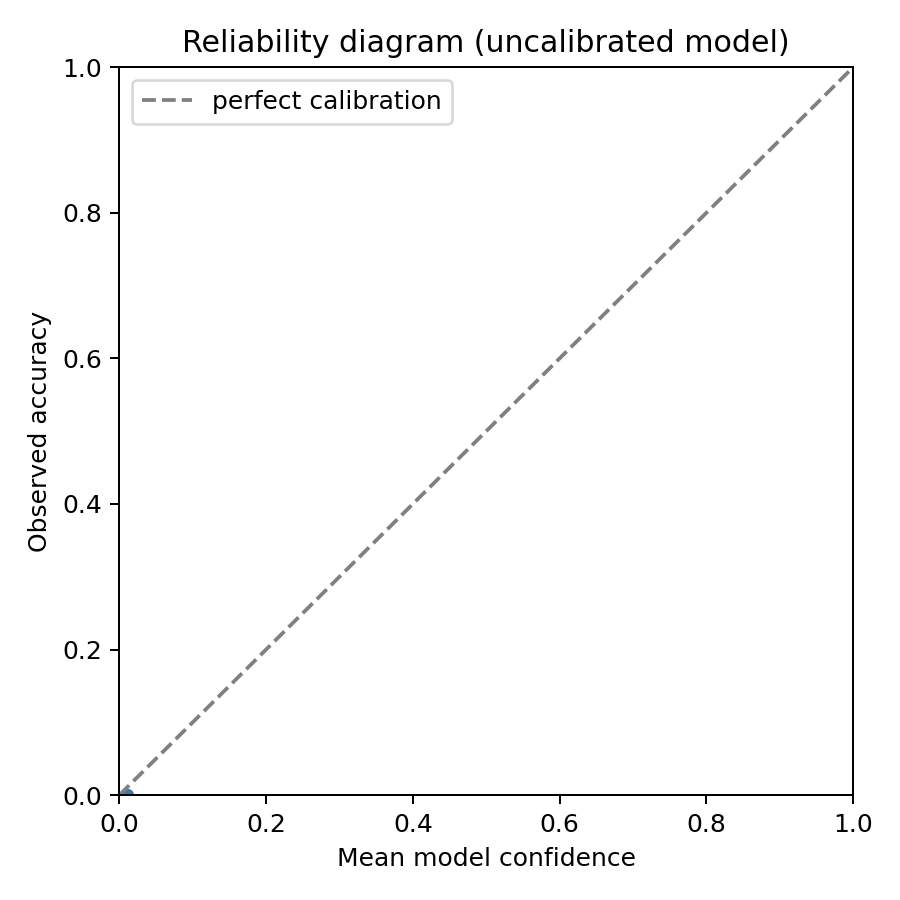

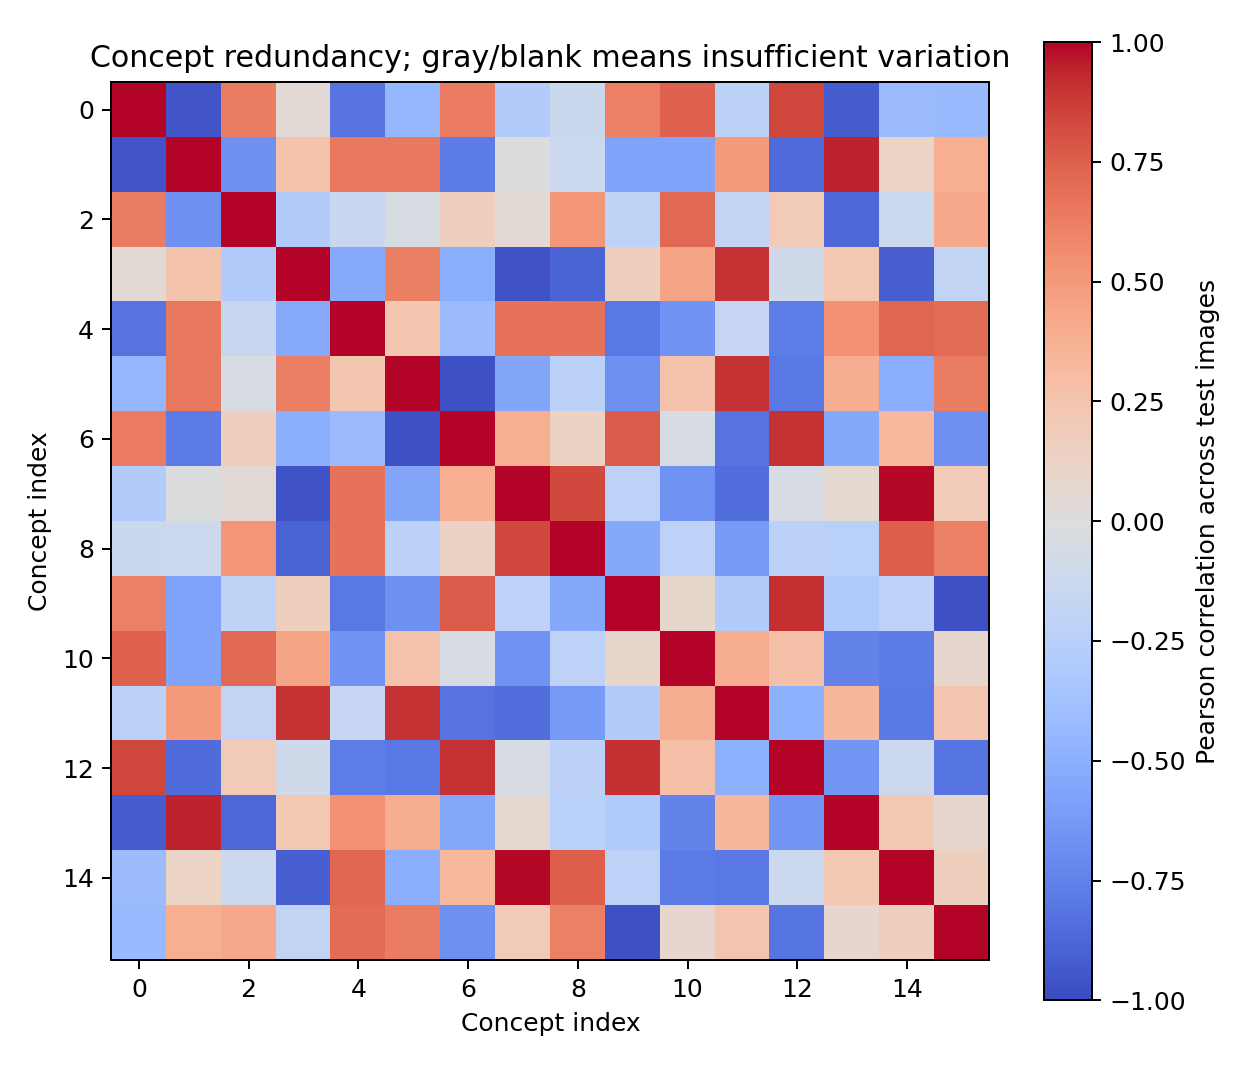

In [14]:
from rgcbm.journal import reliability_and_redundancy
reliability_table = reliability_and_redundancy(RUN_DIR)
display(reliability_table)
for filename in ['reliability_diagram.png', 'concept_redundancy.png']:
    if (FIGURES / filename).exists(): display(DisplayImage(filename=str(FIGURES / filename)))


## Manual latent-concept intervention

Edit the dictionary and rerun. This changes the concept vector, not the physical image, anatomy,
pet appearance or tumor. Exact logit changes are checked. Compare all class probabilities;
margin-supporting concepts need not increase probability relative to every other class.


In [15]:
from rgcbm.data import ImageDataset
from rgcbm.journal import intervention
example_dataset = ImageDataset(ROOT, manifest, 'test', cfg)
EXAMPLE_INDEX = 0
EDITED_CONCEPTS = {0: 0.0}  # ZERO-BASED concept index -> activation in [0,1].
# For standardized scores, 0.5 is the estimated training-mean response; 0 is an
# extreme latent clamp, not evidence that a visible object part has disappeared.
example_image, _, _ = example_dataset[EXAMPLE_INDEX]
edited_table = intervention(model, example_image, grounding, manifest['classes'], EDITED_CONCEPTS)
edited_table.to_csv(RUN_DIR / 'manual_intervention.csv', index=False)
display(edited_table.head(10))
import matplotlib.pyplot as plt
top = edited_table.head(5).set_index('class')
ax = top[['original_probability', 'edited_probability']].plot.barh(figsize=(8,4))
ax.set_title('Latent intervention; image and classifier weights unchanged')
ax.set_xlabel('Uncalibrated model probability')
plt.tight_layout(); plt.savefig(FIGURES / 'manual_intervention.png', dpi=180); plt.show()


,class,original_probability,edited_probability,probability_change,exact_logit_change
183,184.Louisiana_Waterthrush,0.010150,0.011678,0.001528,0.135865
124,125.Lincoln_Sparrow,0.011155,0.010542,-0.000614,-0.060981
147,148.Green_tailed_Towhee,0.009320,0.008474,-0.000846,-0.099529
33,034.Gray_crowned_Rosy_Finch,0.008938,0.008332,-0.000606,-0.074575
143,144.Common_Tern,0.008464,0.008323,-0.000141,-0.021219
109,110.Geococcyx,0.008226,0.008316,0.000090,0.006433
28,029.American_Crow,0.008278,0.008167,-0.000112,-0.017975
48,049.Boat_tailed_Grackle,0.006975,0.008076,0.001101,0.142202
165,166.Golden_winged_Warbler,0.007904,0.008075,0.000171,0.016948
186,187.American_Three_toed_Woodpecker,0.008212,0.008005,-0.000207,-0.029926


## Matched concept-deletion curves

Compare positive margin-supporting concepts with random edits on identical eligible images per
removal count. Tables include sample counts and paired bootstrap intervals. This measures model
dependence, not causal image explanation.


,removed_concepts,matched_n,support_probability_drop,support_ci_low,support_ci_high,random_probability_drop,random_ci_low,random_ci_high,paired_difference,paired_ci_low,paired_ci_high
0,1,4,0.000614,0.000613,0.000616,0.000564,0.000173,0.001175,0.000051,-0.000560,0.000440
1,2,4,0.001877,0.001875,0.001879,0.000779,-0.000244,0.001394,0.001098,0.000484,0.002121
2,3,4,0.002524,0.002523,0.002525,0.001211,0.000570,0.001853,0.001313,0.000671,0.001954
3,4,4,0.003667,0.003665,0.003669,0.002310,0.001609,0.002965,0.001357,0.000701,0.002056


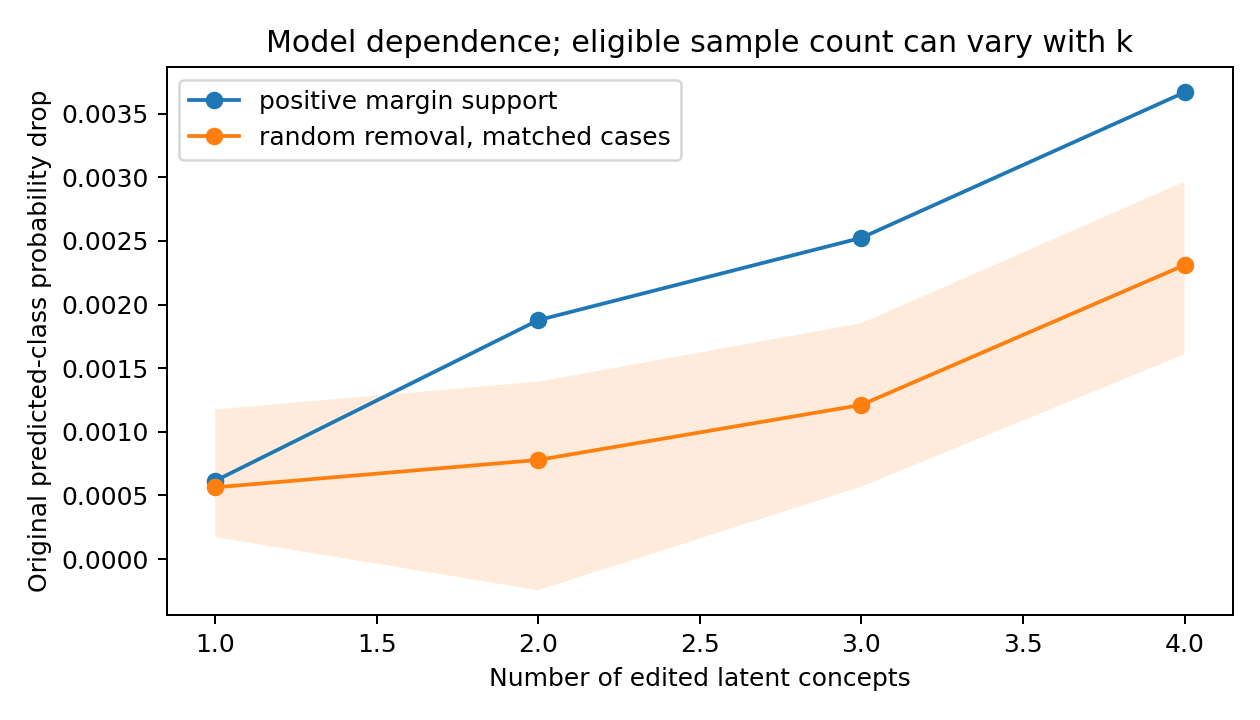

In [16]:
from rgcbm.journal import deletion_curves
deletion_table = deletion_curves(model, RUN_DIR, max_k=4)
display(deletion_table)
if (FIGURES / 'deletion_curves.png').exists():
    display(DisplayImage(filename=str(FIGURES / 'deletion_curves.png')))


## Optional CUB semantic-attribute audit

This separately disclosed **annotation-assisted, post-training** audit uses original CUB attributes
with certainty >=3. A provisional name requires validation n>=50, |r|>=0.2 and a 312×K multiple-
comparison correction. Its frozen attribute is tested with held-out AUC. Test never renames concepts.
No concept labels train the model. An attribute association does not establish spatial part identity.
If evidence is weak, preserve the descriptor/weak name instead of inventing semantics.


In [17]:
from rgcbm.journal import cub_attribute_audit
RUN_CUB_ATTRIBUTE_AUDIT = True
if RUN_CUB_ATTRIBUTE_AUDIT and DATASET == 'cub':
    attribute_table = cub_attribute_audit(model, ROOT, manifest, RUN_DIR,
                                         max_batches=2 if SMOKE_TEST else None)
    display(attribute_table)
    print('Validation-selected annotation-assisted associations saved separately.')
else:
    print('Optional CUB attribute audit is disabled or not applicable to this dataset.')


,concept_index,provisional_annotation_assisted_name,status
0,0,None,insufficient validation evidence; keep descrip...
1,1,None,insufficient validation evidence; keep descrip...
2,2,None,insufficient validation evidence; keep descrip...
3,3,None,insufficient validation evidence; keep descrip...
4,4,None,insufficient validation evidence; keep descrip...
5,5,None,insufficient validation evidence; keep descrip...
6,6,None,insufficient validation evidence; keep descrip...
7,7,None,insufficient validation evidence; keep descrip...
8,8,None,insufficient validation evidence; keep descrip...
9,9,None,insufficient validation evidence; keep descrip...


Validation-selected annotation-assisted associations saved separately.


## Runtime/parameter profile and provenance

Measure on the actual GPU. Warmed classifier inference is separate from training and LLM latency.
Device/version, parameters and peak CUDA memory are saved; full seeds are needed for paper claims.


In [18]:
from rgcbm.journal import profile_inference
profile = profile_inference(model, example_image, RUN_DIR, repeats=20)
display(pd.DataFrame([profile]).T)
atomic_json(RUN_DIR / 'pipeline_status.json', {'complete': True,
            'fingerprint': json.loads((RUN_DIR / 'configuration.json').read_text())['fingerprint'],
            'llm_backend': LLM_BACKEND, 'protocol': 'calibrated_v3'})
if SYNC_CALLBACK is not None: SYNC_CALLBACK(RUN_DIR)
print('Journal-facing evidence and figures saved:', RUN_DIR)


,0
device,cpu
torch,2.7.1+cpu
cuda,None
batch_size,1
precision,FP32
repeats,20
median_latency_ms,31.07787
p95_latency_ms,81.904634
parameters,6682728
trainable_parameters_current_stage,5437668


Journal-facing evidence and figures saved: /tmp/rgcbm-v3-cloud-release/kaggle/results/cub_K16_seed42_calibrated_v3_cloud_validation_kaggle_smoke


## Automatic sequential dataset queue

With RUN_ALL_DATASETS=True, this cell resumes the completed first model, reuses its saved evidence,
then prepares/trains/evaluates each remaining dataset. Each receives independent checkpoints,
learning curves, concept cards, reports and journal figures. A summary CSV, status JSON and chart
are saved alongside the runs and synchronized to configured Drive storage. Restart with the same
configuration to resume. Dataset failures are recorded and the queue continues; inspect failed rows.



Dataset 1/3: cub -> cub_K16_seed42_calibrated_v3_cloud_validation_kaggle_smoke


Preparation completed; transfer the full bundle, not just the notebook.


Reusing completed evaluation and explanation outputs: /tmp/rgcbm-v3-cloud-release/kaggle/results/cub_K16_seed42_calibrated_v3_cloud_validation_kaggle_smoke



Dataset 2/3: pets -> pets_K16_seed42_calibrated_v3_cloud_validation_kaggle_smoke


Preparation completed; transfer the full bundle, not just the notebook.


...

Evaluating frozen model on test: brain_mri


Saving figures, evidence reports and journal audits: brain_mri


/workspace/rgcbm-research/py313-env/lib/python3.13/site-packages/sklearn/metrics/_classification.py:409: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


,dataset,run,status,classes,best_validation_accuracy,software_smoke_only,n_test_evaluated,n_test_available,complete_test,accuracy,...,random_probability_drop_mean,legacy_absolute_probability_drop_mean,stability_mae,stability_cosine,warning,concept_effective_rank,mean_absolute_interconcept_correlation,matched_top_minus_random_drop,mean_foreground_mass_to_area_ratio,peak_in_foreground_rate
0,cub,cub_K16_seed42_calibrated_v3_cloud_validation_...,complete,200,0.0,True,4,5794,False,0.0,...,0.000564,0.001461,0.000084,1.0,Latent concept ablation measures model depende...,2.616843,0.486026,0.000051,1.036033,0.734375
1,pets,pets_K16_seed42_calibrated_v3_cloud_validation...,complete,37,0.0,True,4,3669,False,0.0,...,0.003706,0.007400,0.000133,1.0,Latent concept ablation measures model depende...,2.413674,0.517584,0.005025,0.976869,0.250000
2,brain_mri,brain_mri_K16_seed42_calibrated_v3_cloud_valid...,complete,4,1.0,True,4,1600,False,1.0,...,-0.013439,-0.039518,0.000285,1.0,Latent concept ablation measures model depende...,1.305346,0.826767,0.049253,NaN,NaN


Combined queue status, CSV and chart: /tmp/rgcbm-v3-cloud-release/kaggle/results/dataset_suite_calibrated_v3_cloud_validation_kaggle_K16_seed42_smoke


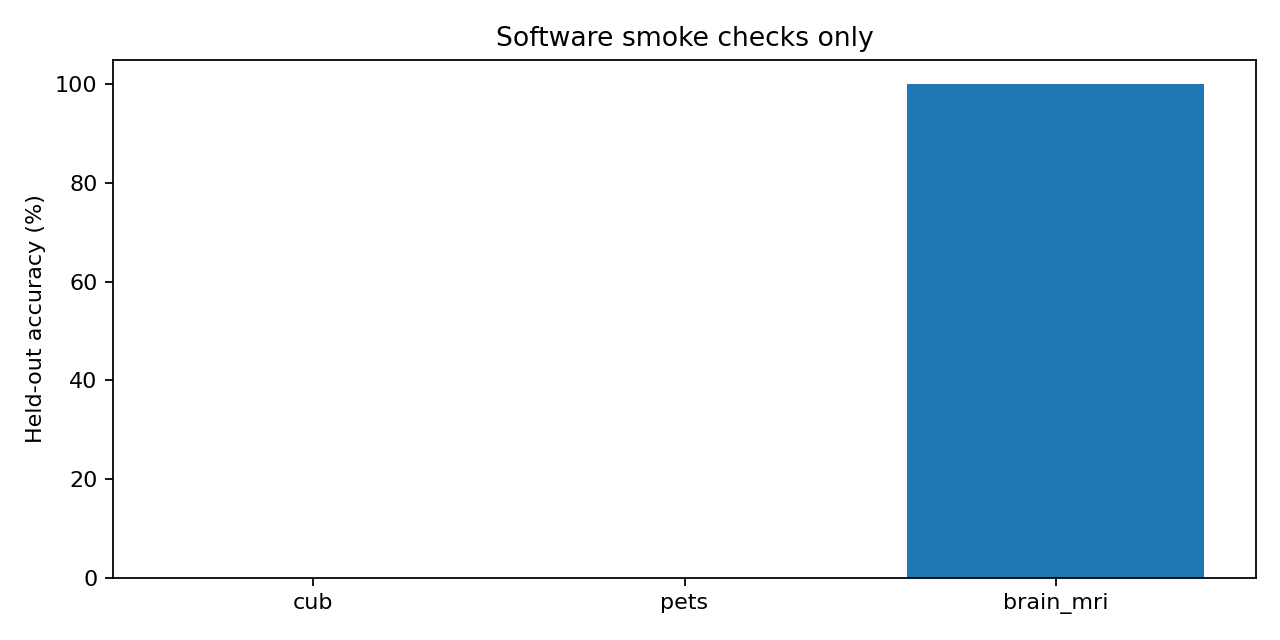

In [19]:
from rgcbm.suite import run_dataset_suite
def prepare_queued_dataset(dataset, run_name):
    if 'Kaggle' == 'Colab':
        target = ROOT / 'data' / f'{dataset}.zip'
        source = DRIVE_ROOT / 'datasets' / target.name
        if not target.exists() and source.exists(): shutil.copy2(source, target)
    elif 'Kaggle' == 'Kaggle' and DRIVE is not None:
        DRIVE.ensure_dataset(ROOT, dataset)
        DRIVE.restore_run(ROOT, run_name)
    if ONLINE:
        command = [sys.executable, str(CODE_ROOT / 'prepare_assets.py'), '--root', str(ROOT), '--datasets', dataset]
        if LLM_BACKEND == 'local_qwen': command.append('--llm')
        subprocess.check_call(command)
    else:
        prepare_data(ROOT, dataset, online=False)
    if 'Kaggle' == 'Colab':
        archive = ROOT / 'data' / f'{dataset}.zip'
        if not (DRIVE_ROOT / 'datasets' / archive.name).exists():
            shutil.copy2(archive, DRIVE_ROOT / 'datasets' / archive.name)
    elif 'Kaggle' == 'Kaggle' and DRIVE is not None:
        DRIVE.sync_assets(ROOT, include_llm=LLM_BACKEND == 'local_qwen')

if RUN_ALL_DATASETS:
    model.cpu()  # Keep the preview model available, release its GPU allocation for the queue.
    dataset_summary = run_dataset_suite(ROOT, DATASETS, cfg, run_tag=RUN_TAG,
                         device=DEVICE, prepare_callback=prepare_queued_dataset,
                         sync_callback=SYNC_CALLBACK, llm_backend=LLM_BACKEND,
                         llm_device=LLM_DEVICE, continue_on_error=True)
    display(dataset_summary)
    suite_dir = ROOT / 'results' / (f'dataset_suite_{RUN_TAG}_K{cfg.concepts}_seed{cfg.seed}' + ('_smoke' if SMOKE_TEST else ''))
    print('Combined queue status, CSV and chart:', suite_dir)
    if (suite_dir / 'dataset_accuracy.png').exists():
        display(DisplayImage(filename=str(suite_dir / 'dataset_accuracy.png')))
    if not (dataset_summary.status == 'complete').all():
        print('Some datasets failed. Inspect queue_status.json and dataset error files; successful models are retained.')
else:
    print('Single-dataset mode: only the detailed DATASET run was requested.')


## Ablation study — optional experiment sweep

Each variant receives a separate checkpoint and run directory. The dataset, pretrained backbone,
selection policy and training budget are held fixed; each requested seed rebuilds its reproducible
validation split. The no-fine-tuning variant intentionally removes stage two. Test scores are final
measurements, not tuning feedback. Use at least three complete seeds for mean/std claims. Smoke mode
produces software checks only. Set RUN_ABLATIONS=True deliberately to start this potentially long sweep.


In [20]:
from rgcbm.ablations import run_ablation_suite, VARIANTS
RUN_ABLATIONS = False
ABLATION_VARIANTS = ['full', 'unguided', 'no_edge', 'no_texture', 'no_region',
                     'no_diversity', 'no_decorrelation', 'no_stability',
                     'no_sparsity', 'no_finetune', 'no_standardization', 'K32', 'K64']
ABLATION_SEEDS = [42, 43, 44]  # Use [42] only for exploratory checks, not uncertainty claims.
ABLATION_DATASETS = DATASETS if RUN_ALL_DATASETS else [DATASET]
if RUN_ABLATIONS:
    from dataclasses import replace
    for ablation_dataset in ABLATION_DATASETS:
        ablation_cfg = replace(cfg, dataset=ablation_dataset)
        ablation_table = run_ablation_suite(ROOT, ablation_cfg, variants=ABLATION_VARIANTS,
                                       seeds=ABLATION_SEEDS, device=DEVICE,
                                       sync_callback=SYNC_CALLBACK)
        display(ablation_table[['variant', 'seed', 'concepts', 'software_smoke_only',
                            'accuracy', 'macro_f1', 'stability_mae']])
        profile_name = 'calibrated_v3' if cfg.concept_normalization == 'running_standardize' else 'legacy'
        summary_path = ROOT / 'results' / f'{ablation_dataset}_ablation_summary_{profile_name}'
        print('Per-run and mean/std CSVs saved:', summary_path)
else:
    print('Ablation code is ready. Set RUN_ABLATIONS=True to execute the selected variants.')


Ablation code is ready. Set RUN_ABLATIONS=True to execute the selected variants.
